# Melbourne Housing Snapshot analysis notebook

**Original project period:** January 2023 – June 2023  
**Technical revision and GitHub preparation:** November 2026  
**Source transaction period:** January 2016 – September 2017

*This notebook preserves the original 2023 exploratory study and its presentation. The November 2026 revision updated execution compatibility, preprocessing, validation, and documentation. The corrected model results shown below are from the 2026 rerun, not historical 2023 results.*

## 1. Importing

### Importing the necessary library to be used

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

All the required libraries for the project should be first imported to the workspace to conduct a smooth analysis on the selected dataset without any downflows.

### Importing the dataset from the CSV file 

In [2]:
# Load the supplied Melbourne Housing Snapshot CSV from the notebook's working folder.
# The CSV is already a pandas DataFrame after read_csv; it must not be read twice.
from pathlib import Path
candidate_csv_paths = [
    Path('melb_data.csv'),
    Path('data') / 'melb_data.csv',
    Path('..') / 'data' / 'melb_data.csv',
]
csv_path = next((path for path in candidate_csv_paths if path.is_file()), None)
if csv_path is None:
    raise FileNotFoundError('Download melb_data.csv from Kaggle and place it in data/ or beside the notebook.')
data = pd.read_csv(csv_path)

# Check data dimensions
data.shape

(13580, 21)

Through "data.shape" function the number of rows and columns available in the dataset is displayed. Our dataset has 13580 rows and 21 columns.

### Variable details

- Suburb: Suburb

- Address: Address

- Rooms: Number of rooms

- Price: Price in Australian dollars

- Method:
    - S - property sold;
    - SP - property sold prior;
    - PI - property passed in;
    - PN - sold prior not disclosed;
    - SN - sold not disclosed;
    - NB - no bid;
    - VB - vendor bid;
    - W - withdrawn prior to auction;
    - SA - sold after auction;
    - SS - sold after auction price not disclosed.
    - N/A - price or highest bid not available.

- Type:
    - br - bedroom(s);
    - h - house, cottage, villa, semi, terrace;
    - u - unit, duplex;
    - t - townhouse;
    - dev site - development site;
    - o res - other residential.

- SellerG: Real Estate Agent

- Date: Date sold

- Distance: Distance from Central Business District in Kilometres

- Regionname: General Region (West, North West, North, North east …etc)

- Propertycount: Number of properties that exist in the suburb.

- Bedroom2 : Scraped number of of Bedrooms (from different source)

- Bathroom: Number of Bathrooms

- Car: Number of carspots

- Landsize: Land Size in Square Metres

- BuildingArea: Building Size in Square Metres

- YearBuilt: Year the house was built

- CouncilArea: Governing council for the area

- Lattitude: Self-explanitory

- Longtitude: Self-explanitory

Source: https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot

Dataset attribution: DanB, *Melbourne Housing Snapshot* (derived from Tony Pino's Melbourne housing data), Kaggle, CC BY-NC-SA 4.0. The dataset and original author are acknowledged; the source records have not been claimed as original work.

## 2. Initial data exploration

### 2.1. Overview of the data

In [3]:
# see the first ten rows
data.head(10)

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0
5,Abbotsford,129 Charles St,2,h,941000.0,S,Jellis,7/05/2016,2.5,3067.0,2.0,1.0,0.0,181.0,NaN,NaN,Yarra,-37.8041,144.9953,Northern Metropolitan,4019.0
6,Abbotsford,124 Yarra St,3,h,1876000.0,S,Nelson,7/05/2016,2.5,3067.0,4.0,2.0,0.0,245.0,210.0,1910.0,Yarra,-37.8024,144.9993,Northern Metropolitan,4019.0
7,Abbotsford,98 Charles St,2,h,1636000.0,S,Nelson,8/10/2016,2.5,3067.0,2.0,1.0,2.0,256.0,107.0,1890.0,Yarra,-37.8060,144.9954,Northern Metropolitan,4019.0
8,Abbotsford,6/241 Nicholson St,1,u,300000.0,S,Biggin,8/10/2016,2.5,3067.0,1.0,1.0,1.0,0.0,NaN,NaN,Yarra,-37.8008,144.9973,Northern Metropolitan,4019.0
9,Abbotsford,10 Valiant St,2,h,1097000.0,S,Biggin,8/10/2016,2.5,3067.0,3.0,1.0,2.0,220.0,75.0,1900.0,Yarra,-37.8010,144.9989,Northern Metropolitan,4019.0


- The names are not consistent with the CapitalizedWords naming style, e.g., they did not capitalise the word Name in Regionname
- Some names are not very descriptive, e.g. Date or Distance
- Some names have spelling errors 
- In addition, the use of area may be confusing (refer to size in BuildingArea and region in CouncilArea)

### 2.2. Renaming some columns

In [4]:
data = data.rename(columns={"Method": "MethodSold",
                     "SellerG":"Agent",
                     "Date":"DateSold",
                     "Distance":"DistanceCBD",
                     "Bedroom2":"Bedroom",
                     "Landsize":"LandSize",
                     "BuildingArea":"BuildingSize",
                     "CouncilArea":"Council",
                     "Lattitude":"Latitude",
                     "Longtitude":"Longitude",
                     "Regionname":"Region",
                     "Propertycount":"PropertyCount"
                  })

data.columns

# Preserve original (renamed) records for leakage-safe predictive modelling later.
# Cleaning and imputation in the exploratory sections below will not be used to fit models.
model_source = data.copy(deep=True)

### 2.3. Check if any entry is duplicated

In [5]:
data[data.duplicated()]

,Suburb,Address,Rooms,Type,Price,MethodSold,Agent,DateSold,DistanceCBD,Postcode,Bedroom,Bathroom,Car,LandSize,BuildingSize,YearBuilt,Council,Latitude,Longitude,Region,PropertyCount


In [6]:
data[data.duplicated(subset=["Address", "Postcode"], keep=False)]

,Suburb,Address,Rooms,Type,Price,MethodSold,Agent,DateSold,DistanceCBD,Postcode,Bedroom,Bathroom,Car,LandSize,BuildingSize,YearBuilt,Council,Latitude,Longitude,Region,PropertyCount
39,Airport West,50 Bedford St,3,h,730000.0,VB,Nelson,3/12/2016,13.5,3042.0,3.0,2.0,1.0,0.0,145.0,1965.0,Moonee Valley,-37.72030,144.87550,Western Metropolitan,3464.0
40,Airport West,50 Bedford St,3,h,770000.0,SP,Nelson,4/03/2017,13.5,3042.0,3.0,2.0,1.0,0.0,145.0,1965.0,Moonee Valley,-37.72030,144.87550,Western Metropolitan,3464.0
188,Altona North,21 Hatherley Gr,3,h,750000.0,SP,Jas,4/03/2017,11.1,3025.0,3.0,1.0,3.0,554.0,NaN,NaN,Hobsons Bay,-37.84490,144.85000,Western Metropolitan,5132.0
197,Altona North,21 Hatherley Gr,3,h,700000.0,VB,Jas,10/12/2016,11.1,3025.0,3.0,1.0,3.0,554.0,NaN,NaN,Hobsons Bay,-37.84490,144.85000,Western Metropolitan,5132.0
292,Ascot Vale,75 Maribyrnong Rd,6,h,2425000.0,PI,Brad,4/06/2016,5.9,3032.0,6.0,3.0,2.0,1014.0,435.0,1887.0,Moonee Valley,-37.77210,144.91840,Western Metropolitan,6567.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13370,Brighton East,60 Cummins Rd,3,h,1650000.0,SP,Buxton,26/08/2017,10.3,3187.0,3.0,2.0,2.0,623.0,0.0,1920.0,NaN,-37.92698,145.02673,Southern Metropolitan,6938.0
13371,Brighton East,375 South Rd,5,h,1650000.0,SP,Hodges,26/08/2017,10.3,3187.0,5.0,2.0,5.0,773.0,275.0,1950.0,NaN,-37.93203,145.02844,Southern Metropolitan,6938.0
13421,Footscray,39 Moore St,3,h,755000.0,PI,hockingstuart,26/08/2017,5.1,3011.0,3.0,1.0,2.0,334.0,110.0,1920.0,NaN,-37.79770,144.90398,Western Metropolitan,7570.0
13429,Frankston South,3 Diosma Ct,3,h,1155000.0,S,hockingstuart,26/08/2017,38.0,3199.0,3.0,2.0,2.0,2405.0,242.0,1980.0,NaN,-38.16457,145.12421,South-Eastern Metropolitan,7566.0


- We have some properties that were sold more than once during the snapshot period. We are keeping these entries as they still provide important information about the housing market to us.

### 2.4. Get data information

In [7]:
# Display information about the DataFrame
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  object 
 1   Address        13580 non-null  object 
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  object 
 4   Price          13580 non-null  float64
 5   MethodSold     13580 non-null  object 
 6   Agent          13580 non-null  object 
 7   DateSold       13580 non-null  object 
 8   DistanceCBD    13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom        13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  LandSize       13580 non-null  float64
 14  BuildingSize   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  Council        12211 non-null  object 
 17  Latitude       13580 non-null  float64
 18  Longit

In [8]:
# view categorical columns
categorical_columns = data.select_dtypes(include=["object", "string"]).columns
data[categorical_columns].describe()

,Suburb,Address,Type,MethodSold,Agent,DateSold,Council,Region
count,13580,13580,13580,13580,13580,13580,12211,13580
unique,314,13378,3,5,268,58,33,8
top,Reservoir,36 Aberfeldie St,h,S,Nelson,27/05/2017,Moreland,Southern Metropolitan
freq,359,3,9449,9022,1565,473,1163,4695


- This shows us that out of all 21 columns, 8 of which are categorical. Address has high cardinality.
- Variable types seem mostly appropriate.
- Most columns have no missing values, though there is a lot of missing data in BuildingSize and YearBuilt, some in Council and Car.

### 2.5. Summary of numerical variables

In [9]:
# print a summary of the numerical data in Melbourne data
data.describe()

,Rooms,Price,DistanceCBD,Postcode,Bedroom,Bathroom,Car,LandSize,BuildingSize,YearBuilt,Latitude,Longitude,PropertyCount
count,13580.000000,1.358000e+04,13580.000000,13580.000000,13580.000000,13580.000000,13518.000000,13580.000000,7130.000000,8205.000000,13580.000000,13580.000000,13580.000000
mean,2.937997,1.075684e+06,10.137776,3105.301915,2.914728,1.534242,1.610075,558.416127,151.967650,1964.684217,-37.809203,144.995216,7454.417378
std,0.955748,6.393107e+05,5.868725,90.676964,0.965921,0.691712,0.962634,3990.669241,541.014538,37.273762,0.079260,0.103916,4378.581772
min,1.000000,8.500000e+04,0.000000,3000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1196.000000,-38.182550,144.431810,249.000000
25%,2.000000,6.500000e+05,6.100000,3044.000000,2.000000,1.000000,1.000000,177.000000,93.000000,1940.000000,-37.856822,144.929600,4380.000000
50%,3.000000,9.030000e+05,9.200000,3084.000000,3.000000,1.000000,2.000000,440.000000,126.000000,1970.000000,-37.802355,145.000100,6555.000000
75%,3.000000,1.330000e+06,13.000000,3148.000000,3.000000,2.000000,2.000000,651.000000,174.000000,1999.000000,-37.756400,145.058305,10331.000000
max,10.000000,9.000000e+06,48.100000,3977.000000,20.000000,8.000000,10.000000,433014.000000,44515.000000,2018.000000,-37.408530,145.526350,21650.000000


Through the statistics obtained by the "describe" function, it is convenient to look at the data available in the dataset in a much broader aspect. As per the data obtained it can be seen that the maximum price of a house in the following dataset is 9 million dollars and the lowest price of a house which have been sold is 85,000 dollars. Moreover, this also provides information on the average price of a house in the Melbourne, which is slightly more than one million dollars.

Some abnormalities that can be seen from the summary statistics are:
- The minimum values of Landsize and BuildingArea are 0.
- The minimum of YearBuilt is 1196. This seems like a data entry error.
- The maximum value of Bedroom2 is larger than the maximum value of Rooms.
- Landsize, BuildingArea, and YearBuilt seem to have some outliers. 

### 2.6. Visualising the data

array([[<Axes: title={'center': 'Rooms'}>,
        <Axes: title={'center': 'Price'}>,
        <Axes: title={'center': 'DistanceCBD'}>,
        <Axes: title={'center': 'Postcode'}>],
       [<Axes: title={'center': 'Bedroom'}>,
        <Axes: title={'center': 'Bathroom'}>,
        <Axes: title={'center': 'Car'}>,
        <Axes: title={'center': 'LandSize'}>],
       [<Axes: title={'center': 'BuildingSize'}>,
        <Axes: title={'center': 'YearBuilt'}>,
        <Axes: title={'center': 'Latitude'}>,
        <Axes: title={'center': 'Longitude'}>],
       [<Axes: title={'center': 'PropertyCount'}>, <Axes: >, <Axes: >,
        <Axes: >]], dtype=object)

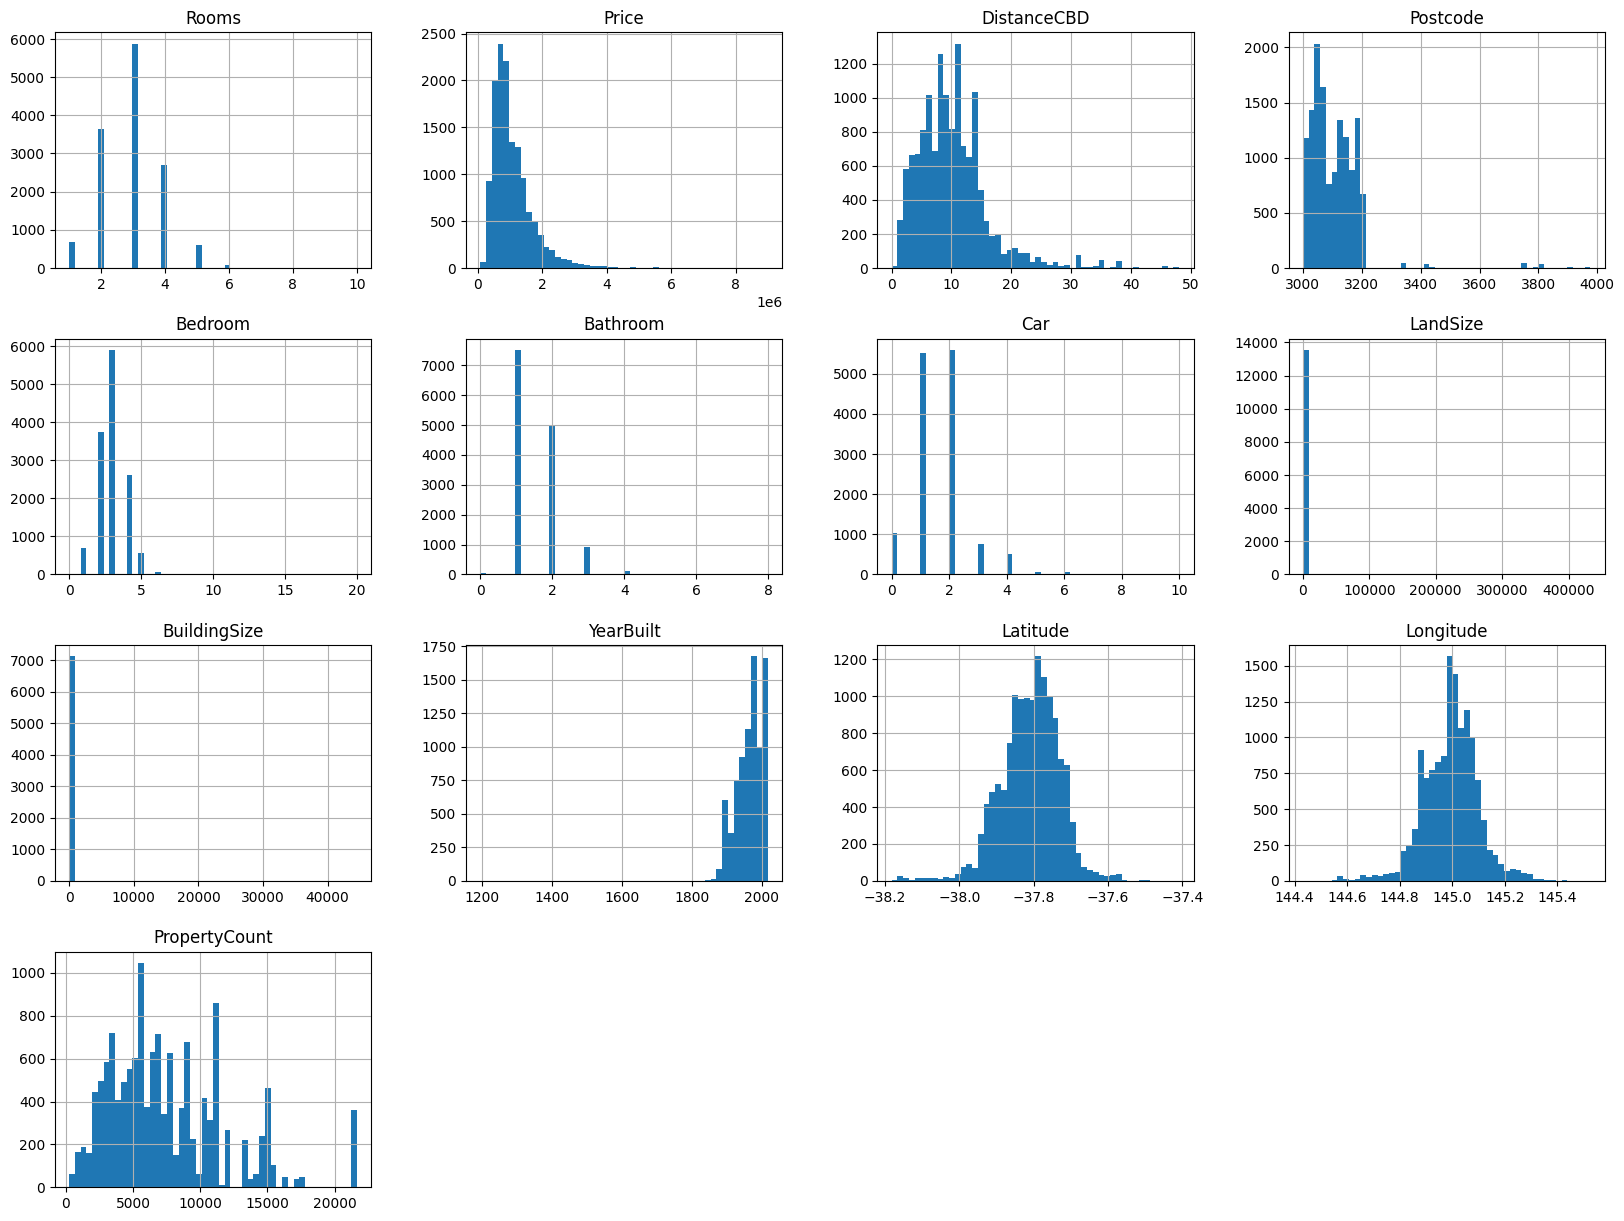

In [10]:
data.hist(bins=50,figsize=(20,15))

- As previously mentioned, Landsize, BuildingArea, and YearBuilt have some outliers that make the histograms not very helpful. We can have a further look at these variables using boxplots.
- Many features are tail-heavy

Rooms               Axes(0.125,0.653529;0.133621x0.226471)
Price            Axes(0.285345,0.653529;0.133621x0.226471)
DistanceCBD       Axes(0.44569,0.653529;0.133621x0.226471)
Postcode         Axes(0.606034,0.653529;0.133621x0.226471)
Bedroom          Axes(0.766379,0.653529;0.133621x0.226471)
Bathroom            Axes(0.125,0.381765;0.133621x0.226471)
Car              Axes(0.285345,0.381765;0.133621x0.226471)
LandSize          Axes(0.44569,0.381765;0.133621x0.226471)
BuildingSize     Axes(0.606034,0.381765;0.133621x0.226471)
YearBuilt        Axes(0.766379,0.381765;0.133621x0.226471)
Latitude                Axes(0.125,0.11;0.133621x0.226471)
Longitude            Axes(0.285345,0.11;0.133621x0.226471)
PropertyCount         Axes(0.44569,0.11;0.133621x0.226471)
dtype: object

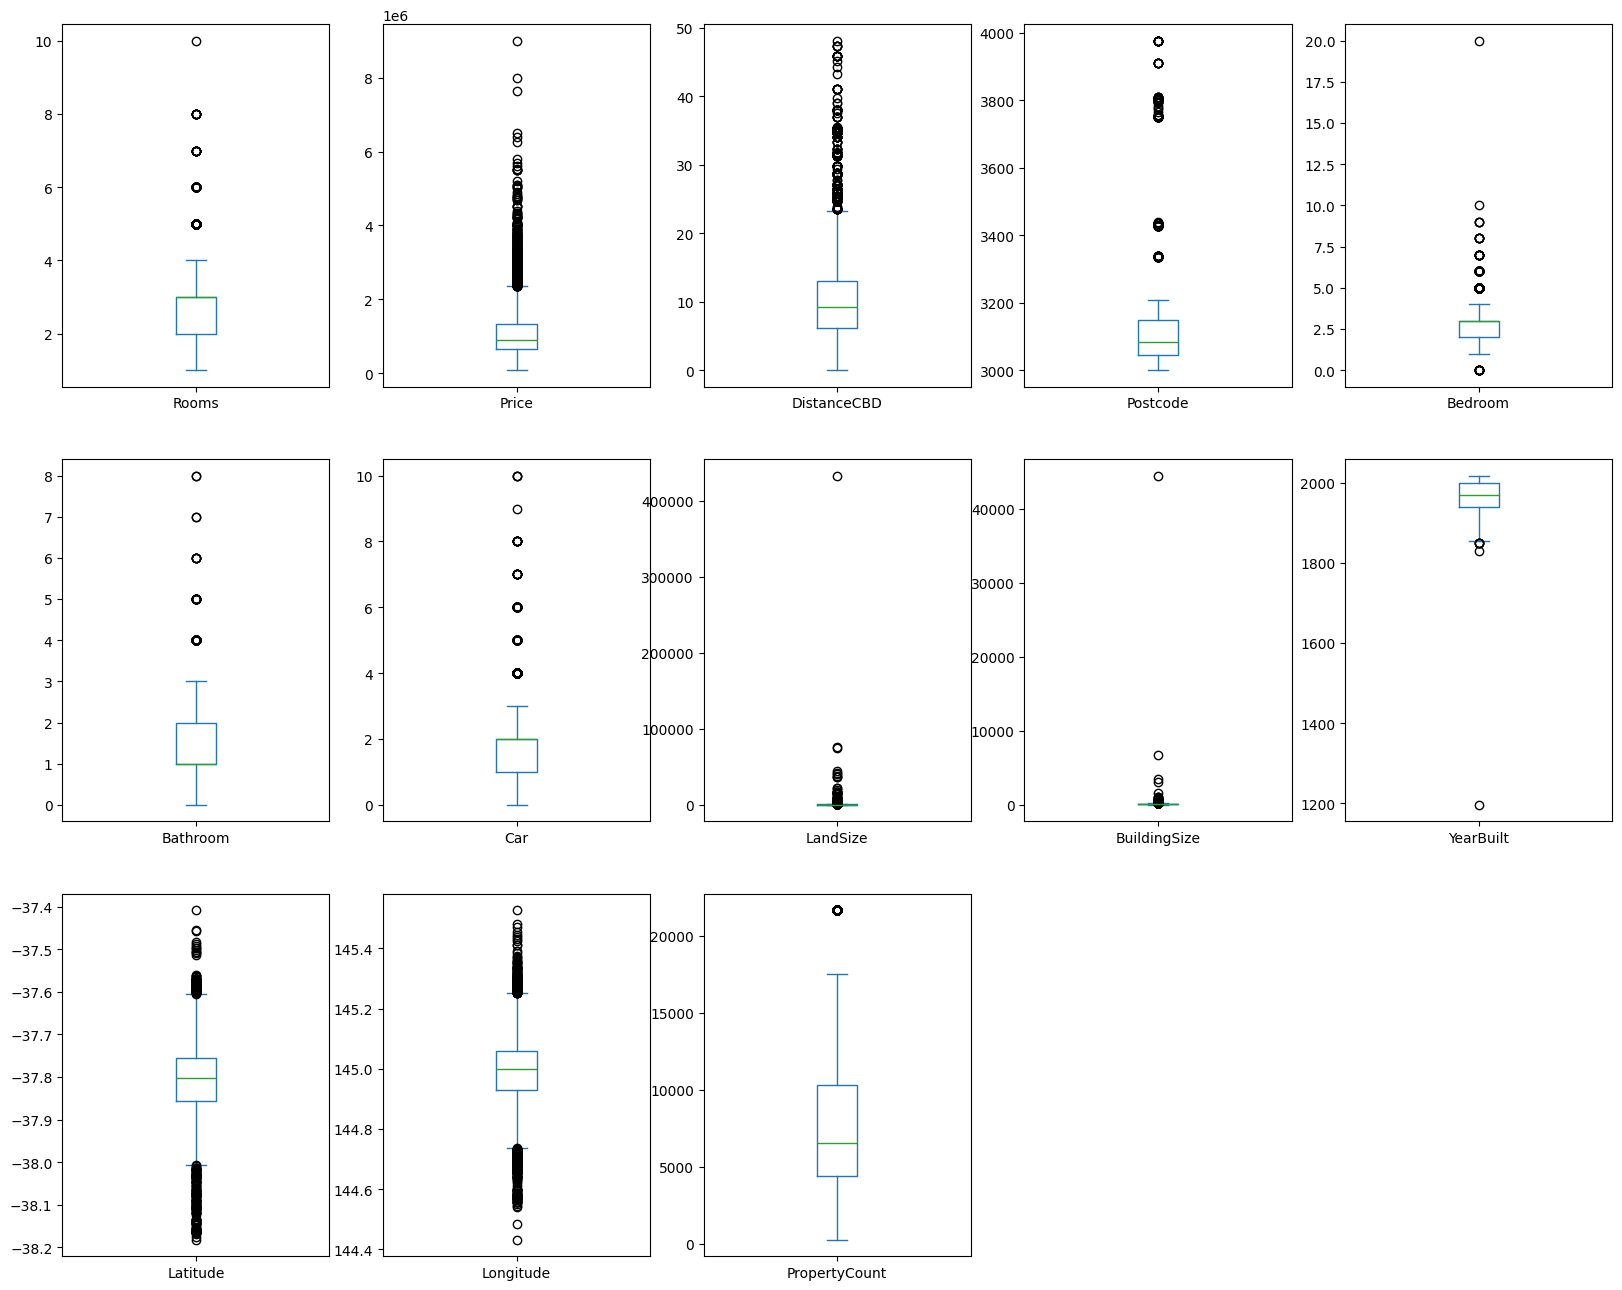

In [11]:
# Another way of visualising distribution
data.plot(kind = "box" , subplots = True , figsize = (20,16) , layout = (3,5))

### 2.7. Investigating outliers

In [12]:
# investigate why the max value of Bedroom is bigger than the max value of Rooms
data[data["Bedroom"] > 10].T

,7404
Suburb,Caulfield East
Address,5 Grange Rd
Rooms,3
Type,h
Price,1650000.0
MethodSold,PI
Agent,Woodards
DateSold,6/08/2016
DistanceCBD,9.3
Postcode,3145.0


- This seems to be an entry error. It should be a three-bed house with 2 bedrooms and 1 bathroom.

In [13]:
# Correct only the investigated row, not every appearance of the value 20.
bedroom_error = ((data['Address'] == '5 Grange Rd') &
                 (data['Suburb'] == 'Caulfield East') &
                 (data['Bedroom'] == 20) & (data['Rooms'] == 3))
assert bedroom_error.sum() == 1, 'Verify the bedroom correction against this dataset version.'
data.loc[bedroom_error, 'Bedroom'] = 2
data.loc[bedroom_error]

,Suburb,Address,Rooms,Type,Price,MethodSold,Agent,DateSold,DistanceCBD,Postcode,Bedroom,Bathroom,Car,LandSize,BuildingSize,YearBuilt,Council,Latitude,Longitude,Region,PropertyCount
7404,Caulfield East,5 Grange Rd,3,h,1650000.0,PI,Woodards,6/08/2016,9.3,3145.0,2.0,1.0,2.0,875.0,NaN,NaN,Glen Eira,-37.8815,145.0491,Southern Metropolitan,608.0


- Next, we investigate unusual values in LandSize, BuildingSize, and YearBuilt.
- For descriptive plots only, values below 10 square metres will be treated as missing. Small recorded areas may sometimes be legitimate, so the original measurements are preserved separately for the predictive modelling stage.

In [14]:
# Treat implausibly small area records as missing for exploratory visualisation only.
var = ['LandSize', 'BuildingSize']
for v in var:
    data.loc[data[v] < 10, v] = np.nan

data[var].describe()

,LandSize,BuildingSize
count,11636.000000,7057.000000
mean,651.708405,153.518399
std,4304.125089,543.589889
min,10.000000,10.000000
25%,270.000000,94.000000
50%,533.000000,127.000000
75%,676.000000,175.000000
max,433014.000000,44515.000000


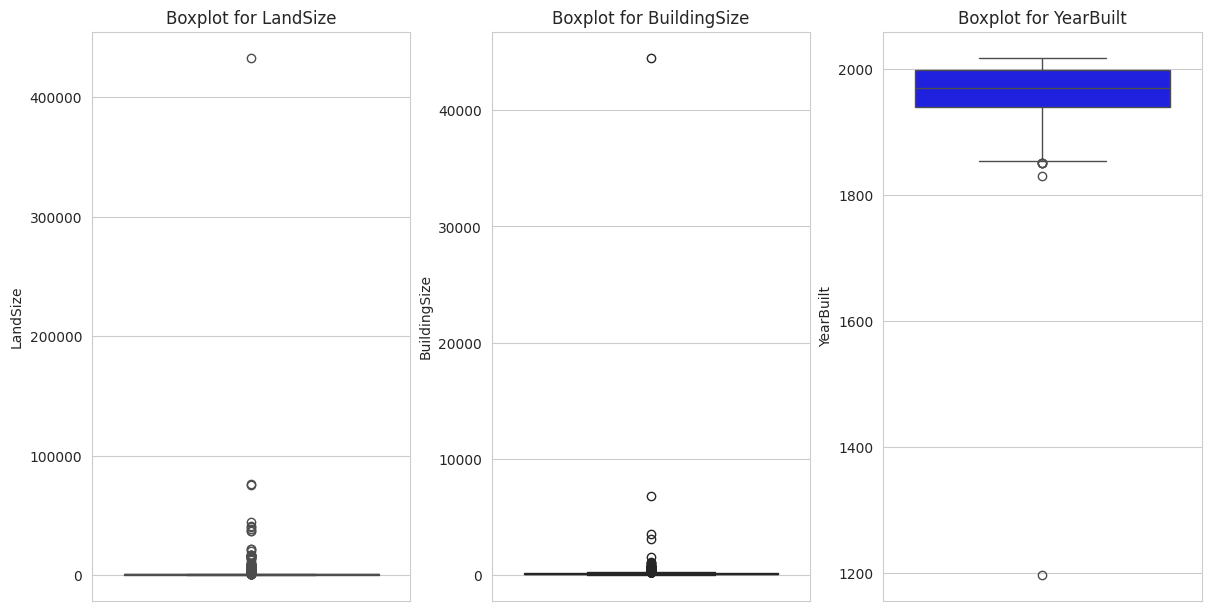

In [15]:
# choosing variables we want to continue investigating 
var = ["LandSize", "BuildingSize", "YearBuilt"]
colours = "rgb"

# setting up the plotting area
sns.set_style("whitegrid")
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(12,6), constrained_layout=True)

# plot
for n in range(len(ax)):
    ax[n].set_title(f"Boxplot for {var[n]}")
    sns.boxplot(y=data[var[n]], ax=ax[n], color=colours[n])

- Of course data may have some natural outliers. However, some of these seem impossible, so we should correct or remove them.
- We write a function to identify the outliers. This can be done via the intequartile range (IQR) method or the z-score method.
    - In IQR, inner fences are set at 1.5\*IQR, i.e. 1.5\*(Q3-Q1), and outer fences are set at 3*IQR. Values between inner and outer fences may be outliers, while values over the outer fences are likely to be outliers.
    - Z-scores are measured by calculating how many standard deviations values are from the mean. If values are over a +/-3 standard deviations from the mean, they are likely to be outliers.

In [16]:
# IQR method
def get_iqr_fences(X, k):
    """Return lower and upper fences for a numeric series, ignoring missing values."""
    q1, q3 = np.nanpercentile(pd.to_numeric(X, errors='coerce'), [25, 75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

# Z-scores method
def get_zscores(X):
    """Compute z-scores without allowing missing values to invalidate the result."""
    series = pd.to_numeric(pd.Series(X), errors='coerce')
    mu = series.mean(skipna=True)
    std = series.std(skipna=True, ddof=0)
    if not np.isfinite(std) or std == 0:
        return pd.Series(np.nan, index=series.index)
    return (series - mu) / std

def get_outliers(X, method, inner=False):
    """Return observed outlier values as a Series retaining original row indices."""
    series = pd.to_numeric(pd.Series(X), errors='coerce')
    if method.lower() in ('iqr', 'interquartile range'):
        lower, upper = get_iqr_fences(series, 1.5 if inner else 3.0)
        mask = (series < lower) | (series > upper)
    elif method.lower() in ('zscore', 'zscores', 'z-score', 'z-scores'):
        mask = get_zscores(series).abs() > 3.0
    else:
        raise ValueError('Method not found')
    return series[mask & series.notna()]

In [17]:
var = ["LandSize", "BuildingSize", "YearBuilt"]
for n in range(len(var)):   
    print(f"\nNumber of outliers in {var[n]} using inner IQR method:", len(get_outliers(data[var[n]], "IQR", inner=True)))
    print(f"Number of outliers in {var[n]} using outer IQR method:", len(get_outliers(data[var[n]], "IQR")))
    print(f"Number of outliers in {var[n]} using z-scores method:", len(get_outliers(data[var[n]], "z-scores")))


Number of outliers in LandSize using inner IQR method: 394
Number of outliers in LandSize using outer IQR method: 252
Number of outliers in LandSize using z-scores method: 24

Number of outliers in BuildingSize using inner IQR method: 351
Number of outliers in BuildingSize using outer IQR method: 101
Number of outliers in BuildingSize using z-scores method: 4

Number of outliers in YearBuilt using inner IQR method: 6
Number of outliers in YearBuilt using outer IQR method: 1
Number of outliers in YearBuilt using z-scores method: 6


- The IQR method tends to identify more unusually sized properties than z-scores because extreme measurements influence the mean and standard deviation.
- These are *statistical* outliers, not necessarily errors. We use the outer IQR fences to investigate the descriptive distributions; removing such observations from model training without domain evidence could introduce bias.
- We will inspect the YearBuilt anomaly separately.

In [18]:
data.loc[get_outliers(data["YearBuilt"], "zscores").index]

,Suburb,Address,Rooms,Type,Price,MethodSold,Agent,DateSold,DistanceCBD,Postcode,Bedroom,Bathroom,Car,LandSize,BuildingSize,YearBuilt,Council,Latitude,Longitude,Region,PropertyCount
2079,Collingwood,2/79 Oxford St,2,u,855000.0,S,Nelson,3/09/2016,1.6,3066.0,2.0,1.0,1.0,2886.0,122.0,1830.0,Yarra,-37.80420,144.98450,Northern Metropolitan,4553.0
2554,Fitzroy,11 Henry St,2,h,677000.0,S,Chambers,27/11/2016,1.6,3065.0,2.0,1.0,0.0,67.0,NaN,1850.0,Yarra,-37.79690,144.97590,Northern Metropolitan,5825.0
4843,Prahran,602/220 Commercial Rd,2,u,841000.0,S,hockingstuart,18/03/2017,4.5,3181.0,2.0,2.0,1.0,NaN,101.0,1850.0,Stonnington,-37.84700,144.99360,Southern Metropolitan,7717.0
5405,Richmond,22a Stanley St,3,h,1600000.0,S,Biggin,24/09/2016,2.6,3121.0,3.0,2.0,2.0,80.0,144.0,1850.0,Yarra,-37.82330,144.99470,Northern Metropolitan,14949.0
5860,St Kilda,51/167 Fitzroy St,3,u,1600000.0,PI,Kay,25/02/2017,6.1,3182.0,3.0,2.0,2.0,NaN,NaN,1850.0,Port Phillip,-37.85840,144.98020,Southern Metropolitan,13240.0
9968,Mount Waverley,5 Armstrong St,3,h,1200000.0,VB,McGrath,24/06/2017,14.2,3149.0,3.0,1.0,4.0,807.0,117.0,1196.0,Monash,-37.86788,145.12121,Eastern Metropolitan,13366.0


- The 19th century houses seem plausible, but not the one built in 1196. After some investigation, we found that this is an entry error. 5 Armstrong St was built in __[1960](https://www.onthehouse.com.au/property/vic/mount-waverley-3149/5-armstrong-st-mount-waverley-vic-3149-6482537)__.


In [19]:
# Apply the originally documented, address-specific year correction in the EDA copy.
# The untouched source data remain available to the modelling pipeline.
year_error = ((data['Address'] == '5 Armstrong St') &
              (data['Suburb'] == 'Mount Waverley') &
              (data['YearBuilt'] == 1196))
assert year_error.sum() == 1, 'Verify the year correction against this dataset version.'
data.loc[year_error, 'YearBuilt'] = 1960
data.loc[year_error]

,Suburb,Address,Rooms,Type,Price,MethodSold,Agent,DateSold,DistanceCBD,Postcode,Bedroom,Bathroom,Car,LandSize,BuildingSize,YearBuilt,Council,Latitude,Longitude,Region,PropertyCount
9968,Mount Waverley,5 Armstrong St,3,h,1200000.0,VB,McGrath,24/06/2017,14.2,3149.0,3.0,1.0,4.0,807.0,117.0,1960.0,Monash,-37.86788,145.12121,Eastern Metropolitan,13366.0


- For the descriptive plots that follow, we flag statistically extreme BuildingSize and LandSize measurements as missing so that the main body of the distribution is visible. The model later uses a separate source copy and does **not** remove valid large properties using thresholds learned from the full dataset.

In [20]:
# Mark only the identified row indices as missing (exploratory dataset only).
# Avoid .replace(value, np.nan), which would remove every identical measurement.
var = ['LandSize', 'BuildingSize']
for v in var:
    outliers = get_outliers(data[v], 'IQR')
    data.loc[outliers.index, v] = np.nan
    print(f'Entries changed for {v}:', len(outliers))

Entries changed for LandSize: 252
Entries changed for BuildingSize: 101


array([[<Axes: title={'center': 'Rooms'}>,
        <Axes: title={'center': 'Price'}>,
        <Axes: title={'center': 'DistanceCBD'}>,
        <Axes: title={'center': 'Postcode'}>],
       [<Axes: title={'center': 'Bedroom'}>,
        <Axes: title={'center': 'Bathroom'}>,
        <Axes: title={'center': 'Car'}>,
        <Axes: title={'center': 'LandSize'}>],
       [<Axes: title={'center': 'BuildingSize'}>,
        <Axes: title={'center': 'YearBuilt'}>,
        <Axes: title={'center': 'Latitude'}>,
        <Axes: title={'center': 'Longitude'}>],
       [<Axes: title={'center': 'PropertyCount'}>, <Axes: >, <Axes: >,
        <Axes: >]], dtype=object)

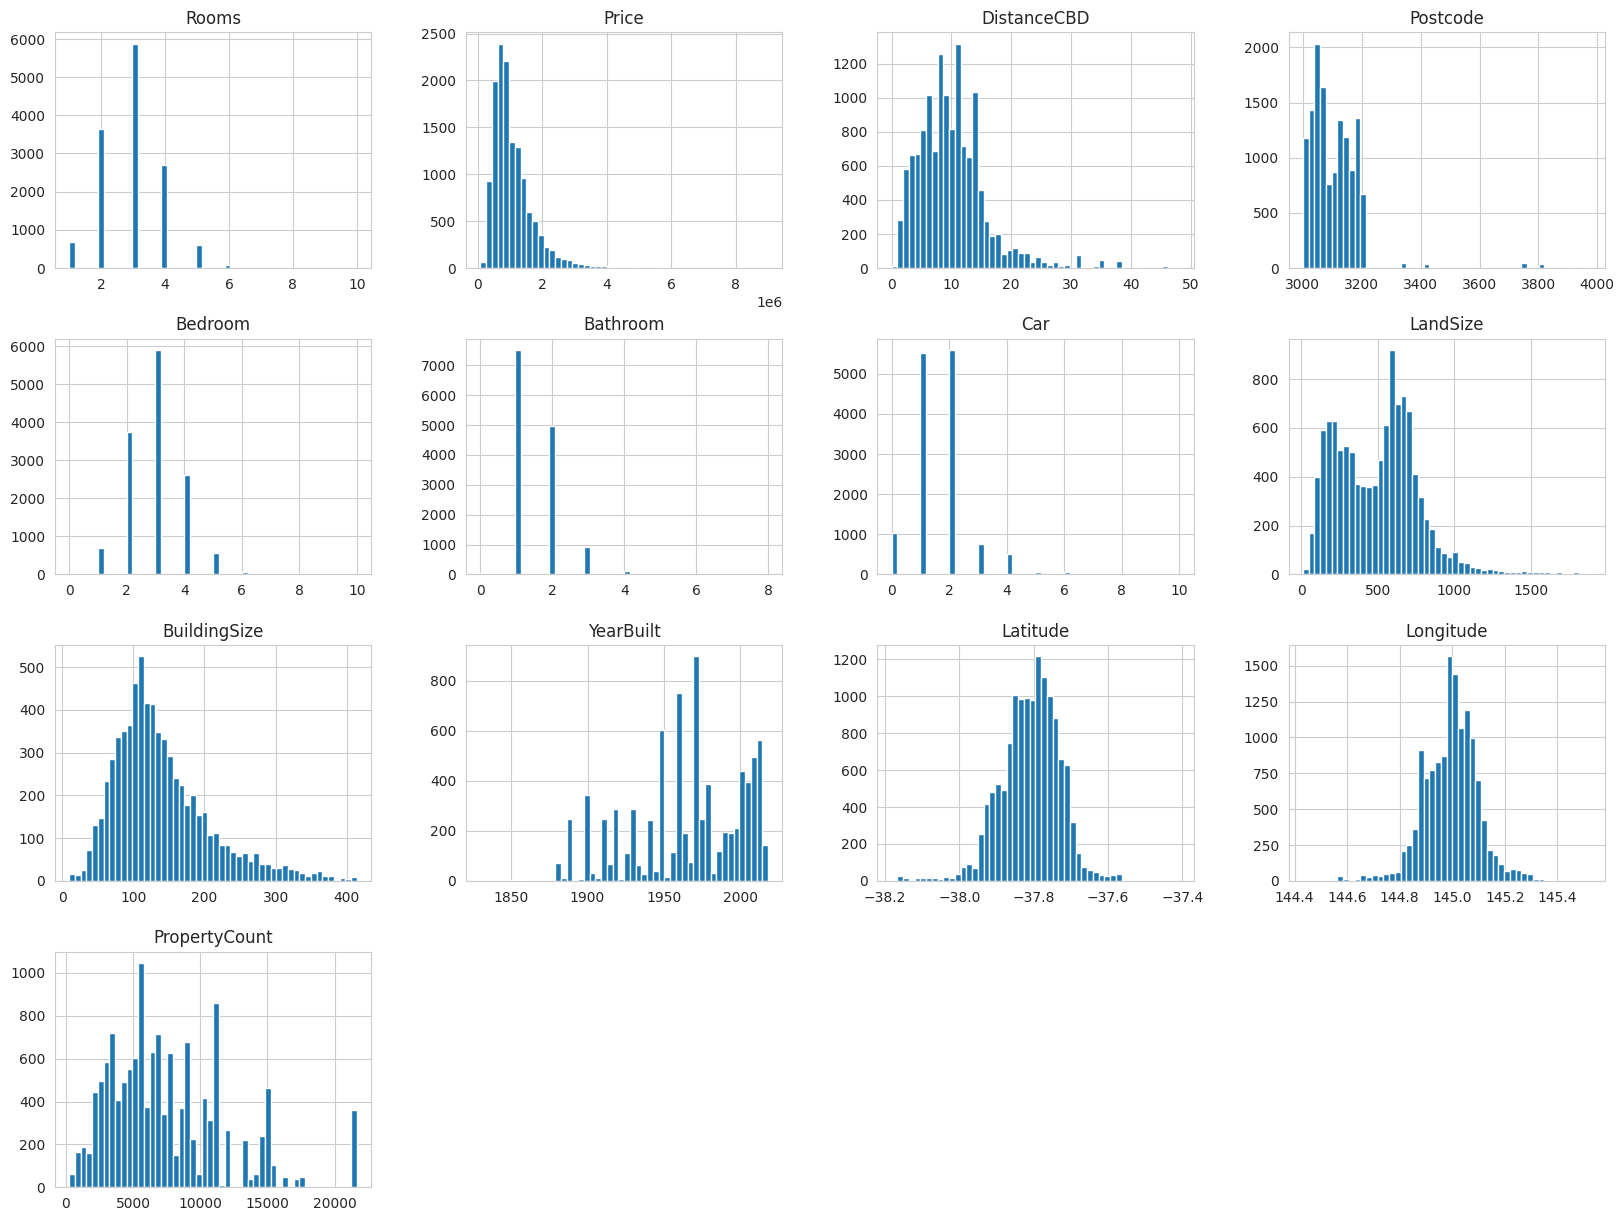

In [21]:
# visualising again
data.hist(bins=50,figsize=(20,15))

### 2.8. Investigating missing data

In [22]:
def missing_summary(data):
    """
    data: a pandas dataframe
    
    returns the percentage of missing data for every column of data.
    """
    # store the count of missing values
    missing = data.isna().sum()
    # calculate the percentage of missing values
    percentage = (missing/(len(data)))*100
    # combine into a summary, giving the series appropriate names
    summary = pd.concat([missing.rename("missing count"), percentage.rename("missing percentage")], axis=1)
    return(round(summary,2))

missing_summary(data)

,missing count,missing percentage
Suburb,0,0.00
Address,0,0.00
Rooms,0,0.00
Type,0,0.00
Price,0,0.00
MethodSold,0,0.00
Agent,0,0.00
DateSold,0,0.00
DistanceCBD,0,0.00
Postcode,0,0.00


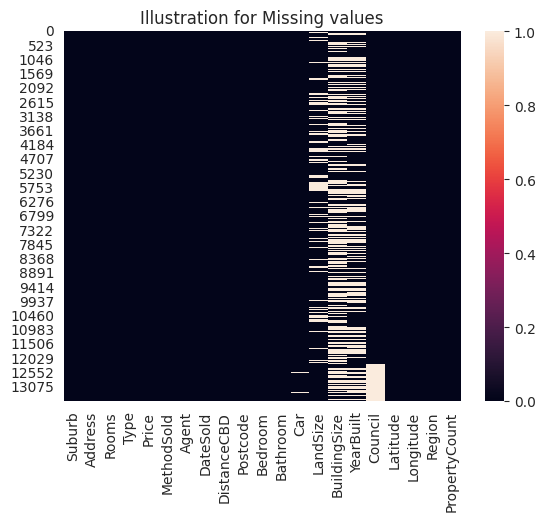

In [23]:
# Heatmap illustration for missing values

plt.title("Illustration for Missing values")
sns.heatmap(data.isnull())
plt.show()

Large amount of data are missing in the BuildingArea and YearBuilt columns. The rows and columns still have valuable details, thus, it was decided to perform the data analysis on the dataset without dropping these rows or columns.

#### Car 
First we investigate the column "Car", which has the smallest proportion of missing values - less than 0.5%. Car is a discrete variable, so we can check for the count of every value.

In [24]:
data["Car"].value_counts(dropna=False)

Car
2.0     5591
1.0     5509
0.0     1026
3.0      748
4.0      506
5.0       63
NaN       62
6.0       54
8.0        9
7.0        8
10.0       3
9.0        1
Name: count, dtype: int64

It seems that the missing values are there because of a lack of information, not because there are no carspots in these properties. Because the amount of missing data is small, we can either delete the entries or use imputation. The rows are not missing completely, so the information there still might be useful to us. In this case, we can fill the missing values with the median.

This imputation is for the descriptive analysis only; predictive models later fit their imputers exclusively on training data.

In [25]:
def fill_missing_values(data, column, method, value=None):
    """
    data: a pandas dataframe
    column: a string, the name of the column to be filled
    method: a string, choose from "mean", "median", "value"
    value: value to be filled if method == "value"

    fills the missing values in that column of the dataframe 
    with the supplied method or value
    """
    if method.lower() not in ["mean", "median", "value"]:
        raise NameError("Method not found")
    elif method.lower() == "mean":
        value = data[column].mean()
    elif method.lower() == "median":
        value = data[column].median()
    data[column] = data[column].fillna(value)

In [26]:
fill_missing_values(data, "Car", "median")
data["Car"].value_counts(dropna=False)

Car
2.0     5653
1.0     5509
0.0     1026
3.0      748
4.0      506
5.0       63
6.0       54
8.0        9
7.0        8
10.0       3
9.0        1
Name: count, dtype: int64

The median value of Car, which was 2, was imputed.

#### Council

Roughly 10% of Council is missing. It's a categorical variable, so let's examine its unique values first.


In [27]:
data["Council"].unique()

array(['Yarra', 'Moonee Valley', 'Port Phillip', 'Darebin', 'Hobsons Bay',
       'Stonnington', 'Boroondara', 'Monash', 'Glen Eira', 'Whitehorse',
       'Maribyrnong', 'Bayside', 'Moreland', 'Manningham', 'Banyule',
       'Melbourne', 'Kingston', 'Brimbank', 'Hume', nan, 'Knox',
       'Maroondah', 'Casey', 'Melton', 'Greater Dandenong', 'Nillumbik',
       'Whittlesea', 'Frankston', 'Macedon Ranges', 'Yarra Ranges',
       'Wyndham', 'Cardinia', 'Unavailable', 'Moorabool'], dtype=object)

We can see that there is already a value that represent missing data - "Unavailable". Therefore, we can fill the NaNs with this value.

In [28]:
fill_missing_values(data, "Council", "value", "Unavailable")
missing_summary(data)

,missing count,missing percentage
Suburb,0,0.00
Address,0,0.00
Rooms,0,0.00
Type,0,0.00
Price,0,0.00
MethodSold,0,0.00
Agent,0,0.00
DateSold,0,0.00
DistanceCBD,0,0.00
Postcode,0,0.00


#### LandSize, BuildingSize, and YearBuilt
Next, we look at LandSize, BuildingSize, and YearBuilt. While LandSize only has 16% of its values missing, BuildingSize and YearBuilt has almost 50% and 40% missing, respectively. It does not make sense to try to predict these missing values now because they may interfere with data analysis, so we will keep them as is - working with the default global constant for missing values NaN. Imputation may be done before machine learning.

The predictive modelling section uses the separate original-data copy and handles missing values within cross-validated preprocessing pipelines.

## 3. Data analysis


### 3.1. Numerical variables


#### 3.1.1. Correlation analysis

Text(0.5, 1.0, 'Correlation matrix of Melbourne housing dataset')

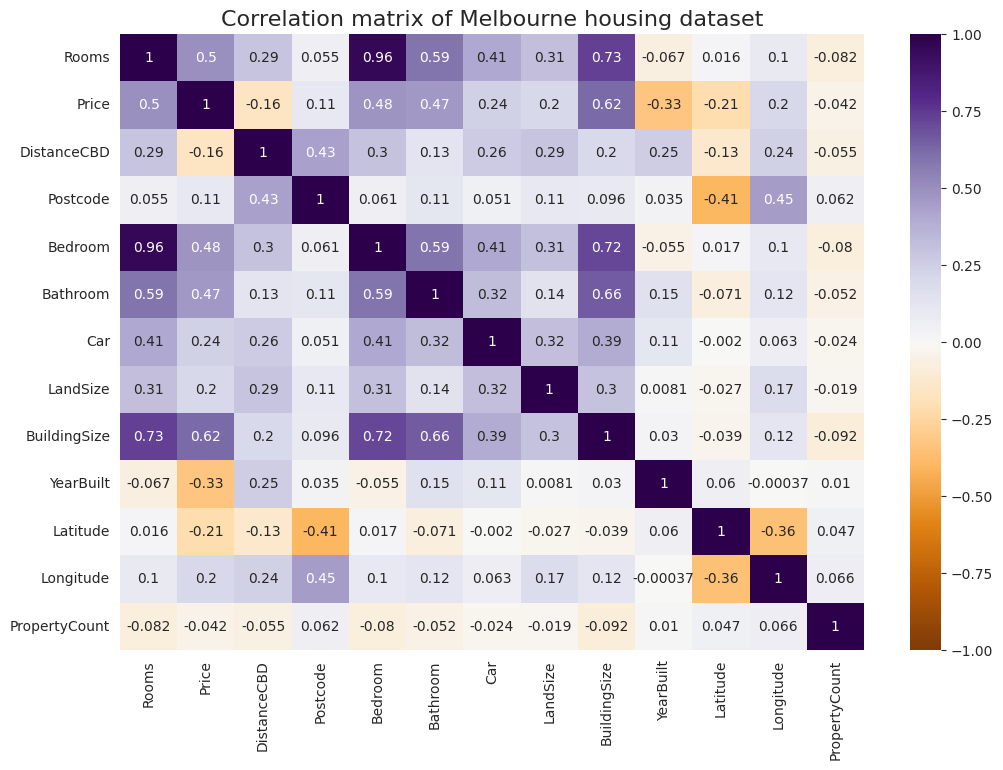

In [29]:
# create a correlation matrix
corr_matrix = data.corr(numeric_only=True)
# plotting the correlation matrix
# setting up the plotting area
plt.figure(figsize=(12,8))
# plotting function
sns.heatmap(corr_matrix, vmin=-1, vmax=1, center=0, annot=True, cmap="PuOr")
plt.title("Correlation matrix of Melbourne housing dataset", fontdict={'fontsize': 16})

From the correlation matrix, we can see that:
- Rooms and Bedroom stand out with an extremely strong positive correlation - at r = 0.96. This means it may be worth looking into doing some feature engineering later to keep only the most important columns.
- BuildingSize correlates rather strongly with Rooms, Bedroom, and Bathroom, as well as Price. It is good that we did not drop this column despite the amount of missing data.
- Surprisingly, DistanceCBD have almost no correlation with Price.
- Geographical features have some correlations with one another, such as between Postcode and Longtitude, Lattitude, or DistanceCBD.

In [30]:
# look deeper into the variables' correlation with our target variable
corr_matrix["Price"].sort_values(ascending=False)

Price            1.000000
BuildingSize     0.620547
Rooms            0.496634
Bedroom          0.480268
Bathroom         0.467038
Car              0.239109
LandSize         0.204305
Longitude        0.203656
Postcode         0.107867
PropertyCount   -0.042153
DistanceCBD     -0.162522
Latitude        -0.212934
YearBuilt       -0.331830
Name: Price, dtype: float64

- Correlation is highest between Price and BuildingSize, as well as rooms-related features. There is some weak negative association between Price and Yearbuilt, meaning older houses tend to be more expensive.
- However, we should keep in mind that correlation only explores linear relationships.

Text(0.5, 0.9, 'Scatter matrix for selected variables')

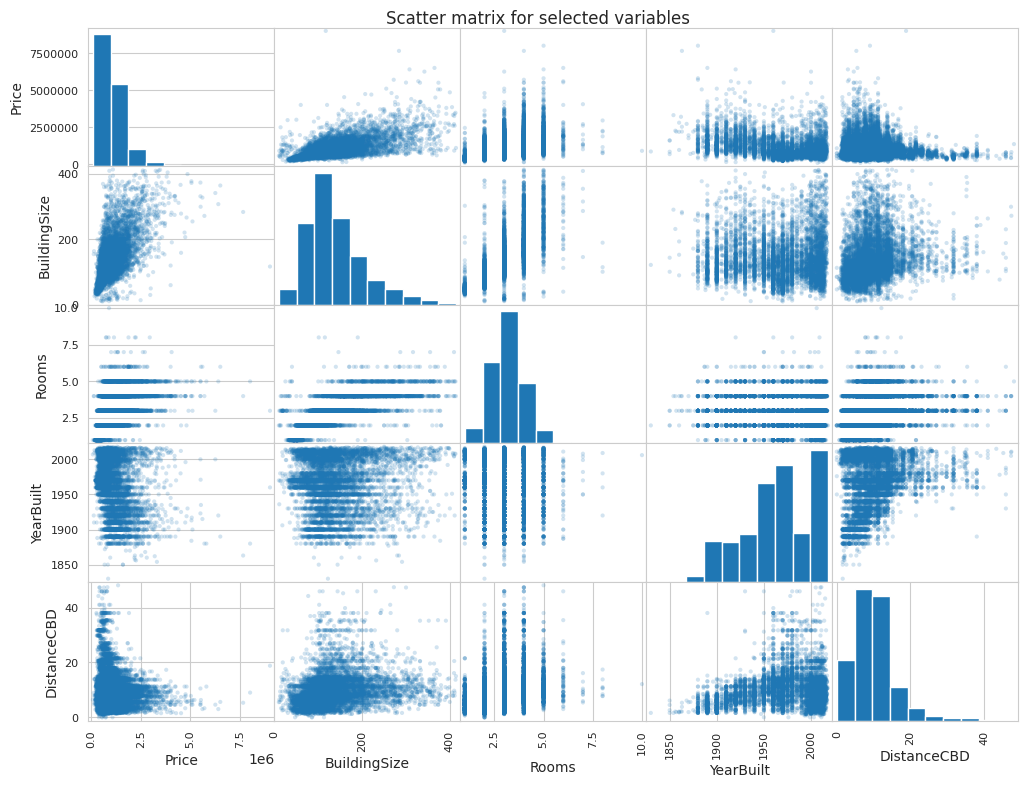

In [31]:
# choose some variables of interest
columns = ["Price", "BuildingSize", "Rooms", "YearBuilt", "DistanceCBD"]
# plot in a scatter matrix
pd.plotting.scatter_matrix(data[columns], figsize=(12,9), alpha=0.2)
plt.suptitle("Scatter matrix for selected variables", y=0.9)

#### 3.1.2. Rooms

Text(0.5, 1.0, 'Boxplot Diagram - Rooms')

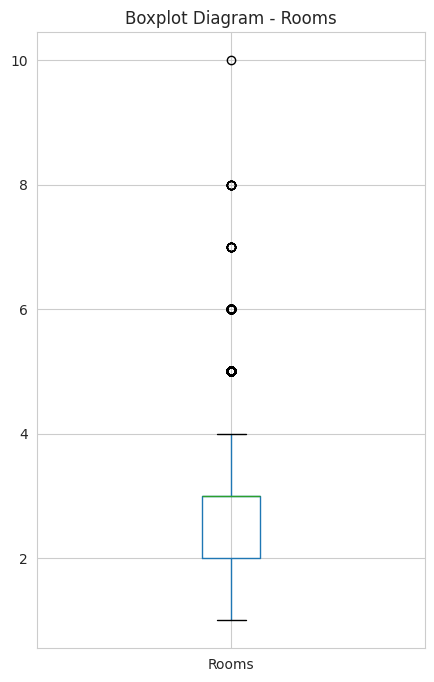

In [32]:
#Plotting the boxplot for 'Rooms'
data.boxplot(column = ['Rooms'], figsize = [5, 8])
plt.title("Boxplot Diagram - Rooms")

Text(0.5, 1.0, 'Barchart - Rooms')

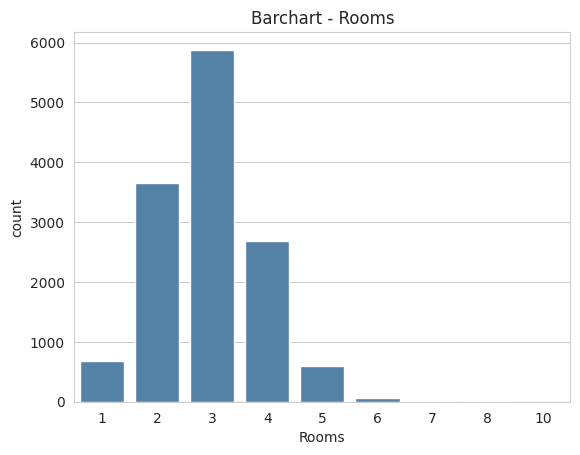

In [33]:
#Plotting the Bar Chart for 'Rooms'
sns.countplot(x = "Rooms", data = data, color="steelblue")
plt.title("Barchart - Rooms")

In [34]:
#Plotting a pie chart for the 'Rooms'
px.pie(data, names = "Rooms", title="Pie chart - Rooms")

In [35]:
#Determining the value count of the column 'Rooms'
data["Rooms"].value_counts()

Rooms
3     5881
2     3648
4     2688
1      681
5      596
6       67
7       10
8        8
10       1
Name: count, dtype: int64

When the dataset is been analysed it is clear that most of the data in the parameter "Room" lies in beetween 2 to 4 which subsequently illustrates that most of the houses are consist of 2 to 4 rooms in the Melbourne.

As per the illustrations of the single box plot which was plotted for the parameter "Room" there can be seen an outlier in 10 which indicates that there is a house which is having 10 rooms in the Melbourne.

To have a clearer picture, a barchart is been plotted. Through the barchart it can be seen that nearly 6000 houses are having 3 rooms, nearly 4000 houses are having 2 rooms and nearly 3000 houses are having 4 rooms in the Melbourne area.

A pie chart can be plotted using "px.pie" to provide details on the percentage of values of  "Rooms". Through this pie chart it can be seen that 43.3% of the houses which is exactly 5881 houses in the Melbourne area are 3 rooms. According to the pie chart it is clear that even less that 1% of the houses are having 6 or more rooms in the Melbourne.

#### 3.1.3. Price

Text(0.5, 1.0, 'Boxplot Diagram - Price')

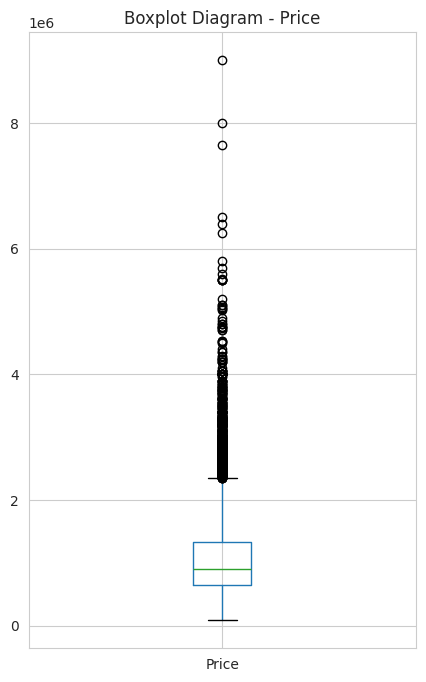

In [36]:
#Plotting the boxplot for 'Price'
data.boxplot(column = ['Price'], figsize = [5, 8])
plt.title("Boxplot Diagram - Price")

Text(0.5, 1.0, 'Histogram - Price')

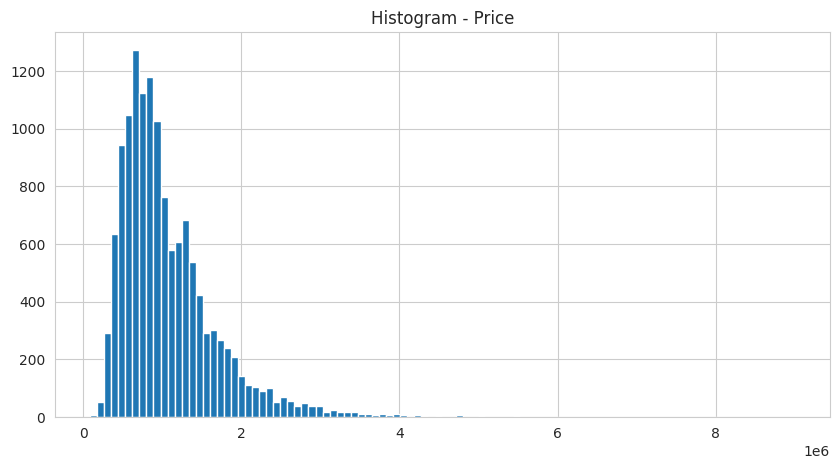

In [37]:
#Plotting the Histogram for 'Price'
data.hist(column = 'Price', bins=100, figsize=(10,5))
plt.title("Histogram - Price")

In [38]:
#Determining the value count of the column 'Price'
data["Price"].value_counts().head()

Price
1100000.0    113
1300000.0    109
800000.0     109
650000.0     109
600000.0     104
Name: count, dtype: int64

When Price factor is considered, it is clear that there are some outliers in between 8 and 9 according to the box plot. However, it can be considered negligible as there could be houses which are expensive than the other houses in the Melbourne area.

Moreover, it is also clear that over 7000 houses are priced at 0 - 1 million Australian dollars. Furthermore, it can also be seen that little less than 5000 houses are priced at 1 million to 2 million. To have a clear picture on the housing prices these data were plotted in to a histogram.

For further analysis the "value_counts()" feature has been used. As per the data available in the data set the most number of houses which is 113 houses are priced at 1100000 (One million one hundred thoused).

<Axes: title={'center': 'Map of Melbourne Area prices'}, xlabel='Longitude', ylabel='Latitude'>

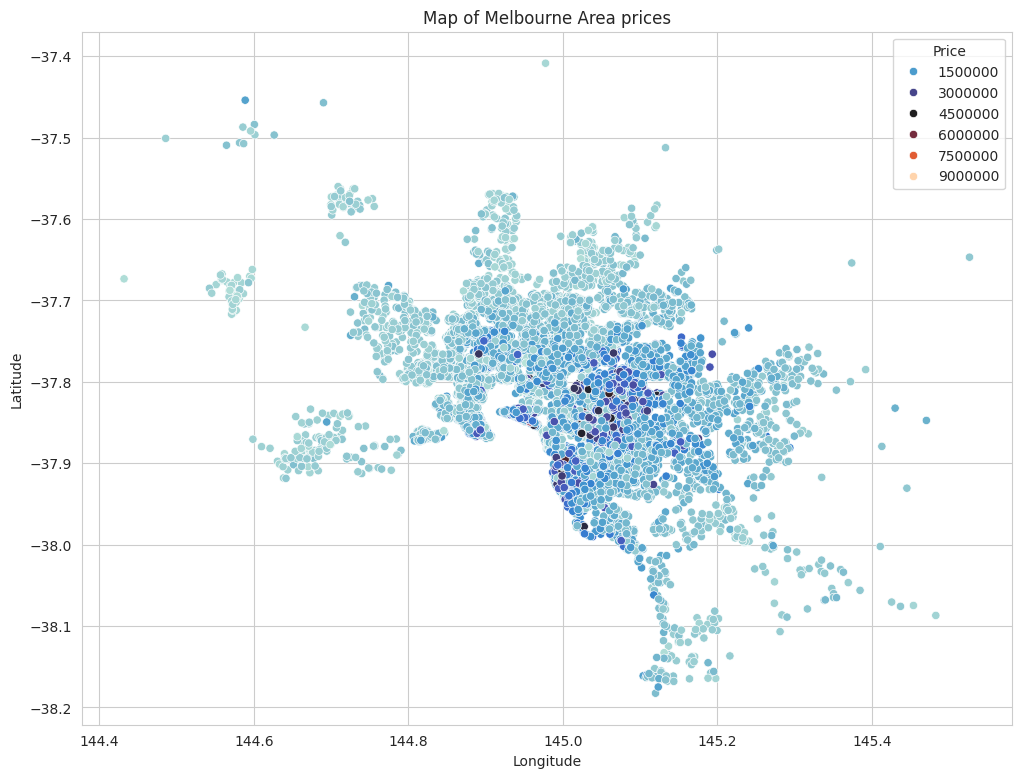

In [39]:
#Plotting the map of the properties sold with respect to price
plt.figure(figsize = (12, 9))
plt.title("Map of Melbourne Area prices")
sns.scatterplot(x = "Longitude", y = "Latitude", data = data, 
                hue = "Price", palette = "icefire")

Through the following map, it illustrates the price distribution of the properties sold in the Melbourne area.

In [40]:
#Determining the maximum value of 'Price' column in the dataset
print(max(data['Price']))

#Determining the minimum value of 'Price' column in the dataset
print(min(data['Price']))

9000000.0
85000.0


According to the data set the maximum value of a house in the Melbourne is 9 million Australian Dollars and the lowest price of a house appears to be 85,000 Australian Dollars.

#### 3.1.4. DistanceCBD

Text(0.5, 1.0, 'Boxplot Diagram - DistanceCBD')

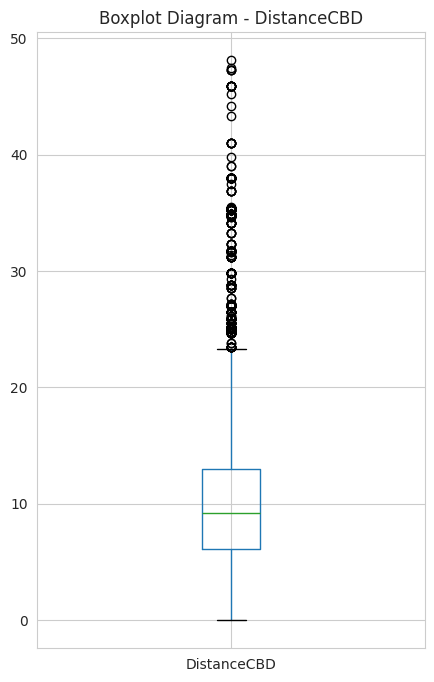

In [41]:
#Plotting the boxplot for 'DistanceCBD'
data.boxplot(column = ['DistanceCBD'], figsize = [5, 8])
plt.title("Boxplot Diagram - DistanceCBD")

Text(0.5, 1.0, 'Histogram - DistanceCBD')

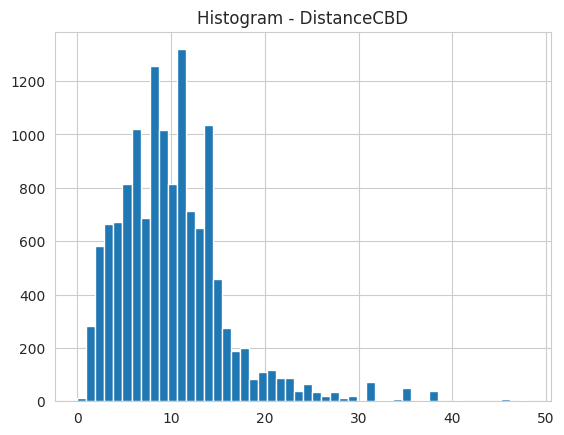

In [42]:
#Plotting the Histogram for 'DistanceCBD'
data.hist(column = ['DistanceCBD'], bins=50)
plt.title("Histogram - DistanceCBD")

In [43]:
#Determining the value count of the column 'DistanceCBD'
data["DistanceCBD"].value_counts().head()

DistanceCBD
11.2    739
9.2     367
13.9    324
7.8     306
4.6     263
Name: count, dtype: int64

When the distance of the houses from the central business district is been considered it can be seen that most of the houses are in between the distance of 7 - 12 kilometres from the central business district. However, there are houses available which is further than 30 kilometres away from the central business district. According to the box plot it is also clear that all the houses which have been sold during the time period are within the distance of 50 kilometres from the central business district of melbourne.

To have a clear understanding on the Distance, a histogram was plotted. Through the histogram it can be seen that most of the houses are inbetween the distance of 3 - 15 kilometres from the central business district of the city. However, when the 'value_counts()' feature was used to exactly determine the number of houses it depicts that 739 houses (highest number of houses) are 11.2 kilometres away from the central business district.

<Axes: title={'center': 'Map of Melbourne Area with Distance to Central Business District'}, xlabel='Longitude', ylabel='Latitude'>

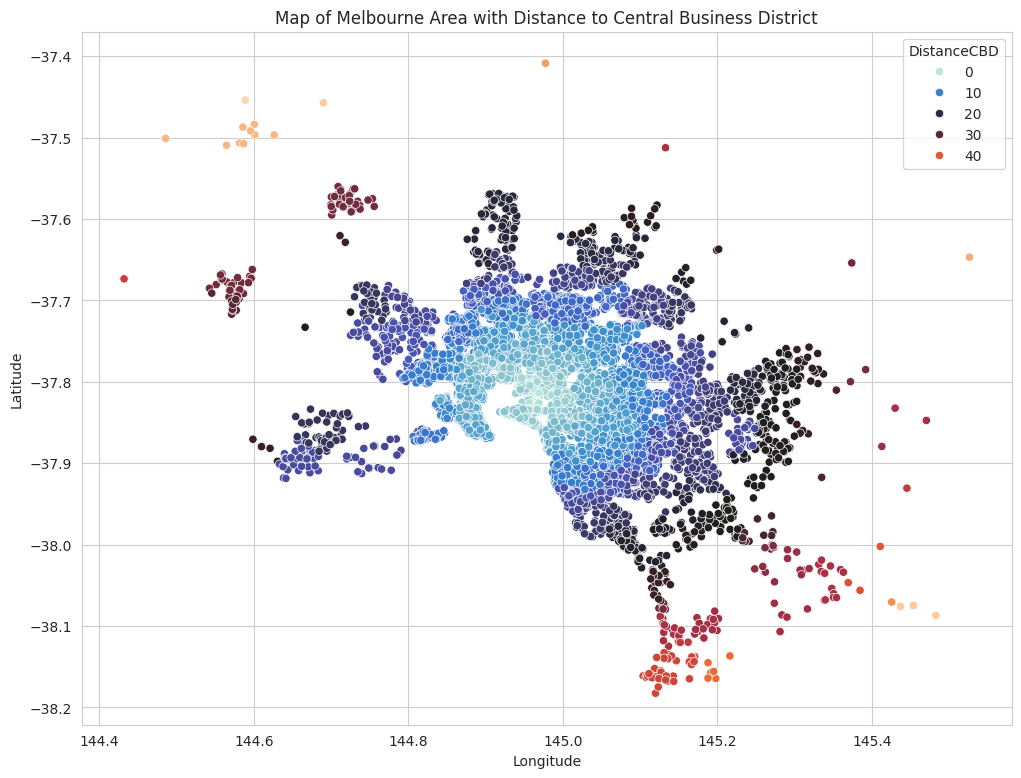

In [44]:
#Plotting the map of the properties sold with distance to central business district
plt.figure(figsize = (12, 9))
plt.title("Map of Melbourne Area with Distance to Central Business District")
sns.scatterplot(x = "Longitude", y = "Latitude", data = data, hue = "DistanceCBD", palette = "icefire")

In [45]:
#Determining the maximum value of 'DistanceCBD' column in the dataset
print(max(data['DistanceCBD']))

#Determining the minimum value of 'DistanceCBD' column in the dataset
print(min(data['DistanceCBD']))

48.1
0.0


The maximum distance a house is located from the central business district is 48.1 kilometres according to the following datast and the minimum value is just 0 kilometres which subsequently means that there have been properties which were sold within the central business district.

#### 3.1.5. Postcode

Text(0.5, 1.0, 'Histogram - Postcode')

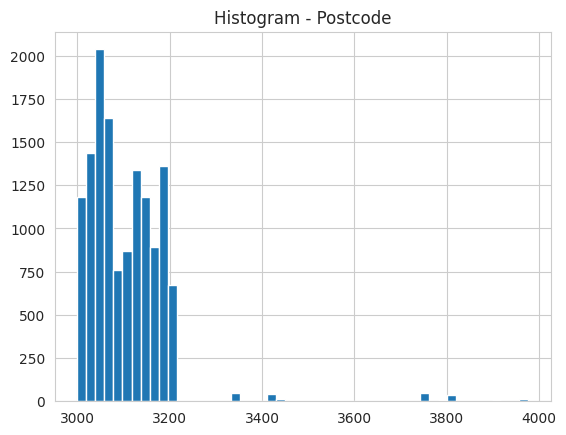

In [46]:
#Plotting the Histogram for 'Postcode'
data.hist(column = ['Postcode'], bins=50)
plt.title("Histogram - Postcode")

In [47]:
#Determining the value count of the column 'Postcode'
data["Postcode"].value_counts().head()

Postcode
3073.0    359
3020.0    306
3121.0    292
3040.0    290
3046.0    284
Name: count, dtype: int64

To have a clear picture a histogram was plotted and then it was figured out that most of the houses sold are in between the postcodes of 3000 - 3200. It seems like these are the postcodes for the metropolitan regions of Melbourne.

After obtaining results from the 'value_counts()' it was determined that the postcode with the most of the houses is the 3073 postcode, which has exactly 359 houses. Other postcodes with many properties sold are 3020, 3121, 3040, and 3046.

#### 3.1.6. Bedroom

Text(0.5, 1.0, 'Boxplot Diagram - Bedrooms')

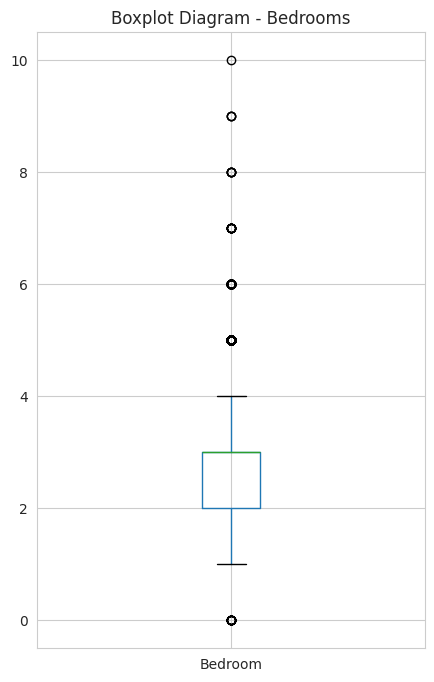

In [48]:
#Plotting the boxplot for 'Bedroom'
data.boxplot(column = ['Bedroom'], figsize = [5, 8])
plt.title("Boxplot Diagram - Bedrooms")

Text(0.5, 1.0, 'Barchart - Bedrooms')

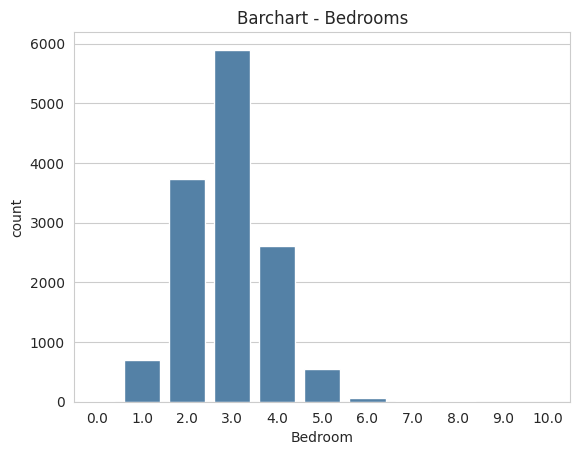

In [49]:
#Plotting the Bar Chart for 'Bedroom'
sns.countplot(x = "Bedroom", data = data, color="steelblue")
plt.title('Barchart - Bedrooms')

In [50]:
#Plotting the Pie Chart for 'Bedroom'
px.pie(data, names = "Bedroom", title= "Pie chart - Bedrooms")

In [51]:
#Determining the value count of the column 'Bedroom'
data["Bedroom"].value_counts()

Bedroom
3.0     5896
2.0     3738
4.0     2601
1.0      691
5.0      556
6.0       63
0.0       16
7.0       10
8.0        5
9.0        3
10.0       1
Name: count, dtype: int64

When the Bedrooms of these houses which were sold were analysed, it is clear that most of the houses consist of 2-3 bedrooms from the boxplot. However, there can be seen houses with more than 5 bedrooms according to the dataset.

For a better understanding, a bar chart and a pie chart was plotted. Through these figures, it can conclude that the most of the houses are 3-Bedroom houses which is 43.4% of the entire Bedroom percentage in the following data set followed by 2-Bedroom houses which marks a percentage of 27.5% and 4-Bedroom houses with a percentage of 19.2% respectively.

However, when the 'value_counts()' command was used, it was determined that as per the data available in the dataset a house with 10 Bedrooms have also been sold. Hence, a hypothesis can be developed that this is either a hotel or a mansion in the Melbourne area.

#### 3.1.7. Bathroom (Samudra)

Text(0.5, 1.0, 'Boxplot Diagram - Bathrooms')

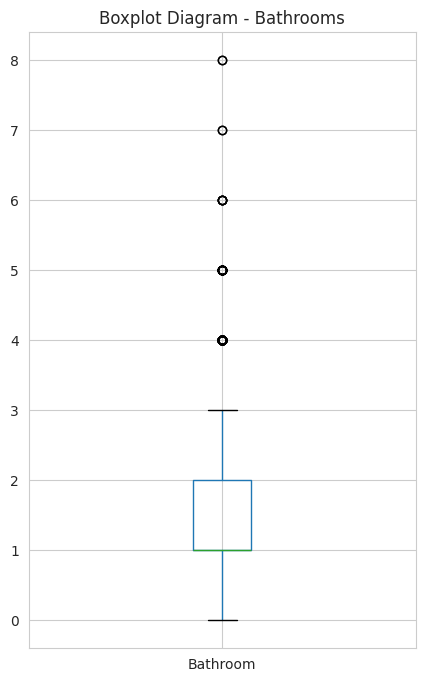

In [52]:
#Plotting the boxplot for 'Bathrooms'
data.boxplot(column = ['Bathroom'], figsize = [5, 8])
plt.title("Boxplot Diagram - Bathrooms")

Text(0.5, 1.0, 'Barchart - Bathrooms')

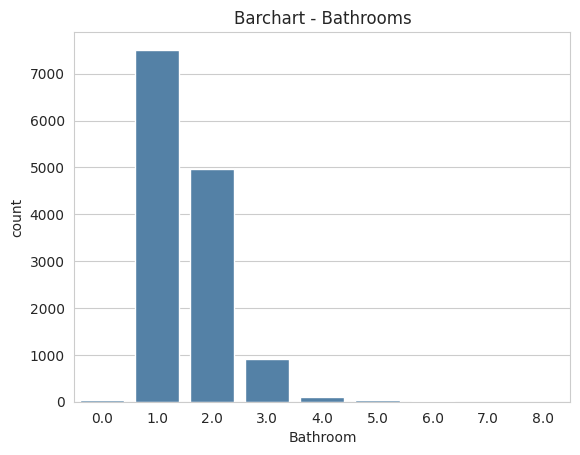

In [53]:
#Plotting the Bar Chart for 'Bathrooms'
sns.countplot(x = "Bathroom", data = data, color="steelblue")
plt.title("Barchart - Bathrooms")

In [54]:
#Plotting the Pie Chart for 'Bathrooms'
px.pie(data, names = "Bathroom", title="Pie chart - Bathroom")

In [55]:
#Determining the value count of the column 'Bathroom'
data["Bathroom"].value_counts() 

Bathroom
1.0    7512
2.0    4974
3.0     917
4.0     106
0.0      34
5.0      28
6.0       5
7.0       2
8.0       2
Name: count, dtype: int64

When the Bathroom parameter is been taken into consideration, according to the boxplot which has been plotted, it can be seen that the most of the houses in the Melbourne area are having 1 or 2 bathrooms.

To get a clear understanding on the dataset a bar chart and a pie chart was plotted. According to these 2 illustrations it can be seen that most of the houses are having only 1 bathroom which is 55.3% of the entire houses in the Melbourne. Moreover, 36.6% of the houses are having 2 bathrooms and just 6.75% of the houses are having 3 bathrooms.

To understand the count of the bathrooms of houses in the Melbourne area 'value_counts()' function was used. Through this it was identified that there are exactly 7512 houses are one-bathroom houses whilst there are 2 houses with 7 and 2 houses 8 bathrooms in this region.

#### 3.1.8. Car

Text(0.5, 1.0, 'Boxplot Diagram - Car')

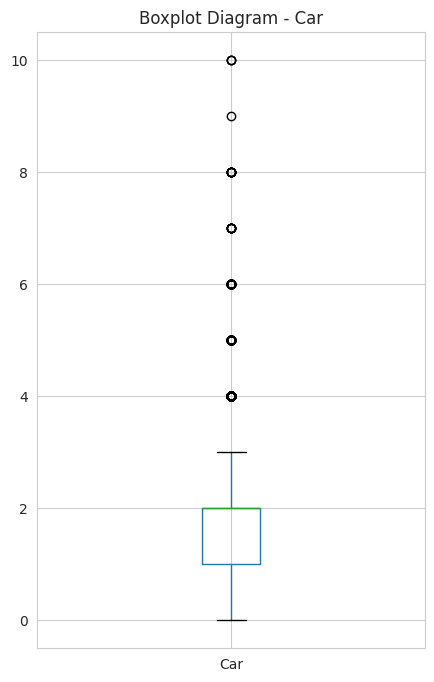

In [56]:
#Plotting the boxplot for 'Car'
data.boxplot(column = ['Car'], figsize = [5, 8])
plt.title("Boxplot Diagram - Car")

Text(0.5, 1.0, 'Barchart - Car')

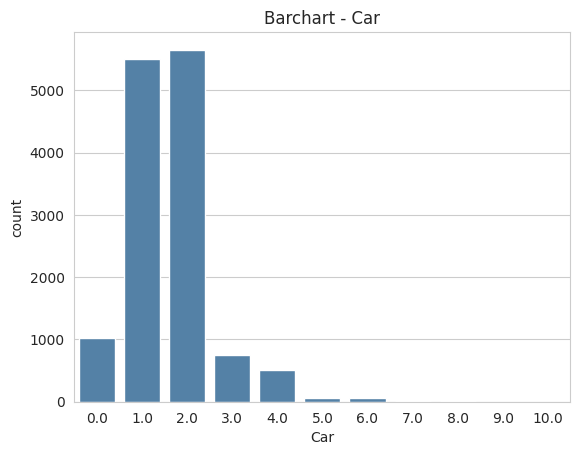

In [57]:
#Plotting the Bar Chart for 'Car' 
sns.countplot(x = "Car", data = data, color="steelblue")
plt.title("Barchart - Car")

In [58]:
#Plotting the Pie Chart for 'Car'
px.pie(data, names = "Car", title = "Pie chart - Car")

In [59]:
#Determining the value count of the column 'Car'
data["Car"].value_counts()

Car
2.0     5653
1.0     5509
0.0     1026
3.0      748
4.0      506
5.0       63
6.0       54
8.0        9
7.0        8
10.0       3
9.0        1
Name: count, dtype: int64

A box plot, bar chart, and pie chart was plotted and a value count was performed to get a picture of the Car variable. Thus, it is clear that most of the houses are having 2 car parking spots which is 41.6% of the entire houses in the Melbourne area depicting a count of 5653 houses. Secondly, there are houses with just only one car spots with a count of 5509 houses which is 40.6% of the properties sold in the period. However, it is significant that there are houses with no car spots which is 7.56%.

The maximum number of car spots available in the Melbourne area are 10 car spots, and it can be seen that there were 3 houses sold as such.

**Analysing the most frequent available car parking spots for each property category**

In [60]:
#Car parking spots available in houses
type_h=data.loc[(data['Type'] == 'h'),['Type','Car']]
type_h.Car.value_counts()

Car
2.0     4584
1.0     2681
0.0      846
3.0      702
4.0      499
5.0       63
6.0       54
8.0        9
7.0        7
10.0       3
9.0        1
Name: count, dtype: int64

According to the dataset, it is clear that most of the houses consist of 2 car parking spots.

In [61]:
#Car parking spots available in units
type_u=data.loc[(data['Type'] == 'u') ,['Type','Car']]
type_u.Car.value_counts()

Car
1.0    2336
2.0     485
0.0     165
3.0      27
4.0       3
7.0       1
Name: count, dtype: int64

However, most of the units (flats) consist of only 1 car parking spot in the Melbourne area.

In [62]:
#Car parking spots available in townhouses
type_t=data.loc[(data['Type'] == 't') ,['Type','Car']]
type_t.Car.value_counts()

Car
2.0    584
1.0    492
3.0     19
0.0     15
4.0      4
Name: count, dtype: int64

Regarding townhouses, it can be seen that most of the houses are having 2 car parking spots.

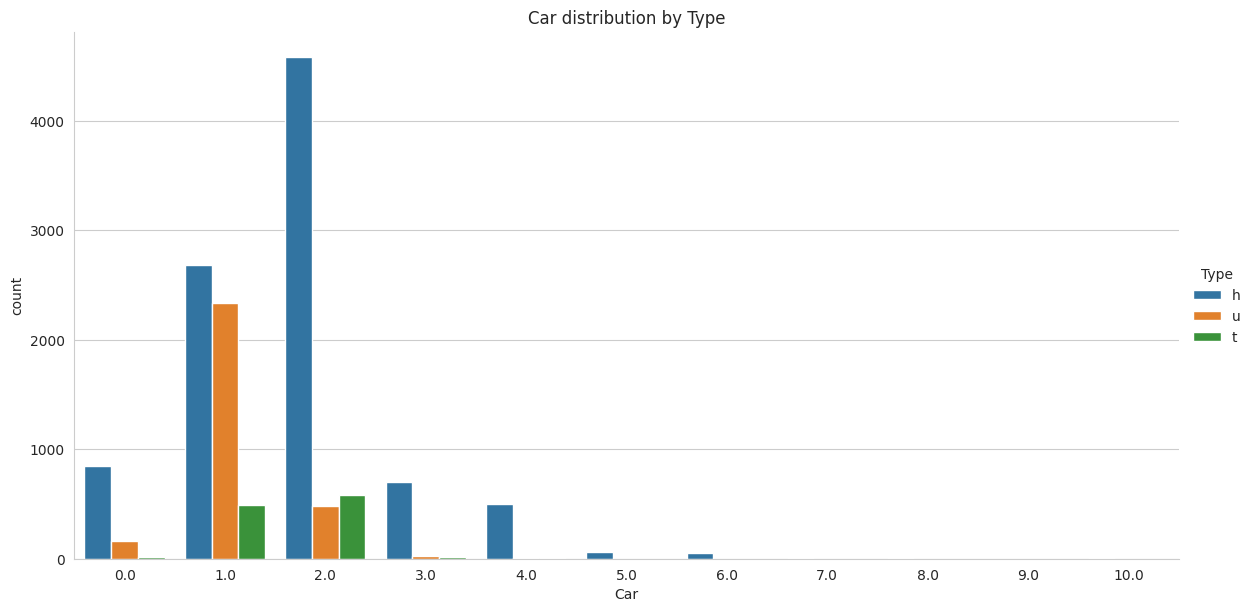

In [63]:
#Plotting in a bar chart
sns.catplot(data=data, x="Car", kind="count", hue="Type", height=6, 
            aspect=2).set(title="Car distribution by Type")

#### 3.1.9. LandSize

Text(0.5, 1.0, 'Boxplot Diagram - LandSize')

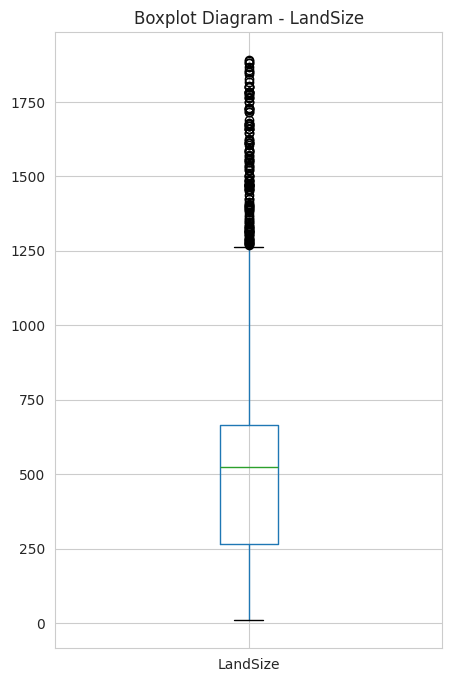

In [64]:
#Plotting the boxplot for 'LandSize'
data.boxplot(column = ['LandSize'], figsize = [5, 8])
plt.title("Boxplot Diagram - LandSize")

Text(0.5, 1.0, 'Histogram - LandSize')

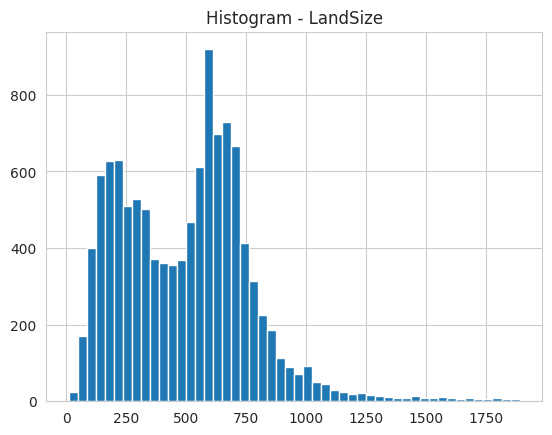

In [65]:
#Plotting the Histogram for 'LandSize'
data.hist(column = ['LandSize'], bins=50)
plt.title("Histogram - LandSize")

It can be seen by the boxplot and histogram that that most of the data lies in between 0 and 1000, with the median falling at around 500 square metres. However, there are lands which exceed the size of 1000.

In [66]:
# Report valid minimum and maximum land sizes, ignoring missing values.
print('Maximum LandSize:', data['LandSize'].max())
print('Minimum LandSize:', data['LandSize'].min())

Maximum LandSize: 1890.0
Minimum LandSize: 10.0


We should keep it mind that "LandSize" was subjected to outlier treatment earlier, so the new maximum landsize of a Melbourne property in the dataset is 1890, and the new minimum landsize is 10.0 after applying the cap.

#### 3.1.10. BuildingSize

Text(0.5, 1.0, 'Boxplot - Building Size')

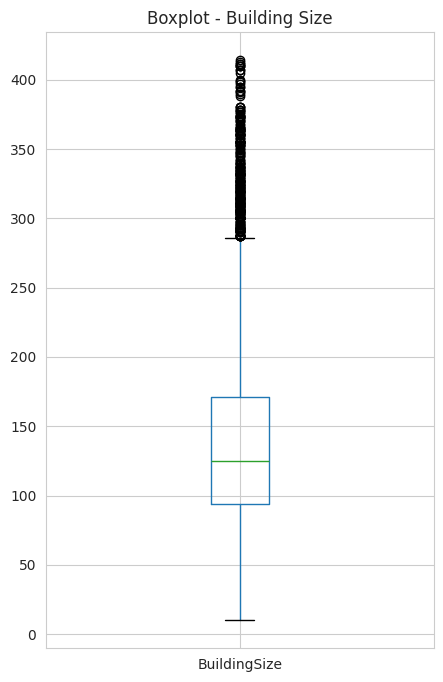

In [67]:
# Plotting the boxplot for 'BuildingSize'
data.boxplot(column = ['BuildingSize'], figsize = [5, 8])
plt.title("Boxplot - Building Size")

Text(0.5, 1.0, 'Histogram - Building Size')

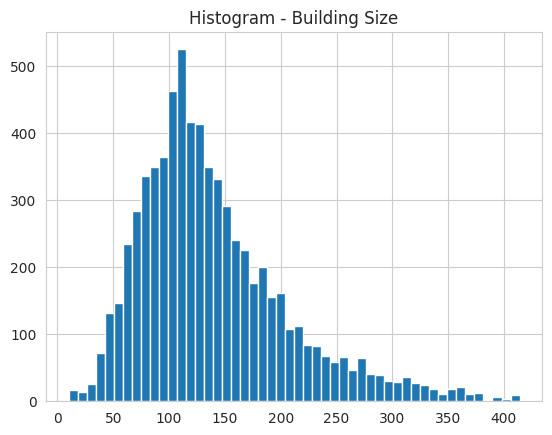

In [68]:
#Plotting the Histogram for 'BuildingSize'
data.hist(column = ['BuildingSize'], bins=50)
plt.title("Histogram - Building Size")

In [69]:
#Determining the value count of the dataframe 'BuildingSize'
data["BuildingSize"].value_counts().head()

BuildingSize
120.0    114
110.0     89
100.0     88
130.0     84
115.0     77
Name: count, dtype: int64

According to the boxplot, it can be seen that most of the data lies in between the region of 100 and 150 which subsequently referes to that most of the houses which have been sold are having a building size of 100 to 170. However, it also can be seen there are houses with large scale building areas which is over 400 square metres.

To determine the most frequent size of the building areas in the houses which were sold in the Melbourne area according to the dataset 'value.counts()' feature was used. Accordingly the most number of houses which have been sold consists of 120.0 square meters which is followed by 110.0 square meters and 130.0 square meters.

<Axes: title={'center': 'Top 20 Building Areas'}, xlabel='BuildingSize'>

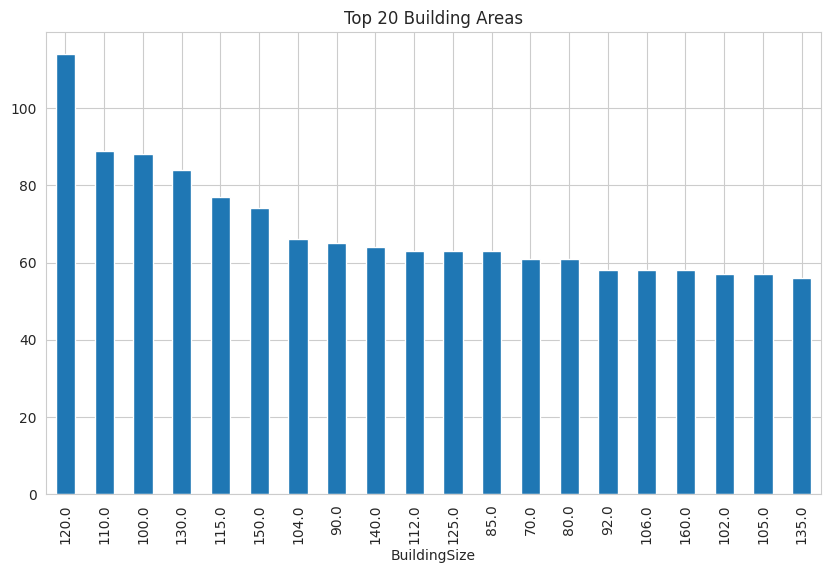

In [70]:
#Defining the size of the plot and plotting the bar chart from largest
plt.figure(figsize = (10,6))
plt.title("Top 20 Building Areas")
data["BuildingSize"].value_counts().nlargest(20).plot.bar()

Through the following graph it can be seen the 20 most frequent building sizes of the houses which have been sold in the Melbourne area according to the selected dataset. Thus, it can be concluded that the most frequent sizes of a property are around 70-160 square metres.

#### 3.1.11. PropertyCount

Text(0.5, 1.0, 'Boxplot Diagram - PropertyCount')

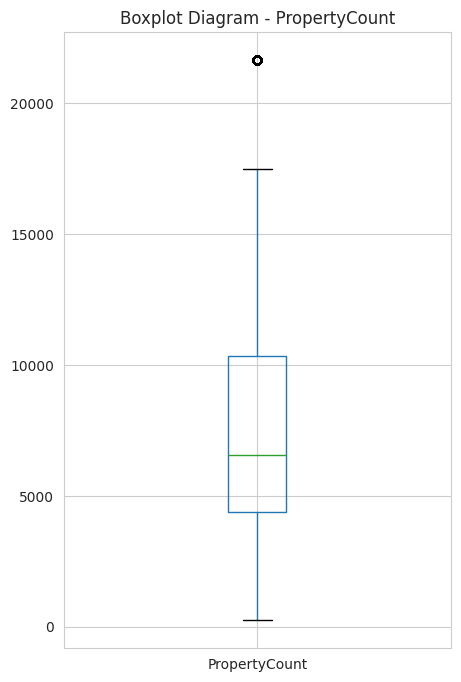

In [71]:
#Plotting the boxplot for 'PropertyCount'
data.boxplot(column = ['PropertyCount'], figsize = [5, 8])
plt.title("Boxplot Diagram - PropertyCount")

Text(0.5, 1.0, 'Histogram - PropertyCount')

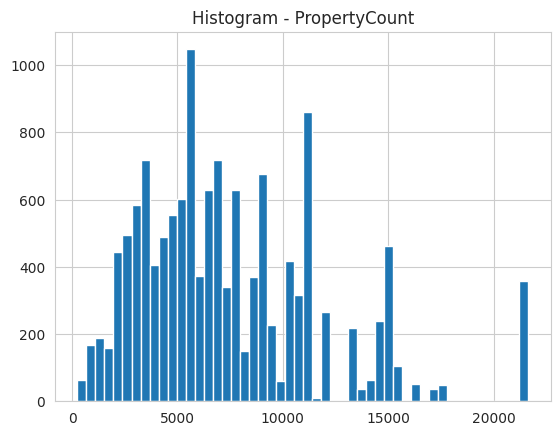

In [72]:
#Plotting the Histogram for 'PropertyCount'
data.hist(column = ['PropertyCount'], bins=50)
plt.title("Histogram - PropertyCount")

We can see that most suburbs have a PropertyCount of between 5000 and 10000.

Text(0.5, 1.0, 'Scattered Data (Heatmap) - Property Count')

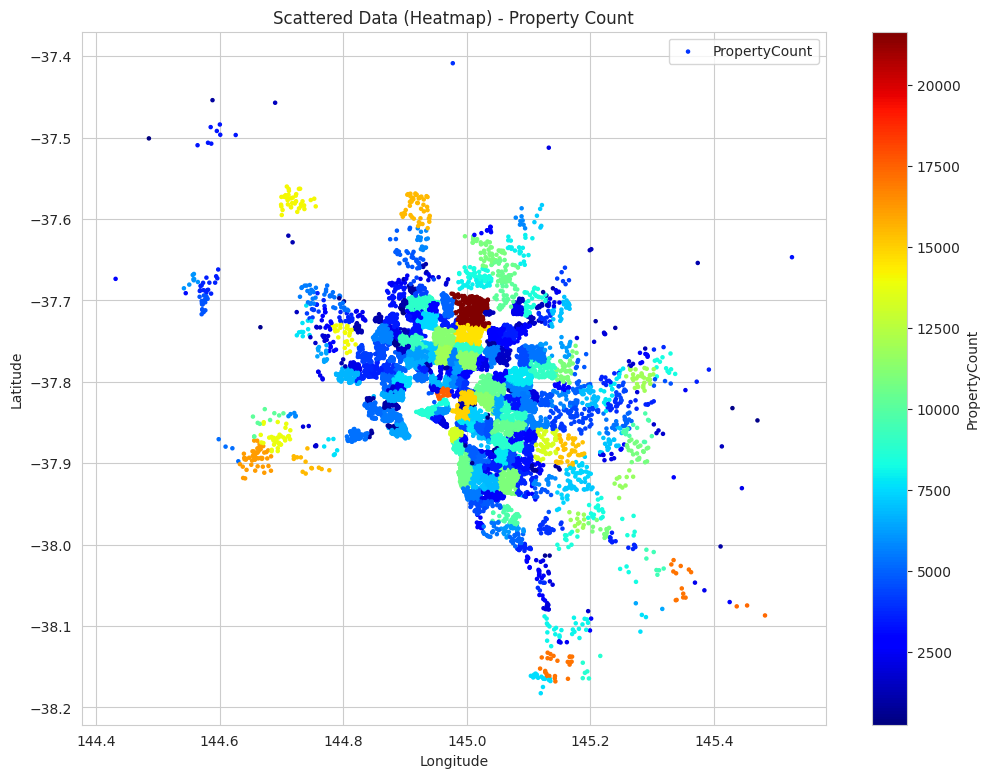

In [73]:
#Plotting the heatmap to identify the property distribution
data.plot(kind = "scatter", x = "Longitude", y = "Latitude", figsize =(12, 9), s = 5, 
          label = "PropertyCount", c = "PropertyCount", colormap = plt.get_cmap("jet"))
plt.title("Scattered Data (Heatmap) - Property Count")

To have a clear understanding on the distribution of the properties in the Melbourne area, a heatmap was plotted. Through this heatmap it can be seen that the red areas have higher numbers of properties and the blue color areas have a lower number of properties.

#### 3.1.12. YearBuilt

Text(0.5, 1.0, 'Boxplot Diagram - Year Built')

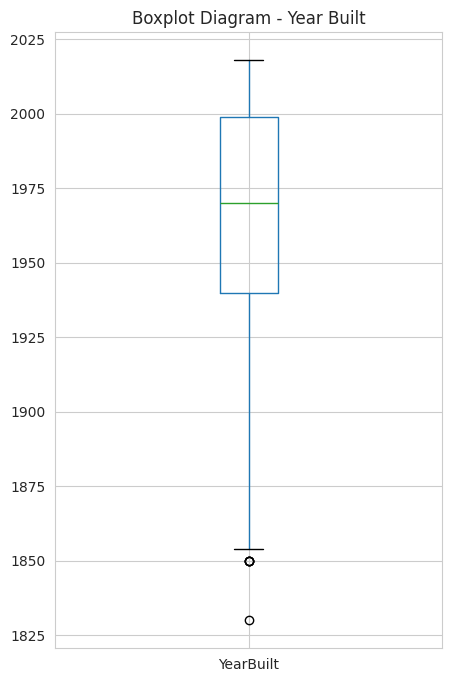

In [74]:
#Plotting the boxplot for 'YearBuilt'
data.boxplot(column = ['YearBuilt'], figsize = [5, 8])
plt.title('Boxplot Diagram - Year Built')

<Axes: title={'center': 'Barchart - Year Built'}, xlabel='YearBuilt'>

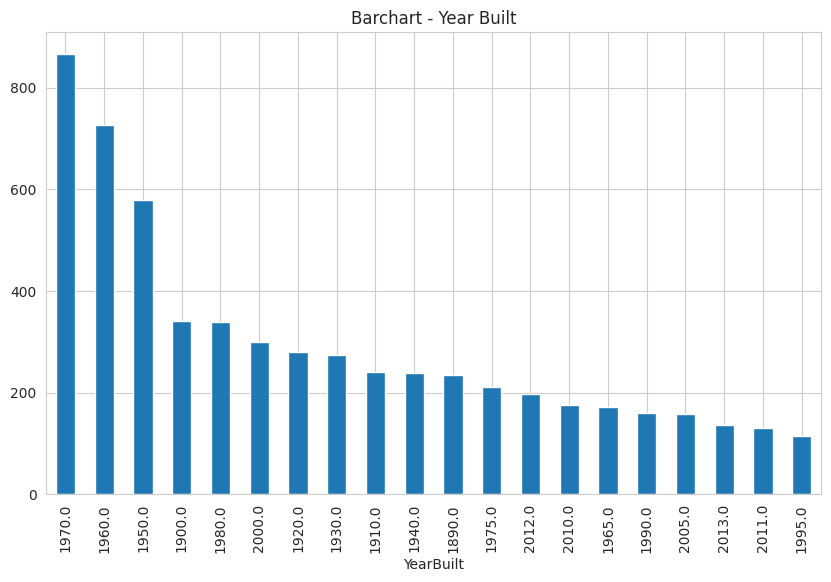

In [75]:
#Defining the size of the plot and plotting the bar chart from largest
plt.figure(figsize = (10,6))
plt.title('Barchart - Year Built')
data["YearBuilt"].value_counts().nlargest(20).plot.bar()

In [76]:
#Determining the value count of the dataframe 'YearBuilt'
data["YearBuilt"].value_counts().head()

YearBuilt
1970.0    866
1960.0    726
1950.0    580
1900.0    341
1980.0    338
Name: count, dtype: int64

In the analysis of the year of the properties which were built, from the boxplot diagram it can be seen most of the houses were built in between the years of 1940 - 2000. Thus, to have a clear understanding on the years of the properties which were built a bar chart was plotted.

According to the bar chart it can be seen that the most frequent year built of a house is 1970. In this specific year it was recorded that 866 houses was built. Moreover, it can also be seen that 726 houses were built in 1960 and 580 houses were built in 1950. It can be seen that the most popular years built end with 0. A reason for this could be that the exact year built is not known, so the beginning of that decade is provided as the year built.


Thus, by looking at these data it can be concluded that most of the houses which were sold are more than 50 years of age.

### 3.2. Analysing categorical variables


#### 3.2.1. Region

In [77]:
# Check how many entries there are in each region
data["Region"].value_counts()

Region
Southern Metropolitan         4695
Northern Metropolitan         3890
Western Metropolitan          2948
Eastern Metropolitan          1471
South-Eastern Metropolitan     450
Eastern Victoria                53
Northern Victoria               41
Western Victoria                32
Name: count, dtype: int64

([0, 1, 2, 3, 4, 5, 6, 7],
 [Text(0, 0, 'Northern Metropolitan'),
  Text(1, 0, 'Western Metropolitan'),
  Text(2, 0, 'Southern Metropolitan'),
  Text(3, 0, 'Eastern Metropolitan'),
  Text(4, 0, 'South-Eastern Metropolitan'),
  Text(5, 0, 'Eastern Victoria'),
  Text(6, 0, 'Northern Victoria'),
  Text(7, 0, 'Western Victoria')])

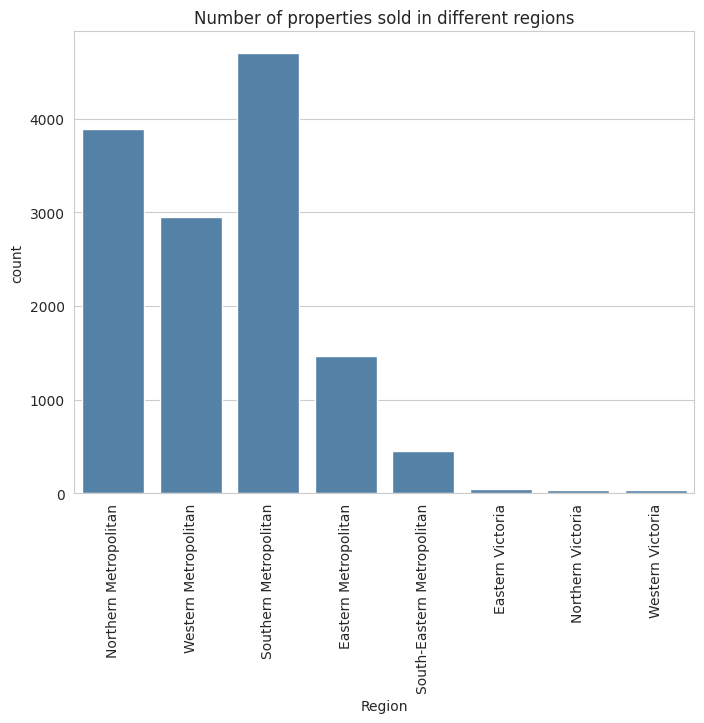

In [78]:
# Visualising
plt.figure(figsize = (8,6))
sns.countplot(data=data, x="Region", color="steelblue").set(title="Number of properties sold in different regions")
plt.xticks(rotation = 90)

In [79]:
px.pie(data, names="Region", title="Proportion of properties sold in different regions", 
       color_discrete_sequence=px.colors.sequential.Aggrnyl)

- It makes sense that most of the properties are in the Metropolitan areas of Melbourne, with southern accounting for over a third of the properties sold in this period. This is followed by Northern Metropolitan and Western Metropolitan, at 28.6% and 21.7%, respectively.

Text(0.5, 1.0, 'Price distribution of different regions')

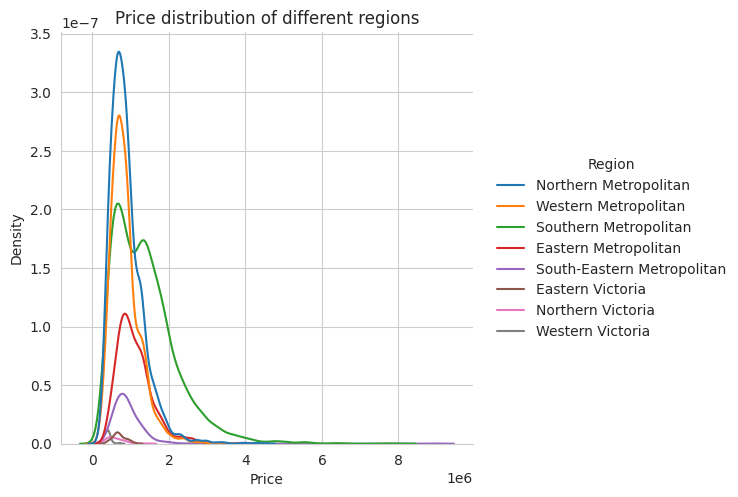

In [80]:
# Price distribution plot
sns.displot(data, x="Price", hue="Region", kind="kde")
plt.title("Price distribution of different regions")

In [81]:
region_avg = data.groupby(["Region"], as_index=False).mean(numeric_only=True)
region_avg

,Region,Rooms,Price,DistanceCBD,Postcode,Bedroom,Bathroom,Car,LandSize,BuildingSize,YearBuilt,Latitude,Longitude,PropertyCount
0,Eastern Metropolitan,3.322230,1.104080e+06,13.901088,3111.162475,3.313392,1.698844,1.793338,619.828348,163.777570,1972.782609,-37.788820,145.129184,5713.788579
1,Eastern Victoria,3.396226,6.999808e+05,34.209434,3567.584906,3.396226,1.811321,2.056604,779.854167,170.908621,1984.032258,-37.959292,145.324428,8872.358491
2,Northern Metropolitan,2.755527,8.981711e+05,8.078329,3071.360925,2.734190,1.367866,1.457069,425.116806,120.895173,1962.764286,-37.747258,144.981176,9485.602057
3,Northern Victoria,3.560976,5.948293e+05,33.748780,3418.707317,3.560976,1.853659,1.926829,728.250000,162.351111,1986.666667,-37.599620,144.838486,4260.975610
4,South-Eastern Metropolitan,3.360000,9.229438e+05,23.813556,3225.255556,3.355556,1.657778,2.044444,598.550926,154.455819,1976.859504,-37.993727,145.145865,6589.366667
5,Southern Metropolitan,2.860916,1.372963e+06,8.756656,3156.714590,2.831310,1.624068,1.578701,518.398988,145.099081,1960.523777,-37.866981,145.034312,7622.279233
6,Western Metropolitan,3.023406,8.664205e+05,10.104579,3031.781208,2.990502,1.501018,1.697422,467.169932,141.504801,1968.155192,-37.782382,144.862512,5561.785957
7,Western Victoria,3.406250,3.975234e+05,30.753125,3337.687500,3.406250,1.468750,1.843750,655.500000,134.683810,1982.565217,-37.695163,144.569906,4191.156250


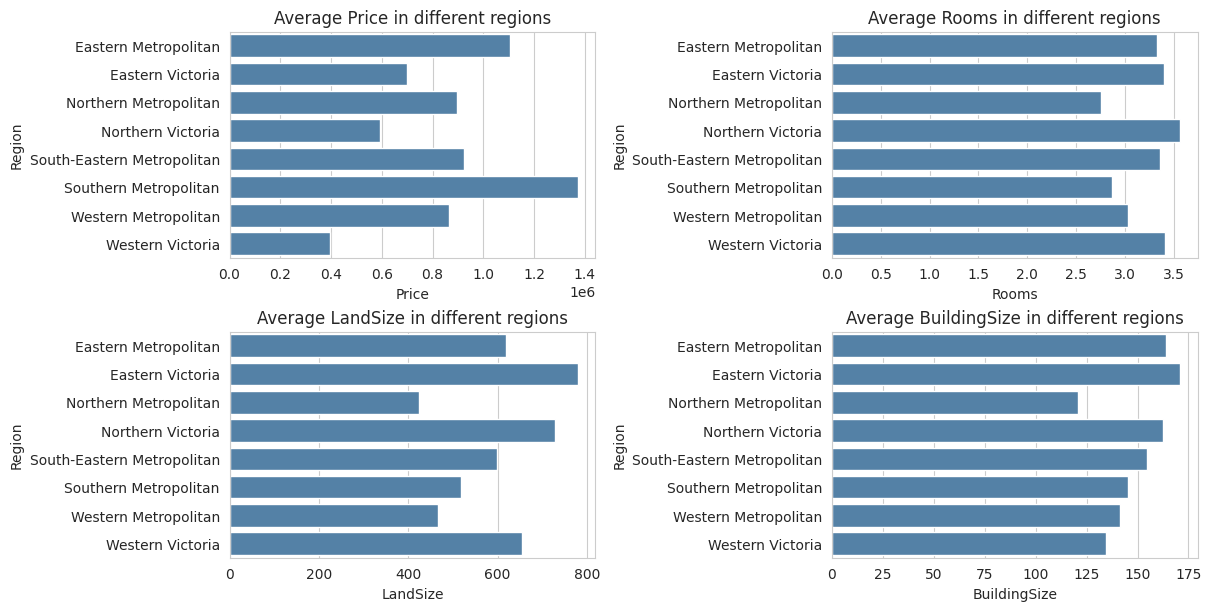

In [82]:
# plotting some key variables
var = ["Price", "Rooms", "LandSize", "BuildingSize"]
colour = ["g", "r", "b", "m"]

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(12,6), constrained_layout=True)
ax = ax.flatten()

for n in range(len(ax)):
    ax[n].set_title(f"Average {var[n]} in different regions")
    sns.barplot(x=var[n], y="Region", data=region_avg, ax=ax[n], orient="h", color="steelblue")

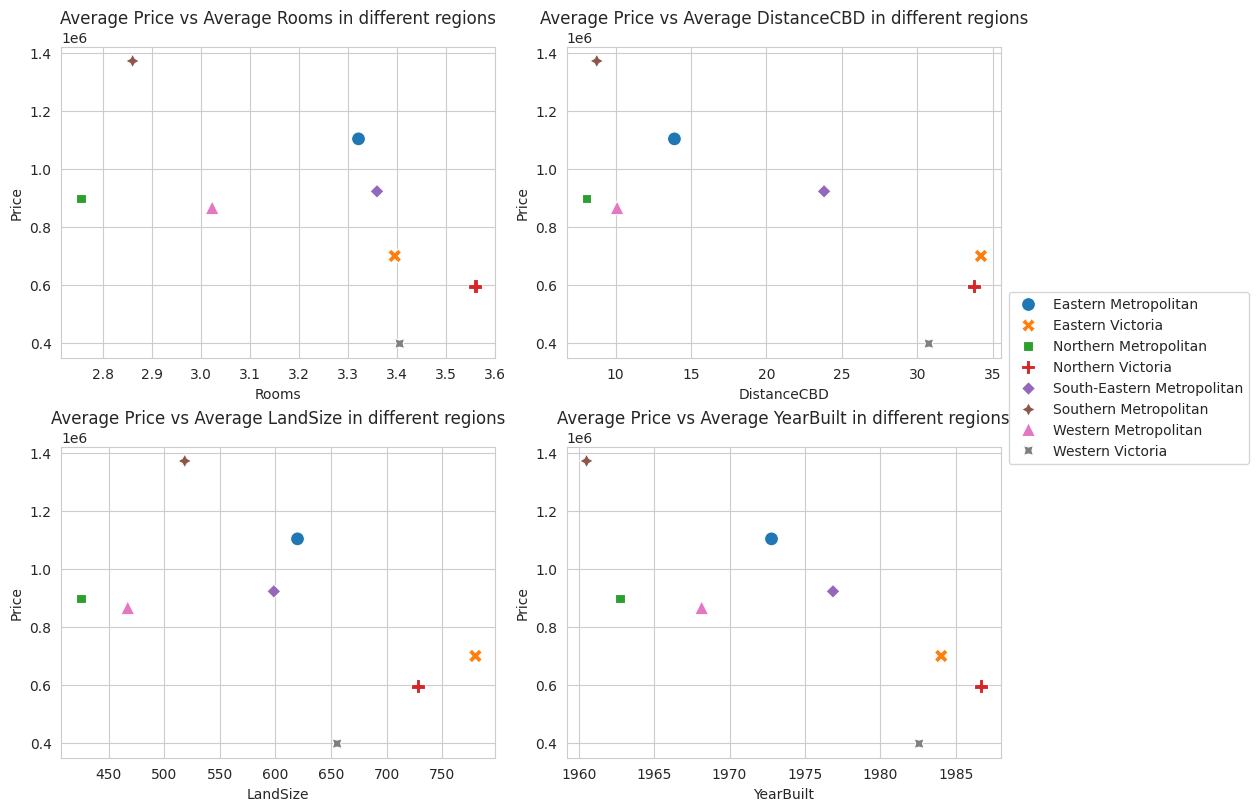

In [83]:
var=["Rooms", "DistanceCBD", "LandSize", "YearBuilt"]

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(10, 8), constrained_layout=True)
ax = ax.flatten()

for n in range(len(ax)):
    ax[n].set_title(f"Average Price vs Average {var[n]} in different regions")
    sns.scatterplot(data=region_avg, x=var[n], y="Price", hue="Region", 
                    style="Region", ax=ax[n], s=100)
    ax[n].legend_.remove()
handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(1.25,0.65))

- It should be noted that prices on the graph are in million Australian dollar.
- We can see that metropolitan areas' house prices are generally higher, especially Southern and Eastern Metropolitan where average prices are over one million Australian dollars.
- However, even with the high price, Southern Metropolitan properties has fewer rooms and smaller land size on average. It also has older houses than other areas.
- Northern Metropolitan area stands out with fewer Rooms, as well as smaller LandSize and BuildingSize than other regions. This can be explained by the fact that it is the area closest to the Central Business District.
- Meanwhile, Northern, Eastern, and Western Victoria properties tend to have more rooms and bigger land size for their price. It is important to note that there are fewer data points for these regions, so they may not reflect the area well. Nevertheless, it makes sense for properties further from the city to be better value for money. They are also more recently built, likely as a result of urban sprawl.

Text(0.5, 1.0, 'Car vs LandSize in different regions')

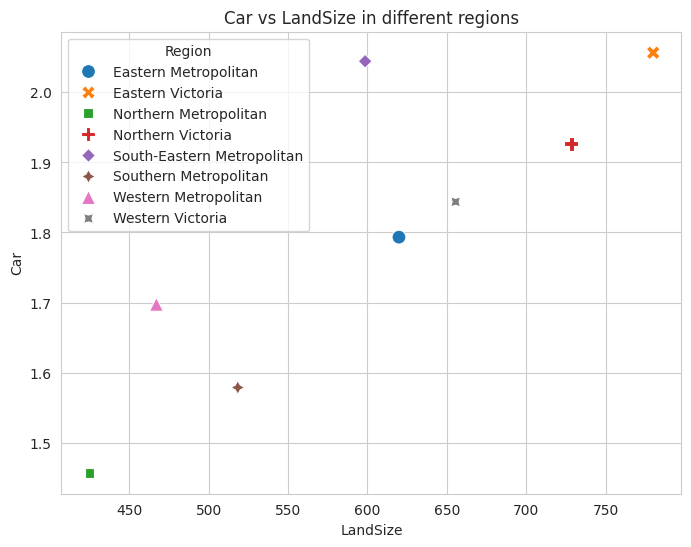

In [84]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=region_avg, x="LandSize", y="Car", hue="Region", style="Region", s=100)
plt.title("Car vs LandSize in different regions")

- This graph is to show the Regions and see how its various LandSize can accomodate different number of carspots. We can see quite a linear relationship here, except for in South-Eastern and Western Metropolitan where the average Car/LandSize ratio is higher. 

#### 3.2.2. Suburb

In [85]:
# Checking number of suburbs in Melbourne
data["Suburb"].describe()

count         13580
unique          314
top       Reservoir
freq            359
Name: Suburb, dtype: object

- There are 314 suburbs in the data set, with Reservoir having the most properties sold during the snapshot period. Let's see the other suburbs in top 10 with the most properties sold in Melbourne during the snapshot period.

In [86]:
count_s = data.groupby("Suburb", as_index=False).size()
count_s = count_s.rename(columns={"size":"PropertySold"})
count_s.sort_values(by=["PropertySold"], ascending=False).head(10)

,Suburb,PropertySold
236,Reservoir,359
237,Richmond,260
30,Bentleigh East,249
234,Preston,239
46,Brunswick,222
118,Essendon,220
259,South Yarra,202
136,Glen Iris,195
147,Hawthorn,191
80,Coburg,190


- Aggregating the Suburb data using the mean. PropertyCount is particularly useful when looking at Suburb, as they depicts the number of properties in each area. 

In [87]:
suburb_avg = data.groupby(["Suburb", "Region"], as_index=False).mean(numeric_only=True)
suburb_avg

,Suburb,Region,Rooms,Price,DistanceCBD,Postcode,Bedroom,Bathroom,Car,LandSize,BuildingSize,YearBuilt,Latitude,Longitude,PropertyCount
0,Abbotsford,Northern Metropolitan,2.410714,1.060366e+06,2.616071,3067.0,2.410714,1.410714,0.946429,231.142857,103.000000,1945.184211,-37.804339,144.997176,4019.0
1,Aberfeldie,Western Metropolitan,3.090909,1.277455e+06,8.627273,3040.0,3.000000,1.863636,1.977273,596.052632,163.692000,1979.100000,-37.759280,144.897587,1543.0
2,Airport West,Western Metropolitan,3.000000,7.566567e+05,12.482090,3042.0,2.865672,1.477612,1.641791,453.171875,135.272895,1984.476190,-37.723399,144.879635,3464.0
3,Albanvale,Western Metropolitan,3.000000,5.370833e+05,14.000000,3021.0,3.000000,1.333333,2.166667,501.166667,123.000000,1980.000000,-37.745640,144.770878,1899.0
4,Albert Park,Southern Metropolitan,2.710145,1.941355e+06,3.230435,3206.0,2.666667,1.434783,0.782609,193.476190,123.485294,1903.756757,-37.844127,144.953107,3280.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
309,Wonga Park,Eastern Victoria,3.000000,9.000000e+05,25.200000,3115.0,3.000000,2.000000,2.000000,NaN,177.000000,NaN,-37.759120,145.288860,1328.0
310,Wyndham Vale,Western Metropolitan,3.500000,4.832500e+05,27.200000,3024.0,3.500000,1.750000,1.500000,488.750000,154.885000,2001.000000,-37.882313,144.614910,5262.0
311,Yallambie,Northern Metropolitan,3.458333,8.396875e+05,14.616667,3085.0,3.500000,1.833333,1.791667,599.375000,174.893333,1982.470588,-37.725967,145.095480,1369.0
312,Yarra Glen,Northern Victoria,3.000000,6.200000e+05,31.400000,3775.0,3.000000,2.000000,1.000000,863.000000,180.560000,1975.000000,-37.653910,145.373890,1160.0


- We can also plot to see the relative positions of different regions using Suburb

Text(0.5, 1.0, 'Regions of Melbourne and their suburbs')

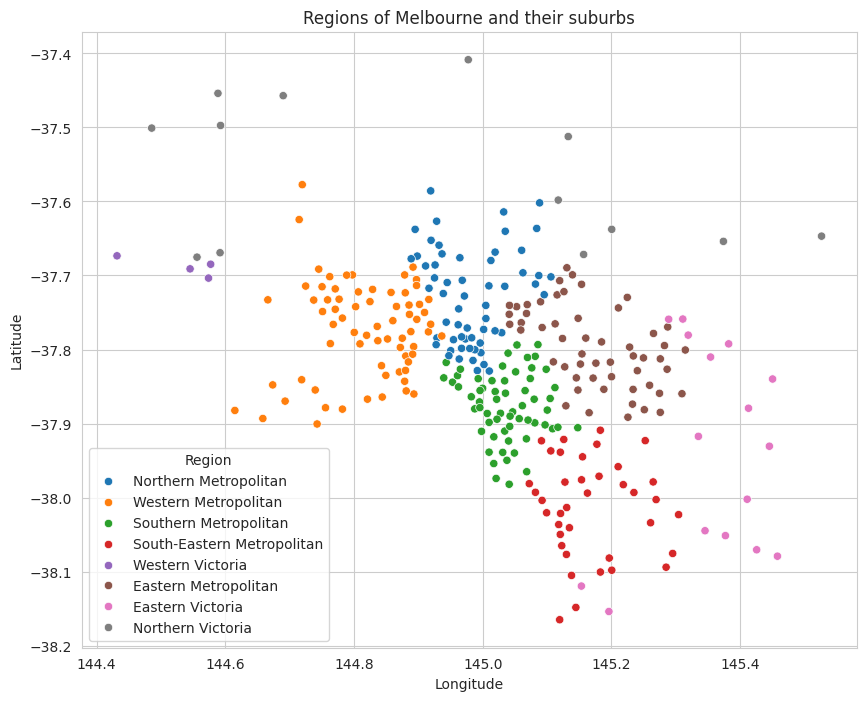

In [88]:
plt.figure(figsize=(10,8))
sns.scatterplot(data=suburb_avg, x="Longitude", y="Latitude", hue="Region")
plt.title("Regions of Melbourne and their suburbs")

- We can plot Suburb on a map with Latitude and Longitude. Here, the colour scale illustrates the average Price, while the marker size represent PropertyCount.

In [89]:
fig = px.scatter_map(suburb_avg, lat="Latitude", lon="Longitude", color="Price", size="PropertyCount",
                        center=dict(lat=-37.8102, lon=144.9628), # centre of Melbourne coordinate
                        zoom=10, map_style="open-street-map", 
                        hover_name="Suburb",
                        hover_data=["Region"],
                        labels={"Price":"Average Price"},
                        color_continuous_scale="bluered",
                        title="Map of Melbourne with suburb information")
fig.update_layout(width=800, height=600, margin={"r": 0, "l": 0,"t": 50, "b": 0})
fig.show()

- From the map, it is quite clear that Southern Metropolitan suburbs tend to have higher prices than suburbs in other region.

In [90]:
# merge count with suburb_avg
suburb_avg = suburb_avg.merge(count_s)
# we create a new column to indicate how active the property market is in that suburb
# this is measured by the number of properties sold during the period for every 1000 properties
suburb_avg["Activity"] = (suburb_avg["PropertySold"]*1000)/suburb_avg["PropertyCount"]
# see top 10 most active neighbourhoods
suburb_avg.sort_values(by=["Activity"], ascending=False).head(10)

,Suburb,Region,Rooms,Price,DistanceCBD,Postcode,Bedroom,Bathroom,Car,LandSize,BuildingSize,YearBuilt,Latitude,Longitude,PropertyCount,PropertySold,Activity
120,Essendon West,Western Metropolitan,3.346154,1.088000e+06,9.357692,3040.0,3.307692,1.615385,1.653846,459.040000,201.846154,1979.937500,-37.752537,144.886153,588.0,26,44.217687
213,Niddrie,Western Metropolitan,3.000000,9.716280e+05,11.004878,3042.0,2.975610,1.573171,1.500000,504.346154,164.821143,1982.888889,-37.739915,144.885487,2291.0,82,35.792230
270,Sunshine,Western Metropolitan,3.000000,7.150631e+05,12.278378,3020.0,2.972973,1.189189,1.603604,491.660550,124.463111,1959.672727,-37.788130,144.837027,3755.0,111,29.560586
162,Jacana,Northern Metropolitan,2.960000,5.282400e+05,14.260000,3047.0,2.960000,1.080000,1.640000,604.760000,106.778235,1963.882353,-37.687099,144.911229,851.0,25,29.377203
1,Aberfeldie,Western Metropolitan,3.090909,1.277455e+06,8.627273,3040.0,3.000000,1.863636,1.977273,596.052632,163.692000,1979.100000,-37.759280,144.897587,1543.0,44,28.515878
153,Heidelberg West,Eastern Metropolitan,2.631579,6.445428e+05,9.265789,3081.0,2.552632,1.144737,1.565789,513.121622,96.306154,1962.107143,-37.740372,145.041536,2674.0,76,28.421840
152,Heidelberg Heights,Eastern Metropolitan,2.833333,7.539917e+05,10.107692,3081.0,2.794872,1.358974,1.512821,487.065789,115.460526,1967.409091,-37.742129,145.052653,2947.0,78,26.467594
253,Seddon,Western Metropolitan,2.725806,9.686210e+05,6.237097,3011.0,2.596774,1.403226,0.967742,257.981818,128.810811,1934.560976,-37.806309,144.891131,2417.0,62,25.651634
313,Yarraville,Western Metropolitan,2.890244,9.886155e+05,6.850610,3013.0,2.835366,1.402439,1.542683,359.244898,129.313814,1951.153153,-37.816756,144.884471,6543.0,164,25.064955
203,Moorabbin,Southern Metropolitan,3.078125,9.844336e+05,14.553125,3189.0,3.000000,1.578125,1.921875,549.725806,131.825000,1971.627907,-37.939840,145.049163,2555.0,64,25.048924


- It seems that many suburbs with the most active housing markets are in Western Metropolitan, with 6 suburb in the top 10. Essendon West stands out as the most active neighbourhood with 44 properties sold for every 1000 properties.

In [91]:
# Putting this information on a map
fig = px.scatter_map(suburb_avg, lat="Latitude", lon="Longitude", color="Activity", size="PropertySold",
                        center=dict(lat=-37.8102, lon=144.9628), # centre of Melbourne coordinate
                        zoom=10, map_style="open-street-map", 
                        hover_name="Suburb",
                        hover_data=["Region", "Price"],
                        labels={"Price":"Average Price"},
                        color_continuous_scale="Turbo",
                        title="Map of Melbourne with suburb information")
fig.update_layout(width=800, height=600, margin={"r": 0, "l": 0,"t": 50, "b": 0})
fig.show()

- Our new features are plotted on a map, with Property Sold responsible for determining the size of the marker, and Activity determining the colour on the colour scale. Suburbs' housing markets far away from central Melbourne tend to be not very active, though some less active suburbs are right in the middle of Melbourne, such as Melbourne or Southbank. One hypothesis is that these suburbs are saturated, people have settled in here, and thus the housing markets have cooled down.
- We can also see some Western Metropolitan suburbs being more active than others of the same radius from central Melbourne.

Text(0.5, 1.0, 'PropertyCount vs PropertySold for each Suburb')

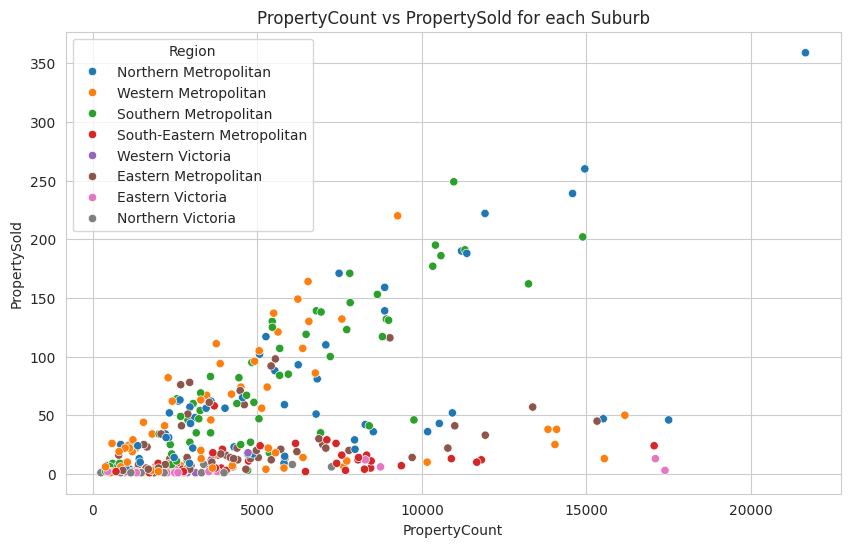

In [92]:
# Plotting PropertyCount against PropertySold
plt.figure(figsize=(10,6))
sns.scatterplot(data=suburb_avg, x="PropertyCount", y="PropertySold", hue="Region")
plt.title("PropertyCount vs PropertySold for each Suburb")

- There seem to be a moderate postitive correlation between PropertySold and PropertyCount in each suburb.

Text(0.5, 1.0, 'Distance to CBD vs Activity for each Suburb')

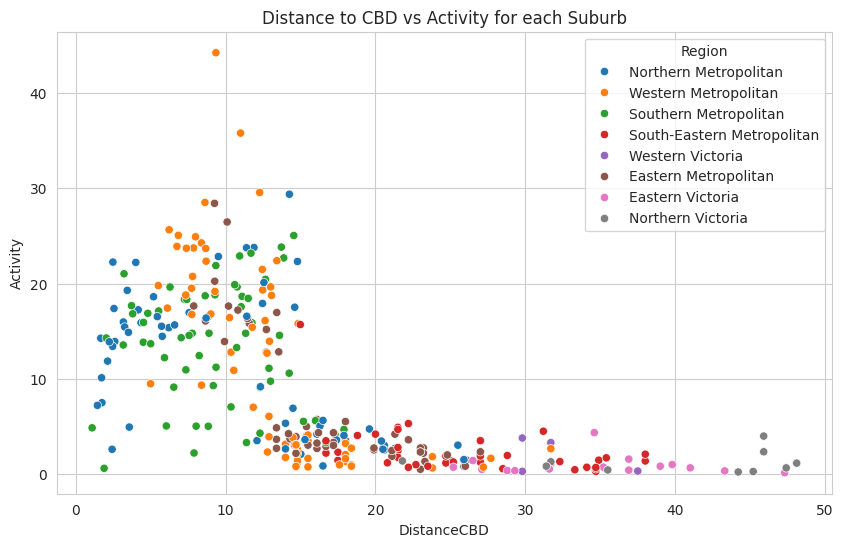

In [93]:
# Plotting DistanceCBD against Activity
plt.figure(figsize=(10,6))
sns.scatterplot(data=suburb_avg, x="DistanceCBD", y="Activity", hue="Region")
plt.title("Distance to CBD vs Activity for each Suburb")

- It looks like there is a negative correlation between DistanceCBD and Activity for each suburb, though the scatter looks more like a curve that starts with a steep climb, peaks at around 10km, goes through a steep decline and flatten out with a long tail. Let's investigate this relationship further in a correlation matrix.

Text(0.5, 1.0, 'Correlation matrix of Melbourne suburbs')

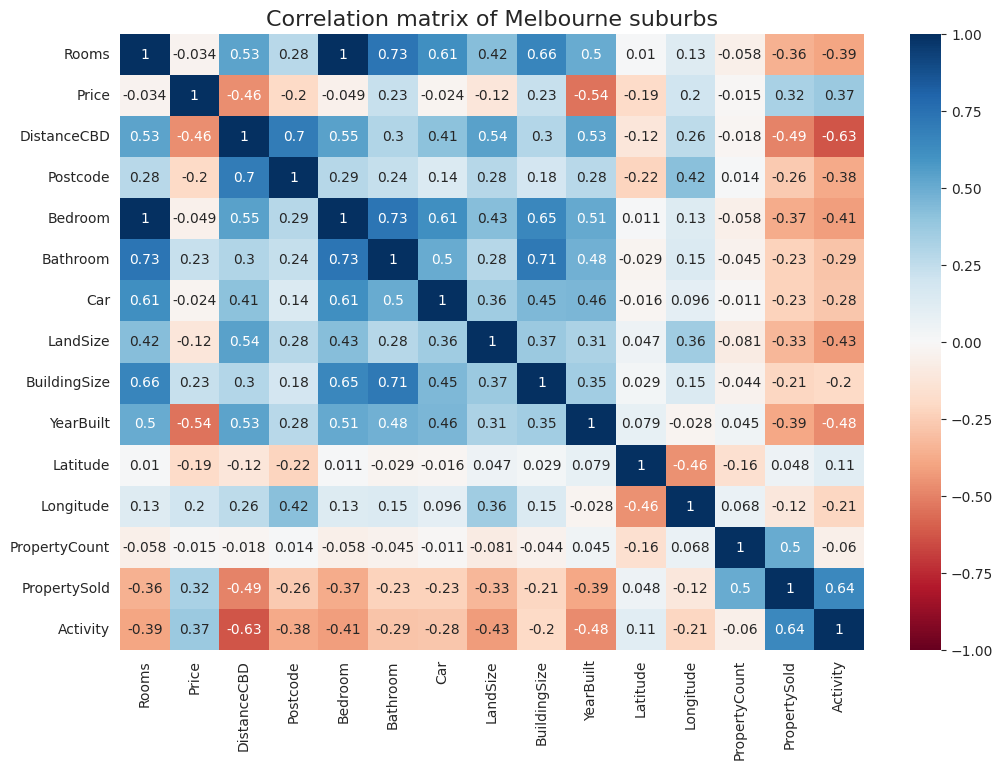

In [94]:
# Create a correlation matrix for Suburb average
corr_mat = suburb_avg.corr(numeric_only=True)
# Plotting the correlation matrix
# Setting up the plotting area
plt.figure(figsize=(12,8))
# Plotting using heatmap
sns.heatmap(corr_mat, vmin=-1, vmax=1, center=0, annot=True, cmap="RdBu")
plt.title("Correlation matrix of Melbourne suburbs", fontdict={'fontsize': 16})

- As previously mentioned, we can see a moderate, positive correlation between PropertySold and PropertyCount. 
- Activity actually has quite a strong negative correlation with DistanceCBD, as seen in the scatterplot. This means the closer a suburb is to the central business district, the more active its housing market is.
- Another notable correlation found through aggregating Suburb is a moderate, negative association between Price and DistanceCBD. This correlation was extrmely weak when looking at property-level before, at only -0.16. When analysing the data at suburb-level, we can see that generally, suburbs further away from the central business district has cheaper houses on average.
- In accordance with the property-level correlation matrix, Rooms and Bedroom have the strongest correlation of all, having a perfect positive correlation. Rooms also enjoys strong, positive association with Bathroom, Car, BuildingSize. 
- Moreover, there is a moderate, positive correlation between DistanceCBD and Rooms, Car, LandSize, and YearBuilt, meaning properties in suburbs close to the central business district tend to have fewer rooms, fewer carspots, smaller landsize, and tend to be older on average.

#### 3.2.3. Type

In [95]:
# See the count of each type of property
data["Type"].value_counts()

Type
h    9449
u    3017
t    1114
Name: count, dtype: int64

In [96]:
# Visualising the proportion of different property types
px.pie(data, names="Type", title="Proportion of different types of properties sold",
       color_discrete_sequence=px.colors.qualitative.Pastel)

The majority of the properties (69.6%), or 9449 properties, are houses, while just over a fifth of the properties are units (flats). The smallest proportion of properties are townhouses, at just 8.2%, accounting for over 1000 properties.

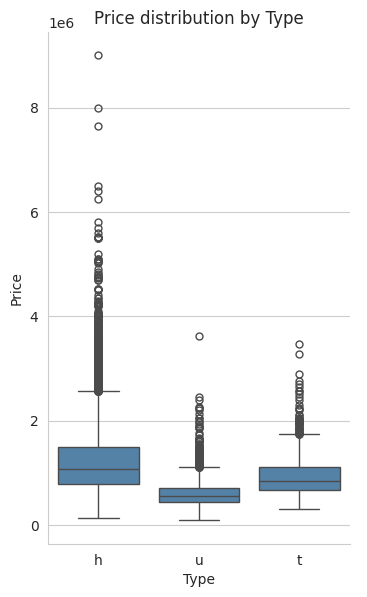

In [97]:
# Investigating Price vs Type
sns.catplot(data=data, x="Type", y="Price", kind="box",
            height=6, aspect=0.6, color="steelblue").set(title="Price distribution by Type")

In [98]:
# Grouping Type by mean
type_avg = data.groupby(["Type"], as_index=False).mean(numeric_only=True)
type_avg

,Type,Rooms,Price,DistanceCBD,Postcode,Bedroom,Bathroom,Car,LandSize,BuildingSize,YearBuilt,Latitude,Longitude,PropertyCount
0,h,3.260874,1.242665e+06,10.979479,3104.080643,3.227431,1.613822,1.772674,529.893875,159.377606,1954.222448,-37.803795,144.994700,7259.025505
1,t,2.837522,9.337351e+05,9.851346,3100.777379,2.814183,1.809695,1.555655,256.499479,138.059629,1998.988189,-37.815782,144.996489,7094.459605
2,u,1.963871,6.051275e+05,7.607391,3110.797481,1.966523,1.183295,1.128936,443.739167,79.857707,1980.016708,-37.823710,144.996363,8199.280080


[Text(0.5, 1.0, 'Average House Prices by Property Type')]

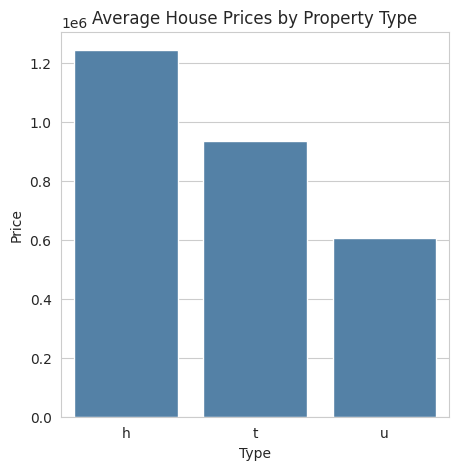

In [99]:
# Average price for each type
plt.figure(figsize=(5, 5))
sns.barplot(data=type_avg, x="Type", y="Price", color="steelblue").set(title="Average House Prices by Property Type")

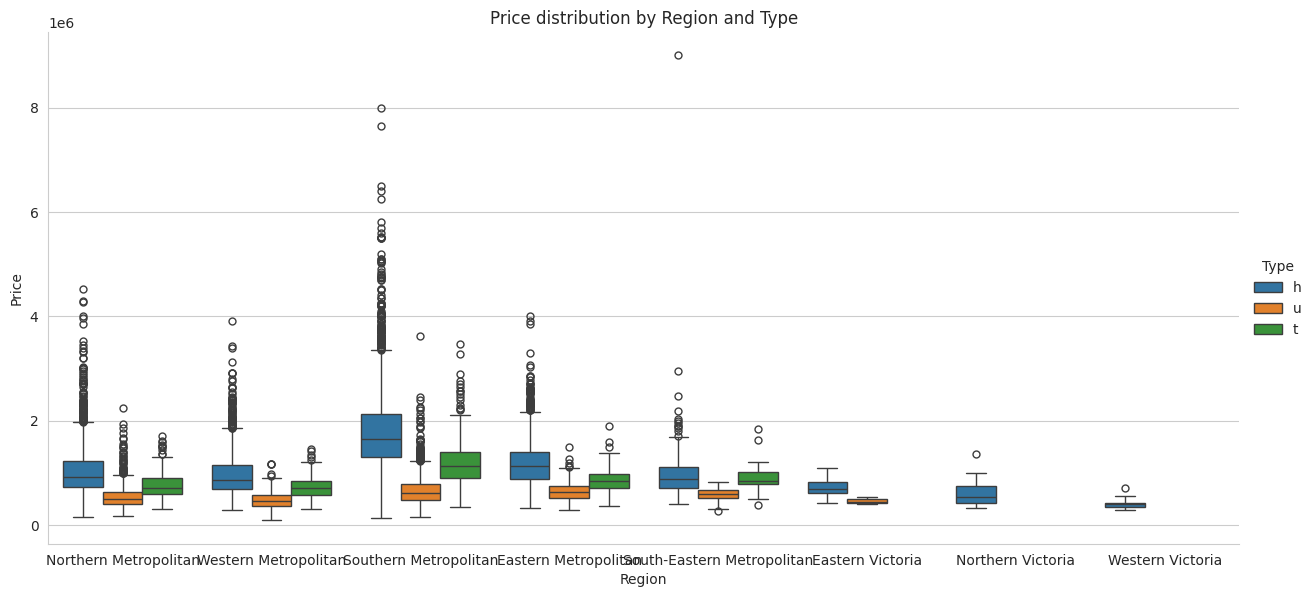

In [100]:
# Investigating prices of different house types in each region
sns.catplot(data=data, x="Region", y="Price", hue="Type", kind="box",
            height=6, aspect=2.1).set(title="Price distribution by Region and Type")

- As we can see, houses are generally more expensive than townhouses, while units (flats) are the cheapest option. Southern Metropolitan seems to be most expensive region to live in, as we have discussed in the previous section.

Text(0.5, 1.05, 'Number of rooms in different property types')

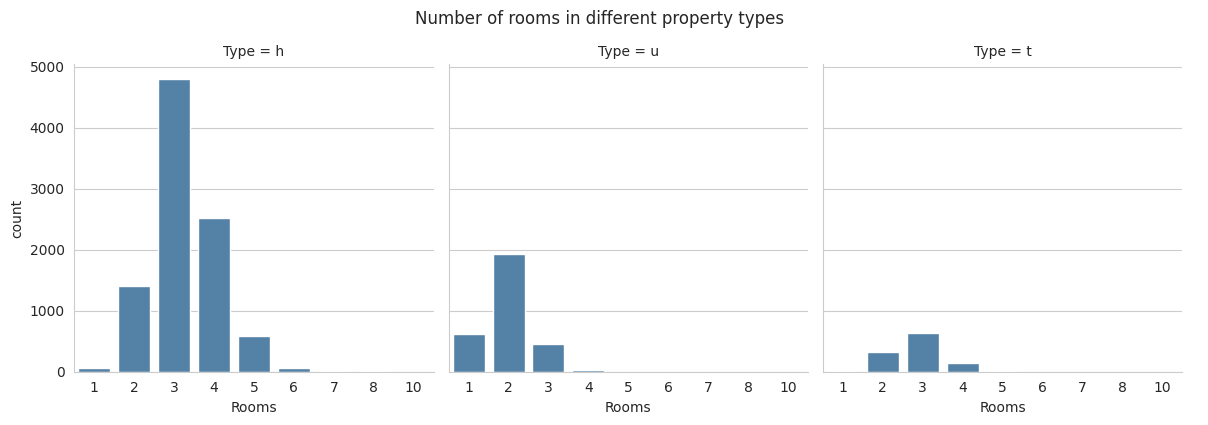

In [101]:
# Analysing number of rooms in each type
sns.catplot(data=data, x="Rooms", col="Type", kind="count", height=4, aspect=1, color="steelblue")
plt.suptitle("Number of rooms in different property types", y=1.05)

The graph shows that most houses (almost 5000) have 3 bedrooms, followed by 4 bedrooms. Units tend to be smaller with most being 2-bed flats. Townhouses also have 3-bed as the most popular option, but this is followed by 2-bed. 

#### 3.2.4. Council

In [102]:
data["Council"].describe()

count           13580
unique             33
top       Unavailable
freq             1370
Name: Council, dtype: object

Unavailble is the most frequent value found in the Council column after cleaning. Other than that, there are 32 unique councils found in the dataset. 

In [103]:
# Plotting the properties by council areas
fig= px.scatter(data[data.Council != "Unavailable"], x="Longitude", y="Latitude", color="Council", 
                hover_data=["Price"], title="Map of Melbourne Council Areas", 
                color_discrete_sequence=px.colors.qualitative.Alphabet)
fig.update_traces(marker=dict(size=7, line=dict(width=0.2, color='DarkSlateGrey')),
                  selector=dict(mode='markers'))
fig.update_layout(width=900, height=700, margin={"r": 50, "l": 90,"t": 70, "b": 70})
fig.show()

We can see a rough outline of different council areas by plotting the property sold.

In [104]:
# Getting the value count of Council
count_c = data.groupby("Council", as_index=False).size()
count_c = count_c.rename(columns={"size":"PropertySold"})
count_c.sort_values(by=["PropertySold"], ascending=False).head(10)

,Council,PropertySold
27,Unavailable,1370
23,Moreland,1163
2,Boroondara,1160
21,Moonee Valley,997
6,Darebin,934
8,Glen Eira,848
26,Stonnington,719
16,Maribyrnong,692
31,Yarra,647
25,Port Phillip,628


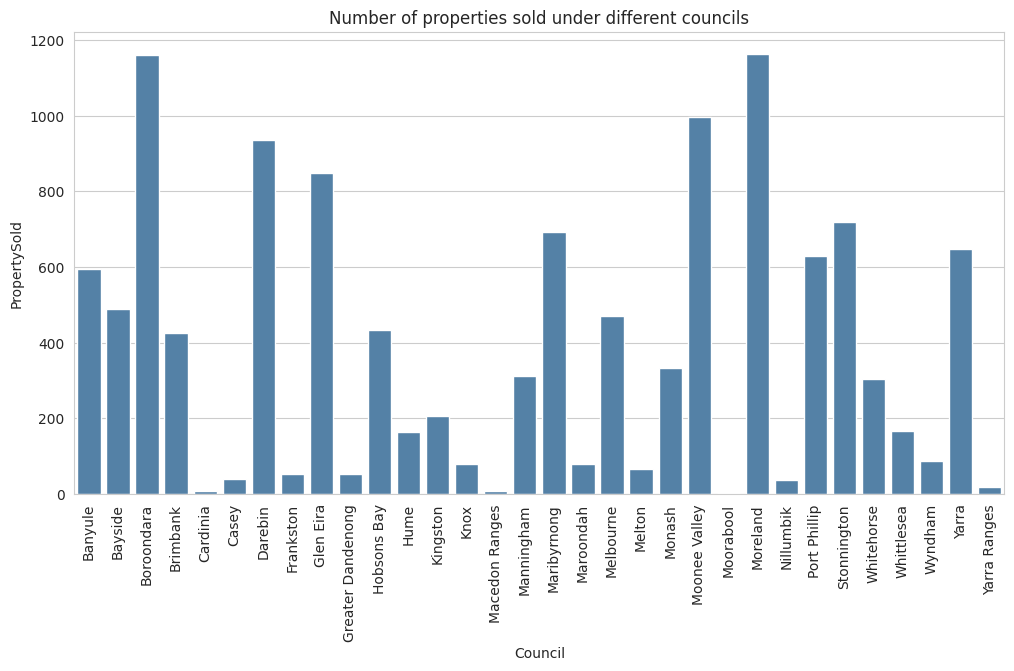

In [105]:
# Plotting count of properties sold under each council
plt.figure(figsize=(12,6))
sns.barplot(data = count_c[count_c.Council != "Unavailable"],
            x = "Council", y="PropertySold", color="steelblue")\
    .set(title="Number of properties sold under different councils")
plt.xticks(rotation=90)
plt.show()

Unavailble has the highest count due to the missing data we encountered. Apart from that, Moreland and Boroondara are the councils with the highest numbers of properties sold during this period. Moorabool is the council with the fewest properties in the dataset, with only one. Indeed, if we look at the map, we can see that this council operates quite far out of Melbourne centre.

In [106]:
# Grouping data by council and aggregating by mean
council_avg = data.groupby("Council", as_index=False).mean(numeric_only=True)
council_avg = council_avg.merge(count_c) # merging the property sold
council_avg.head(10)

,Council,Rooms,Price,DistanceCBD,Postcode,Bedroom,Bathroom,Car,LandSize,BuildingSize,YearBuilt,Latitude,Longitude,PropertyCount,PropertySold
0,Banyule,3.031987,9.444280e+05,11.027441,3083.000000,3.015152,1.496633,1.622896,568.513369,148.981449,1969.170588,-37.740957,145.065046,3445.451178,594
1,Bayside,3.186094,1.652168e+06,12.306339,3187.423313,3.161554,1.871166,1.854806,523.926540,180.670280,1965.637324,-37.926146,145.010322,7496.877301,489
2,Boroondara,3.121552,1.647217e+06,7.761810,3118.804310,3.073276,1.775862,1.756897,588.318993,169.182613,1958.235955,-37.822077,145.062958,8043.870690,1160
3,Brimbank,3.127358,6.472007e+05,13.359670,3023.301887,3.115566,1.377358,1.879717,553.757212,136.401212,1972.534247,-37.767510,144.819741,4540.363208,424
4,Cardinia,3.625000,5.731250e+05,42.487500,3805.375000,3.625000,1.750000,1.625000,681.125000,196.697500,1995.833333,-38.042975,145.426144,7852.000000,8
5,Casey,3.421053,6.564079e+05,32.794737,3753.657895,3.421053,1.842105,2.157895,703.184211,161.463529,1982.863636,-38.025227,145.293367,9792.815789,38
6,Darebin,2.781585,9.158000e+05,8.601178,3072.376874,2.748394,1.327623,1.604925,451.686820,119.391530,1960.700743,-37.741646,145.007302,14643.948608,934
7,Frankston,3.339623,6.589849e+05,37.035849,3310.207547,3.339623,1.660377,1.905660,647.720000,155.880323,1976.941176,-38.130455,145.152686,10144.037736,53
8,Glen Eira,2.831368,1.069279e+06,11.725943,3175.209906,2.794811,1.520047,1.621462,502.773392,137.830000,1968.030593,-37.905150,145.048958,7121.262972,848
9,Greater Dandenong,3.211538,6.970673e+05,23.826923,3173.903846,3.211538,1.326923,2.000000,582.442308,137.202273,1974.260870,-37.971658,145.189343,9506.711538,52


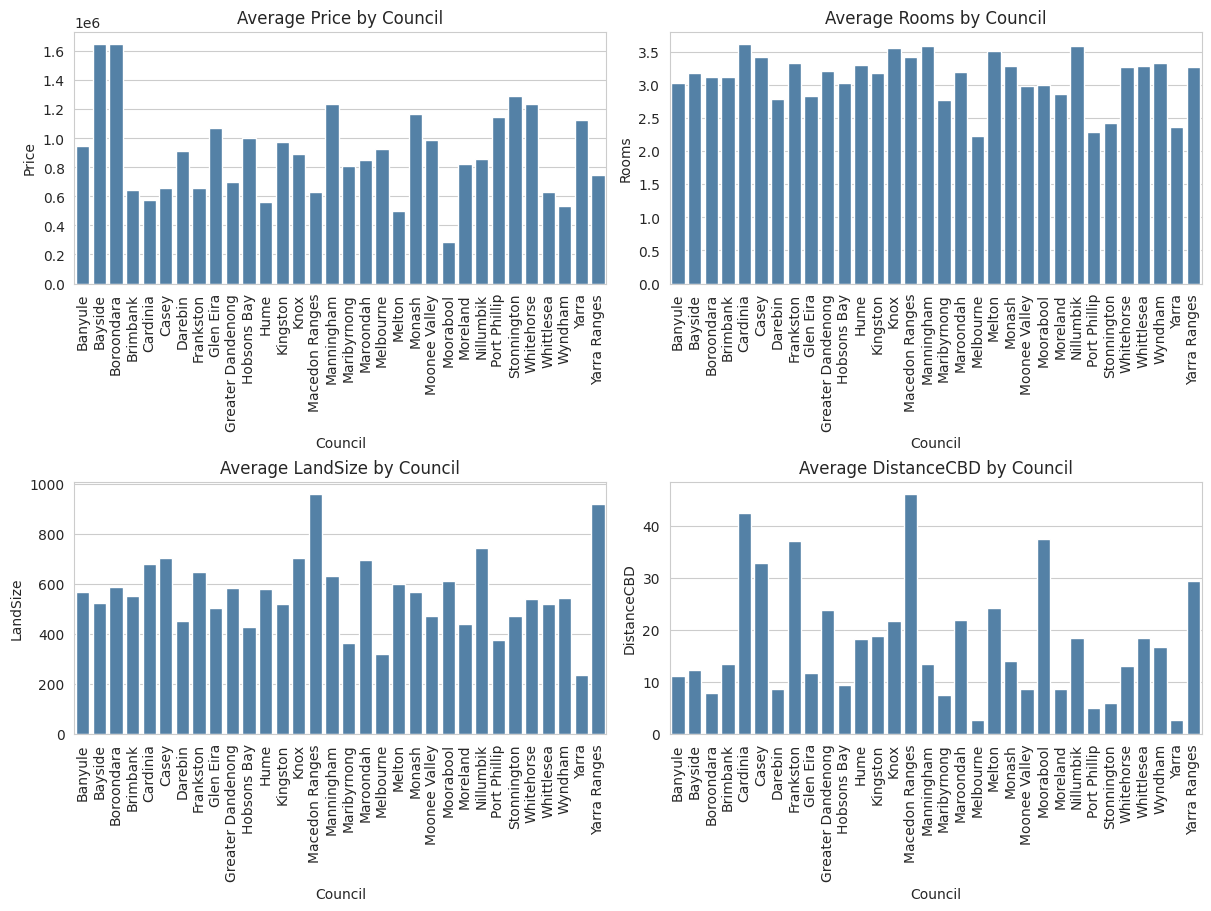

In [107]:
# Plotting to compare councils
# Choosing variables of interest
var = ["Price", "Rooms", "LandSize", "DistanceCBD"]
# Setting up the figure and subplots
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(12,9), constrained_layout=True)
ax = ax.flatten()
# Loop to plot
for i in range(len(var)):
    ax[i].set_title(f"Average {var[i]} by Council")
    sns.barplot(data=council_avg[council_avg.Council != "Unavailable"], 
                x="Council", y=var[i], ax=ax[i], color="steelblue")
    ax[i].tick_params("x", labelrotation=90)

- Bayside and Boroondara have the highest average price. At the same time, we can see that these council areas are not that close to the central business district on average (approximately 12.3km and 7.8km, respectively). We can hypothesise that there is something attractive about these councils outside of the data we have. Bayside, rather obviously, has easy access to the Bay, while Boroondara has the second highest number of properties sold in the snapshot period.
- It can also be said that most council areas with average LandSize over 600 square metres are over 20 kilometres away from the central business district on average. Manningham is an exception to this rule, but the properties sold in this council average at over 1.2 million Australian dollars, higher than most other councils.
- Looking at average rooms, we can see that the council areas with the lowest average are Melbourne, Port Phillip, Yarra, Stonnington, and Maribyrnong. These councils areas are also the closest to the central business district and have the smallest average landsize.

In [108]:
fig = px.scatter_map(council_avg[council_avg.Council != "Unavailable"], 
                        lat="Latitude", lon="Longitude", color="Price", size="PropertySold",
                        center=dict(lat=-37.8102, lon=144.9628), # centre of Melbourne coordinate
                        zoom=10, map_style="open-street-map", 
                        hover_name="Council",
                        hover_data=["Price"],
                        labels={"Price":"Average Price"},
                        title="Map of Melbourne with Council information")
fig.update_layout(width=800, height=600, margin={"r": 0, "l": 0,"t": 50, "b": 0})
fig.show()

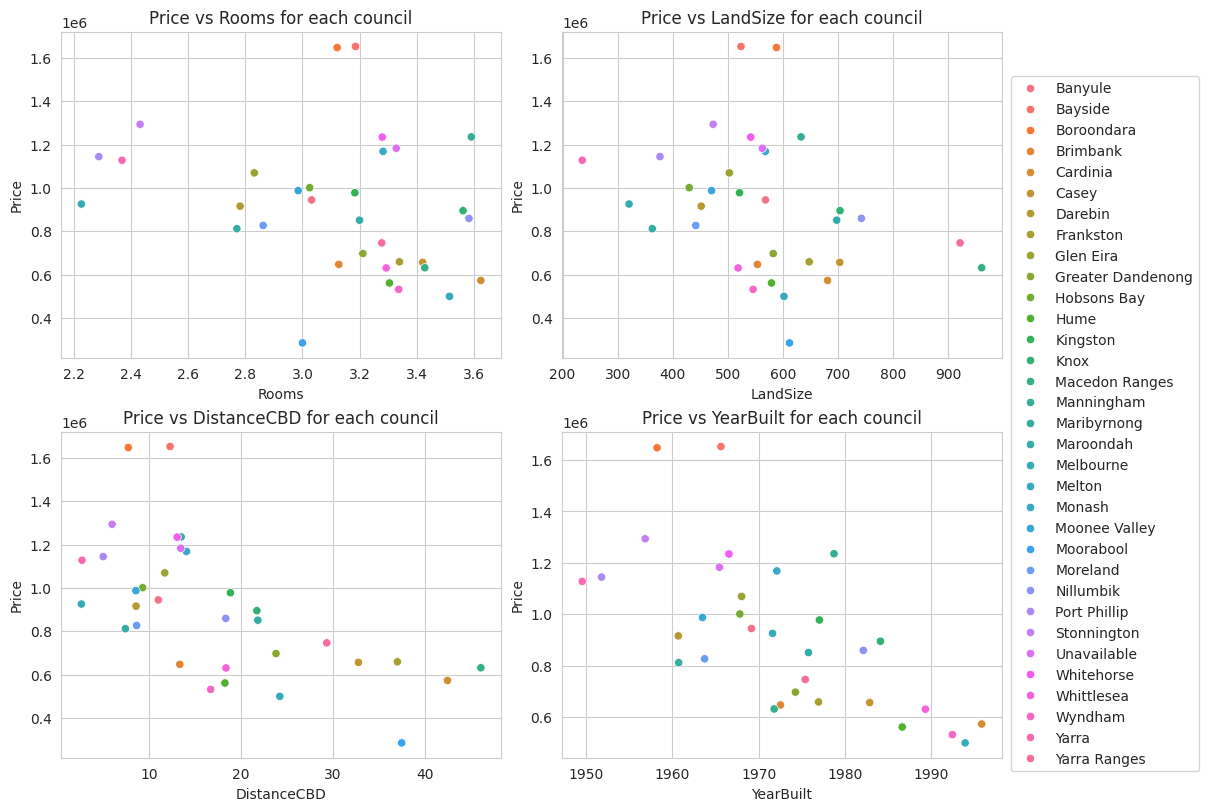

In [109]:
# Plotting to pairwise to see relationship between varibles and price for councils
# Choosing variables of interest
var = ["Rooms", "LandSize", "DistanceCBD", "YearBuilt"]
# Setting up the figure and subplots
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(10,8), constrained_layout=True)
ax = ax.flatten()
# Loop to plot
for i in range(len(var)):
    ax[i].set_title(f"Price vs {var[i]} for each council")
    sns.scatterplot(data=council_avg, x=var[i], y="Price", hue="Council", ax=ax[i])
    ax[i].legend_.remove() # remove individual legends
# create a common legend
handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(1.2,0.92))

It can be seen that Rooms does not correlate well with Price when being aggregated. Let's look at the correlation matrix for Council. A negative correlation can be seen for the rest of the variables, which will be investigated further with a correlation matrix.

Text(0.5, 1.0, 'Correlation matrix of Melbourne council')

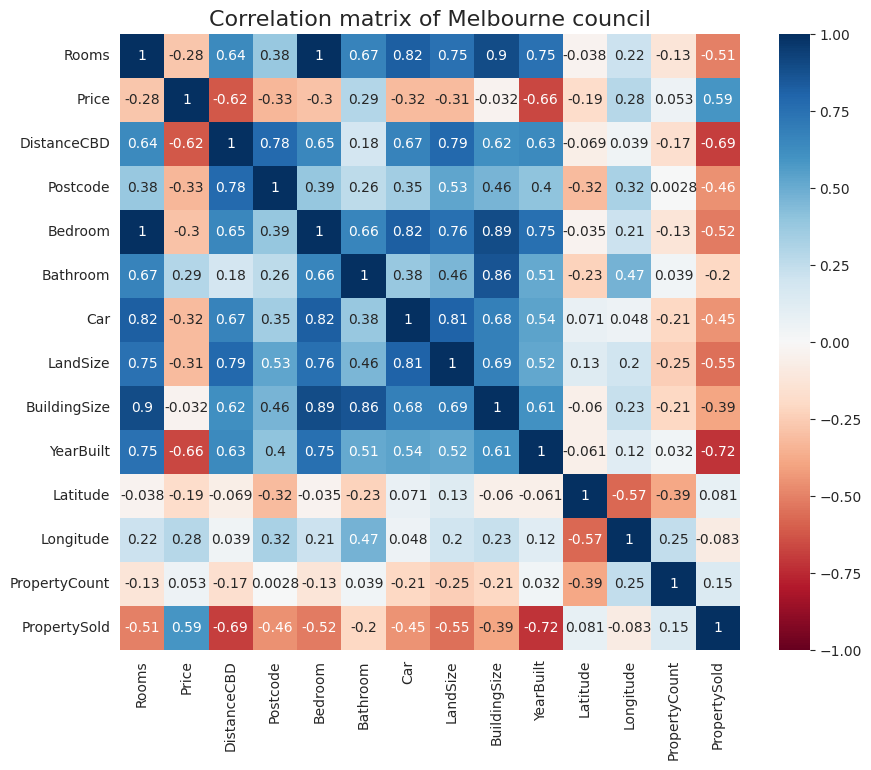

In [110]:
# Create a correlation matrix for Council average
corr_mat = council_avg.corr(numeric_only=True)
# Plotting the correlation matrix
# Setting up the plotting area
plt.figure(figsize=(10,8))
# Plotting using heatmap
sns.heatmap(corr_mat, vmin=-1, vmax=1, center=0, annot=True, cmap="RdBu")
plt.title("Correlation matrix of Melbourne council", fontdict={'fontsize': 16})

- As can be seen, DistanceCBD and YearBuilt have rather strong negative correlations with Price when aggregating by Council. This means that on average, prices are higher in council areas closer to the central business district and in councils where the average age of buildings are higher.
- A lot of correlations appear stronger (or weaker) in the matrix when aggregating by Council because the natural variance of the dataset is cancelled out in such high-level aggregation.

#### 3.2.5. MethodSold

<Axes: title={'center': 'Selling Methods of the Properties'}, xlabel='MethodSold', ylabel='count'>

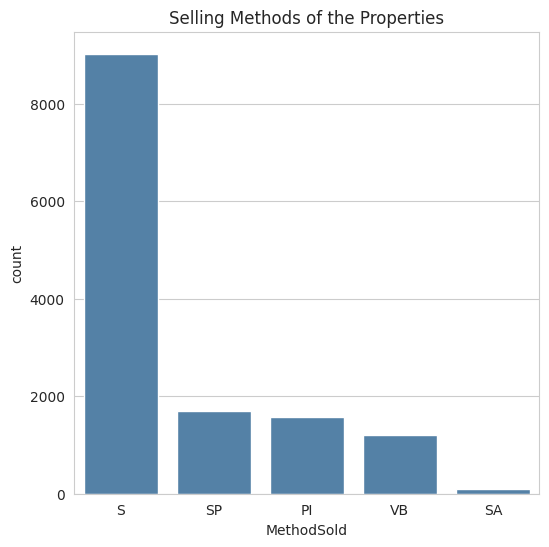

In [111]:
#Defining the size of the plot and plotting a bar graph for 'MethodSold'
plt.figure(figsize = (6,6))
plt.title("Selling Methods of the Properties")
sns.countplot(data = data , x = 'MethodSold', color="steelblue")

In [112]:
#Determining the value count of the dataframe 'MethodSold'
data["MethodSold"].value_counts()

MethodSold
S     9022
SP    1703
PI    1564
VB    1199
SA      92
Name: count, dtype: int64

As can be seen in the above figure, there are several methods and these methods stands for:

1. S    - Property Sold
2. SP   - Property Sold Prior
3. PI   - Property Passed In
4. VB   - Vendor Bid
5. SA   - Sold after Auction

Through the data it can be illustrated that the highest number of houses falls under the 'Property Sold' category which is slightly more than 9000 houses and the least number of houses are Sold after Auction which is nearly 100 houses in the Melbourne.

Text(0.5, 0.98, 'Methods sold in different property types')

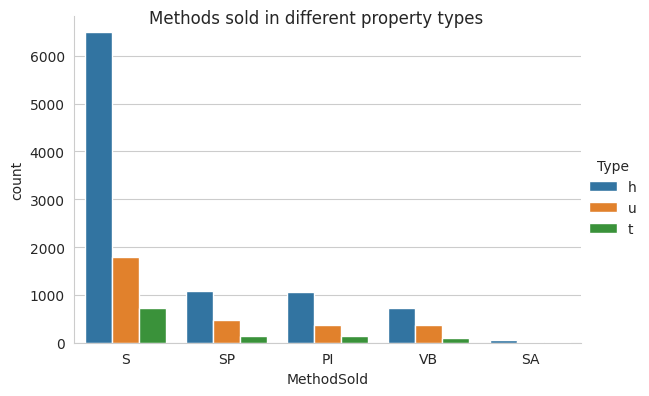

In [113]:
# Plotting MethodSold with property types
sns.catplot(data=data, x="MethodSold", hue="Type", kind="count", height=4, aspect=1.5)
plt.suptitle("Methods sold in different property types")

MethodSold have somewhat similar distribution across different property types, with Property Sold clearly being more popular than the others.

In [114]:
#Plotting the Pie Chart for method sold
px.pie(data, names = "MethodSold", title="Proportion of selling methods used")

To have a clear understanding on the data which were illustrated through the bar chart, a pie chart was plotted. According to the pie chart, 66.4% which is 9022 houses are classified under the Property Sold whilst only 0.677% which is only 92 of the houses are sold after an auction.

The pie chart also illustrates that 8.83% which is 1199 houses, 11.5% which is 1564 houses and 12.5% which is 1703 houses were sold through Vendor Bid, Property Passed In and Property Sold Prior respectively.

Text(0.5, 1.05, 'Type of houses with method sold and pricing')

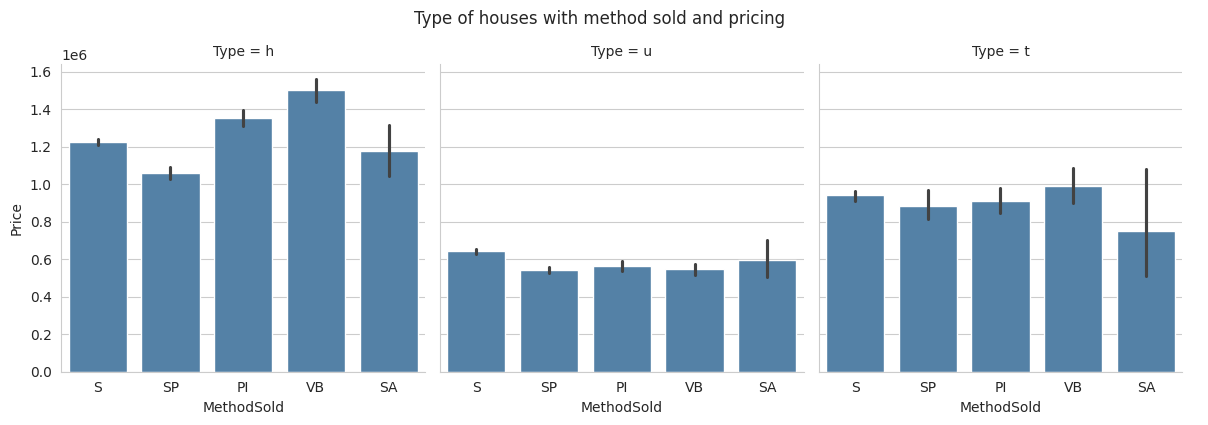

In [115]:
#Plot a bar chart for types of houses against the method sold and price
sns.catplot(data=data, x="MethodSold", y="Price", col="Type", kind ="bar", height=4, aspect=1, color="steelblue")
plt.suptitle("Type of houses with method sold and pricing", y=1.05)

As previously established, houses are generally more expensive than townhouses, which are more expensive than units, regardless of their method sold. While unit prices are quite evenly distributed across different methods, Vendor bid seems to have higher selling prices in houses and townhouses than other method. Sold prior and Sold after auction tend to have lower prices in houses and townhouses.

#### 3.2.6. Agent

In [116]:
# Determining the value count of the column 'Agent'
data["Agent"].value_counts()

Agent
Nelson           1565
Jellis           1316
hockingstuart    1167
Barry            1011
Ray               701
                 ... 
Area                1
SN                  1
PRD                 1
Rexhepi             1
Point               1
Name: count, Length: 268, dtype: int64

There are 268 unique agents in the dataset, which is quite a large number. According to the figures, most of the sales were done by the Nelson, followed by Jellis, hockingstuart, and Barry. They have all sold more than 1000 properties during the period. On the other hand, there are some sellers who have only done one sale during the period.

<Axes: title={'center': 'Top 10 Agents'}, xlabel='Agent'>

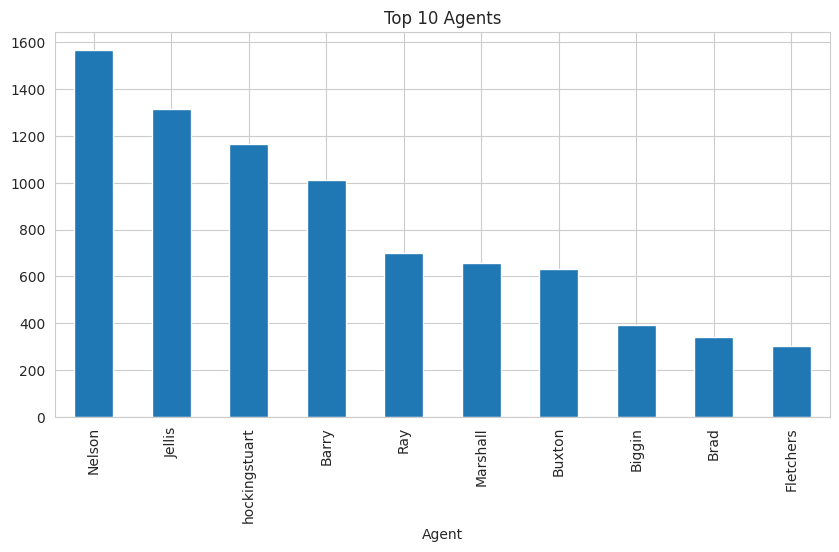

In [117]:
# Analyse the top sellers
top10 = data["Agent"].value_counts().nlargest(10)
# Defining the size of the plot and plotting the bar chart
plt.figure(figsize = (10,5))
plt.title("Top 10 Agents")
top10.plot.bar()

Text(0.5, 1.0, 'Top 10 agents and their selling methods')

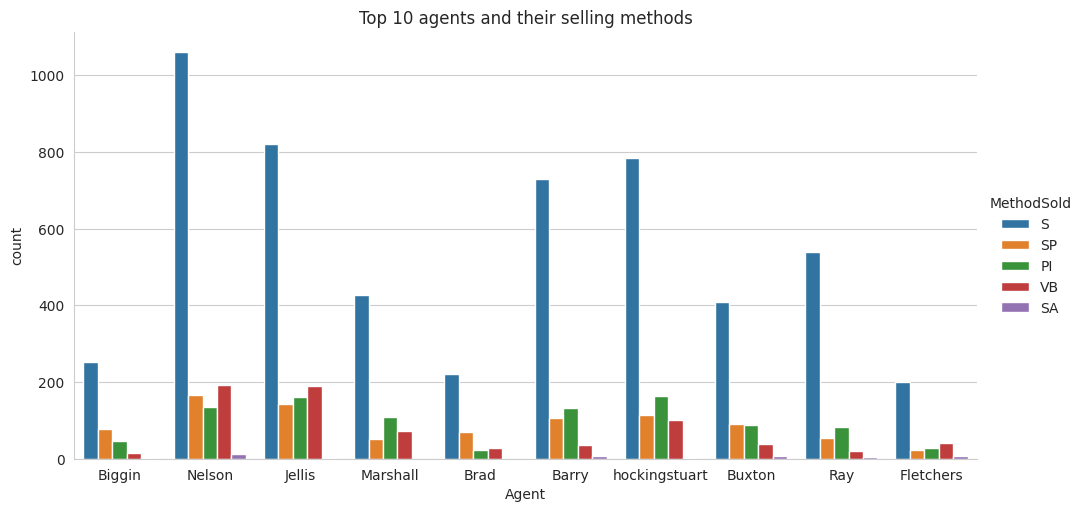

In [118]:
# Breaking down top 10 agent by MethodSold
top10_data = data.query("Agent in @top10.index")

# Plotting a bar chart
sns.catplot(data=top10_data, x="Agent", hue="MethodSold", kind="count", height=5, aspect=2)
plt.title("Top 10 agents and their selling methods")

Nelson seem to be the leader in most methods, though Jellis and hockingstuart take the lead in Passed In.

#### 3.2.7. DateSold

In [119]:
# convert DateSold to a datetime object
data["DateSold"] = pd.to_datetime(data["DateSold"], format="%d/%m/%Y")

Date has not much use to us, so let's group by month

In [120]:
month_avg = data.groupby(pd.Grouper(key="DateSold", freq="ME")).mean(numeric_only=True).reset_index()
month_avg.insert(0, "MonthYear", month_avg["DateSold"].apply(lambda x: x.strftime("%B-%Y"))) 
month_avg=month_avg.drop("DateSold", axis=1)
month_avg

,MonthYear,Rooms,Price,DistanceCBD,Postcode,Bedroom,Bathroom,Car,LandSize,BuildingSize,YearBuilt,Latitude,Longitude,PropertyCount
0,January-2016,2.500000,1.009000e+06,11.200000,3127.000000,2.500000,1.000000,2.000000,299.000000,NaN,NaN,-37.831850,145.101450,5457.000000
1,February-2016,2.615385,9.081827e+05,9.634615,3091.769231,2.615385,1.461538,1.769231,407.636364,111.647059,1981.950000,-37.823662,144.974665,5936.384615
2,March-2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,April-2016,2.855346,9.960432e+05,8.483333,3084.984277,2.783019,1.522013,1.493711,454.769531,131.274725,1954.943662,-37.797559,144.979750,7484.418239
4,May-2016,2.880979,1.046063e+06,8.466296,3096.985539,2.803115,1.509455,1.490545,470.462411,139.135458,1960.825480,-37.809664,144.987115,7488.048943
5,June-2016,2.887978,1.048369e+06,8.546311,3097.073770,2.795082,1.521858,1.539617,466.174603,135.815271,1960.800813,-37.811311,144.988468,7369.233607
6,July-2016,2.746637,9.412970e+05,8.740583,3091.322870,2.713004,1.396861,1.500000,460.077364,132.370044,1962.411150,-37.806171,144.979169,7154.089686
7,August-2016,2.783520,1.073529e+06,8.568017,3096.420391,2.712291,1.494413,1.486034,455.352313,132.356410,1962.307692,-37.810732,144.989718,7728.357542
8,September-2016,2.860541,1.099378e+06,8.482811,3096.088649,2.795676,1.548108,1.520000,472.245566,141.204887,1959.645631,-37.810434,144.990149,7512.380541
9,October-2016,2.767695,1.065341e+06,8.336116,3091.321234,2.740472,1.441016,1.533575,452.162162,137.784768,1958.991549,-37.807256,144.983567,7469.078040


Text(0.5, 1.0, 'Trend of Property Prices over Time')

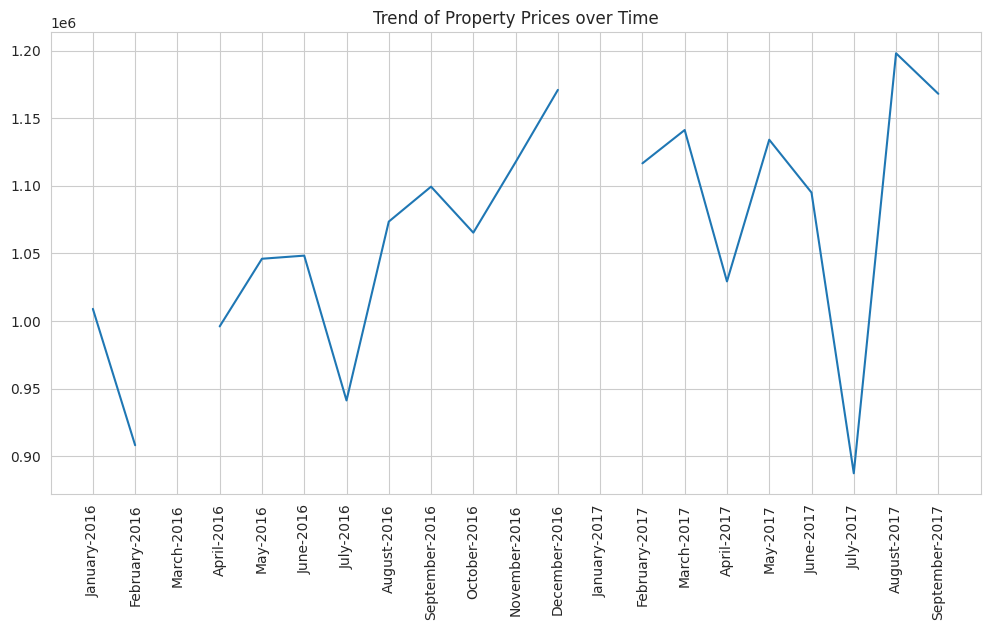

In [121]:
# plotting average prices for each month
plt.figure(figsize=(12, 6))
plt.plot(month_avg["MonthYear"], month_avg["Price"])
plt.xticks(rotation=90)
plt.title("Trend of Property Prices over Time")

As can be seen, there are some months without any properties sold. Property prices seemed to fluctuate a lot during the period.

### 3.3. Further correlation analysis

#### 3.3.1. Determining the correlation between house type and other parameters

In [122]:
# Copying the dataset and renaming
data_set_1 = data.copy(deep=True)
# Removing specific columns with alphanumerics
names = ["Address", "Suburb", "Type", "MethodSold", "Agent", "DateSold", "Council", "Region"]
for c in names:
    del data_set_1[c]

In [123]:
#Creating a dummy variable for 'Type'
data_set_2 = pd.get_dummies(data.Type)
data_set_2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   h       13580 non-null  bool 
 1   t       13580 non-null  bool 
 2   u       13580 non-null  bool 
dtypes: bool(3)
memory usage: 39.9 KB


The data available in the housing type is now in the format of boolean. However, to plot a correlation matrix numerical values should be present thus, these data types should be converted to integer format.

In [124]:
# Change booleans to integers for clearer correlation plots.
for property_type in ['h', 'u', 't']:
    if property_type in data_set_2.columns:
        data_set_2[property_type] = data_set_2[property_type].astype(int)

# Demonstrating the modified DataFrame without flooding the notebook output.
print('Modified DataFrame (first ten rows):')
print(data_set_2.head(10))

Modified DataFrame (first ten rows):
   h  t  u
0  1  0  0
1  1  0  0
2  1  0  0
3  1  0  0
4  1  0  0
5  1  0  0
6  1  0  0
7  1  0  0
8  0  0  1
9  1  0  0


Through the command 'astype' the DataFrame can be converted from boolean to integer. Once the DataFrame is converted, the correlation matrix can be plotted.

In [125]:
# Join the numeric property attributes and property-type dummy variables by row.
# The original vertical concatenation introduced unrelated rows and NaNs.
data_set_3 = pd.concat([data_set_1, data_set_2], axis=1)

# Display the first 10 rows of the DataFrame
data_set_3.head(10)

,Rooms,Price,DistanceCBD,Postcode,Bedroom,Bathroom,Car,LandSize,BuildingSize,YearBuilt,Latitude,Longitude,PropertyCount,h,t,u
0,2,1480000.0,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,-37.7996,144.9984,4019.0,1,0,0
1,2,1035000.0,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,-37.8079,144.9934,4019.0,1,0,0
2,3,1465000.0,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,-37.8093,144.9944,4019.0,1,0,0
3,3,850000.0,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,-37.7969,144.9969,4019.0,1,0,0
4,4,1600000.0,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,-37.8072,144.9941,4019.0,1,0,0
5,2,941000.0,2.5,3067.0,2.0,1.0,0.0,181.0,NaN,NaN,-37.8041,144.9953,4019.0,1,0,0
6,3,1876000.0,2.5,3067.0,4.0,2.0,0.0,245.0,210.0,1910.0,-37.8024,144.9993,4019.0,1,0,0
7,2,1636000.0,2.5,3067.0,2.0,1.0,2.0,256.0,107.0,1890.0,-37.8060,144.9954,4019.0,1,0,0
8,1,300000.0,2.5,3067.0,1.0,1.0,1.0,NaN,NaN,NaN,-37.8008,144.9973,4019.0,0,0,1
9,2,1097000.0,2.5,3067.0,3.0,1.0,2.0,220.0,75.0,1900.0,-37.8010,144.9989,4019.0,1,0,0


Using `pd.concat(..., axis=1)`, the numeric property columns and one-hot encoded house-type columns are joined horizontally by observation. This allows us to examine relationships between property type and the other numerical variables.

<Axes: title={'center': 'Correlation Matrix with respect to house type'}>

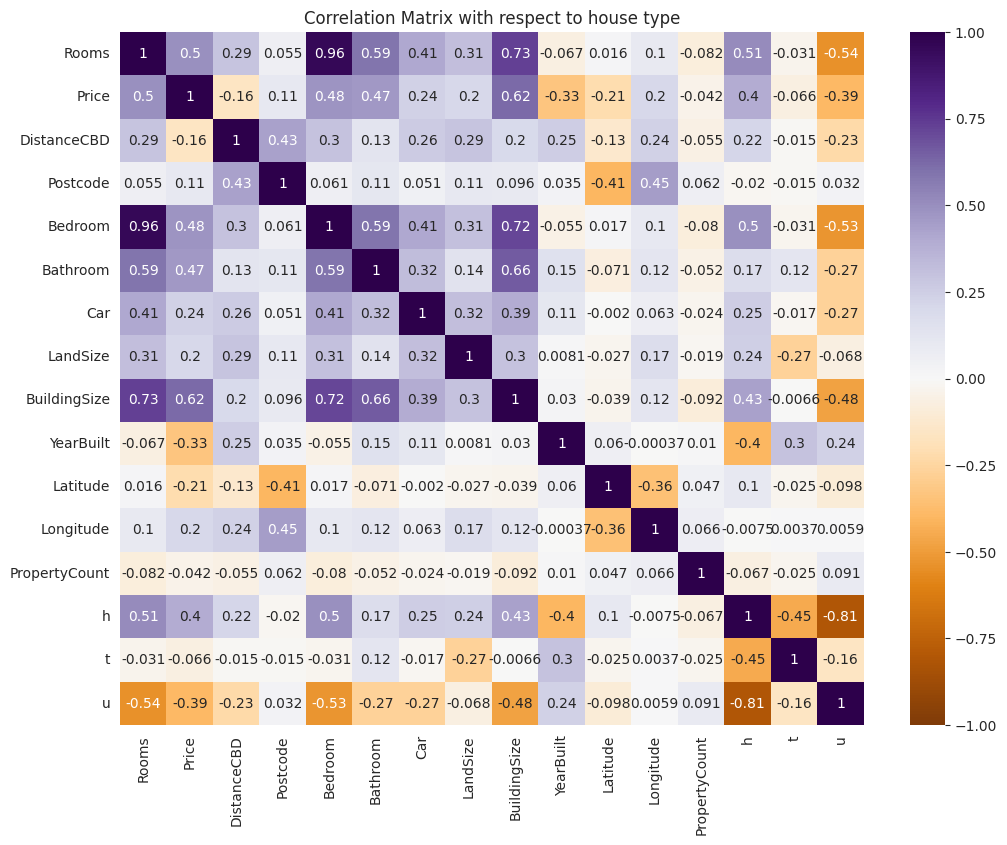

In [126]:
#Plotting and illustrating the corelation matrix
corr_matrix = data_set_3.corr(numeric_only=True)
corr_matrix
plt.figure (figsize = (12, 9))
plt.title("Correlation Matrix with respect to house type")

#Defining the parameters for the matrix
sns.heatmap (corr_matrix, vmin = -1, vmax = 1, center = 0, annot = True, cmap = "PuOr")

Through the following correlation matrix it can be seen that the type 'h' properties are having a positive trend towards the other parameters whilst the type 'u' and type 't' properties are having mostly a negative correlation with the other parameters. For an instance, it can be seen that there the number of rooms are highly correlated with the houses according to the dataset. However, it is negatively correlated with the units and townhouses.

Moreover, it can also concluded that the price is highly correlated with the type 'h' properties whilst it is negatively correlated with the other two types of houses. However, the built year of these houses demonstrate a positive correlation with units and townhouses whilst it is negatively correlated houses

Furthermore, it can also be seen that the parameters such as Lattitude, Longtitude, Land Size and the Building Area are slightly correlated with the any of these type of houses.

#### 3.3.2. Determining the correlation between the house location and the other parameters

In [127]:
#Creating a dummy variable for 'Region'
data_set_4 = pd.get_dummies(data.Region)
data_set_4.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Eastern Metropolitan        13580 non-null  bool 
 1   Eastern Victoria            13580 non-null  bool 
 2   Northern Metropolitan       13580 non-null  bool 
 3   Northern Victoria           13580 non-null  bool 
 4   South-Eastern Metropolitan  13580 non-null  bool 
 5   Southern Metropolitan       13580 non-null  bool 
 6   Western Metropolitan        13580 non-null  bool 
 7   Western Victoria            13580 non-null  bool 
dtypes: bool(8)
memory usage: 106.2 KB


In [128]:
#Demonstrating the Dummy DataFrame
data_set_4

,Eastern Metropolitan,Eastern Victoria,Northern Metropolitan,Northern Victoria,South-Eastern Metropolitan,Southern Metropolitan,Western Metropolitan,Western Victoria
0,False,False,True,False,False,False,False,False
1,False,False,True,False,False,False,False,False
2,False,False,True,False,False,False,False,False
3,False,False,True,False,False,False,False,False
4,False,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...
13575,False,False,False,False,True,False,False,False
13576,False,False,False,False,False,False,True,False
13577,False,False,False,False,False,False,True,False
13578,False,False,False,False,False,False,True,False


The dummy variables are already in integer format, so correlation analysis can be conducted.

In [129]:
# Join region dummy variables and existing numeric attributes by row index.
data_set_5 = pd.concat([data_set_1, data_set_4], axis=1)

# Display the first 10 rows of the DataFrame
data_set_5.head(10)

,Rooms,Price,DistanceCBD,Postcode,Bedroom,Bathroom,Car,LandSize,BuildingSize,YearBuilt,Latitude,Longitude,PropertyCount,Eastern Metropolitan,Eastern Victoria,Northern Metropolitan,Northern Victoria,South-Eastern Metropolitan,Southern Metropolitan,Western Metropolitan,Western Victoria
0,2,1480000.0,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,-37.7996,144.9984,4019.0,False,False,True,False,False,False,False,False
1,2,1035000.0,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,-37.8079,144.9934,4019.0,False,False,True,False,False,False,False,False
2,3,1465000.0,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,-37.8093,144.9944,4019.0,False,False,True,False,False,False,False,False
3,3,850000.0,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,-37.7969,144.9969,4019.0,False,False,True,False,False,False,False,False
4,4,1600000.0,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,-37.8072,144.9941,4019.0,False,False,True,False,False,False,False,False
5,2,941000.0,2.5,3067.0,2.0,1.0,0.0,181.0,NaN,NaN,-37.8041,144.9953,4019.0,False,False,True,False,False,False,False,False
6,3,1876000.0,2.5,3067.0,4.0,2.0,0.0,245.0,210.0,1910.0,-37.8024,144.9993,4019.0,False,False,True,False,False,False,False,False
7,2,1636000.0,2.5,3067.0,2.0,1.0,2.0,256.0,107.0,1890.0,-37.8060,144.9954,4019.0,False,False,True,False,False,False,False,False
8,1,300000.0,2.5,3067.0,1.0,1.0,1.0,NaN,NaN,NaN,-37.8008,144.9973,4019.0,False,False,True,False,False,False,False,False
9,2,1097000.0,2.5,3067.0,3.0,1.0,2.0,220.0,75.0,1900.0,-37.8010,144.9989,4019.0,False,False,True,False,False,False,False,False


The region dummy variables are joined horizontally to the original numeric property attributes using `pd.concat(..., axis=1)`. We can then investigate correlations involving the location categories.

<Axes: title={'center': 'Correlation Matrix with respect to Region of the houses'}>

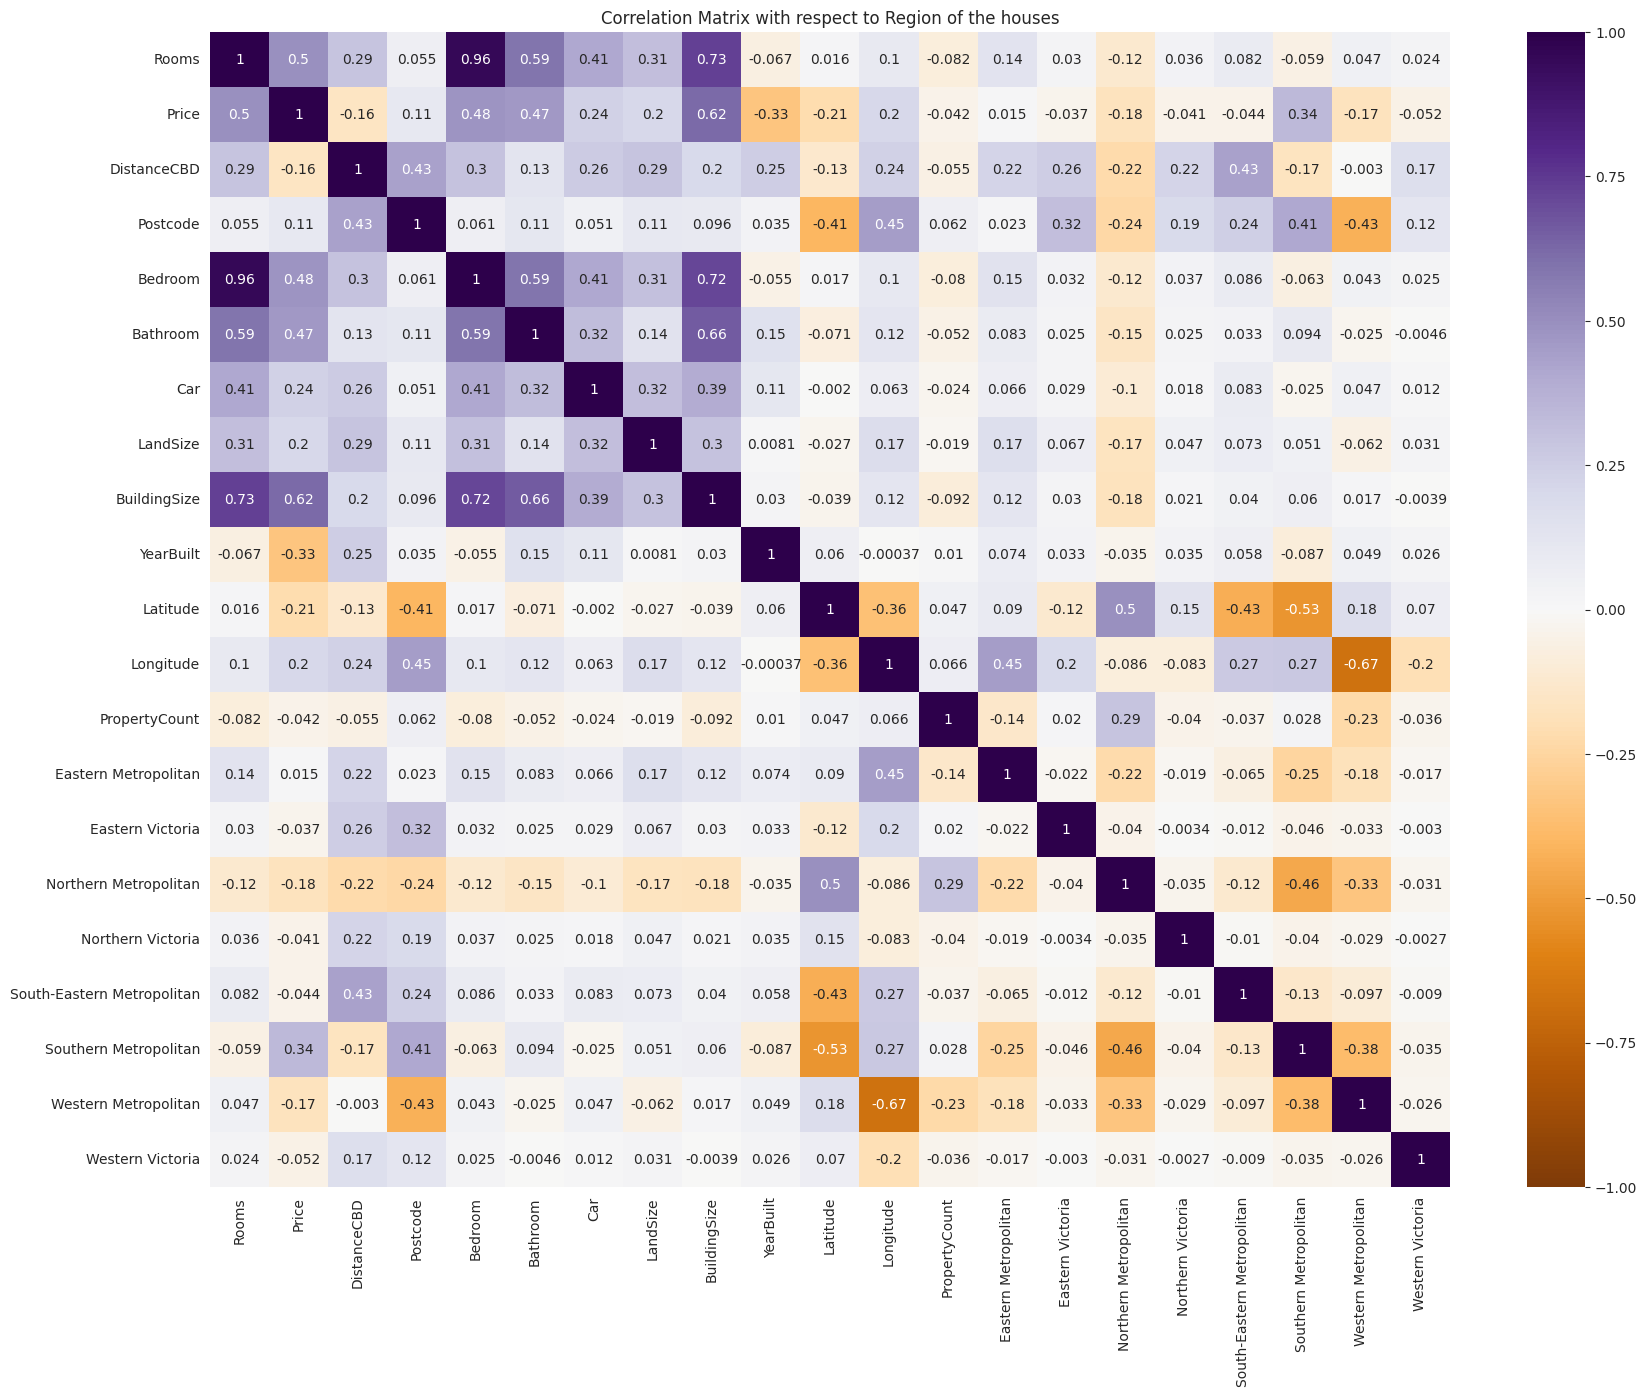

In [130]:
#Plotting and illustrating the corelation matrix
corr_matrix = data_set_5.corr(numeric_only=True)
corr_matrix
plt.figure (figsize = (20, 15))
plt.title("Correlation Matrix with respect to Region of the houses")

#Defining the parameters for the matrix
sns.heatmap(corr_matrix, vmin = -1, vmax = 1, center = 0, annot = True, cmap = "PuOr")

When the correlation matrix is been plotted there can be seen some of the Region areas are highly correlated with several factors. For an example, South Eastern Metropolitan region is highly correlated with the distance which subsequently refers to that the South-Eastern Metropolitain region is having a strong relationship with the Distance parameter. However, when Southern Metropolitan region is been considered, it can be seen that it is having a negative correlation between the distance which subsequently refers that the relationship between this region and the distance does not have a very strong relationship.

When the correlation between the number of rooms in these regions are taken in to consideration, it can be seen that the rooms are not desnly correlated with the any of the regions and when the price is been considered it can be seen a negative correlation between the sold price and the these district. Moreover, when the car parking slots of the houses which have been sold in these areas are taken in to consideration, it can be seen that the Nothern Metropolitan area and the Southern Metropolitan area are showing a negative correlation apart from the other regions. Thus, it is clear that most of the houses which have been sold in these regions does not consist of car parking slots.

Furthermore, when the Bedrooms in the properties which have been sold were taken in to consideration, it can be seen that the Eastern Metropolitan region is showing a high correlation when it is been compared to the other regions. However, it can also been seen that the Nothern Metropolitan region and the Southern Metropolitan region illustrates a negative correlation with the parameter 'Bedrooms' which subsequently refers to that, as a whole the number of bedrooms available in the Eastern Metropolitan region are higher than the other regions and the number of bedrooms available in the Nothern and Southern metropolitan regions are significantly lower than in the other regions.

In addition, when the building area, the Land size and the year built is been taken in to consideration, there cannot be seen a significant correlation between these parameters and the Region names according to the following dataset.

## 4. Machine Learning for Price Prediction

### Data preparation

To avoid data leakage, the exploratory cleaning above is not reused for modelling. The predictive models start with the separately preserved original records, use one reproducible 80/20 training/test split, and fit imputers and category encoders inside scikit-learn pipelines. Candidate models are compared using five-fold cross-validation **only on the training portion**. The test set is evaluated once, at the end, for the selected model.

In [131]:
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.svm import LinearSVR  # Scalable linear support-vector regression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone
import xgboost as xgb

In [132]:
# Use the untouched, renamed source records rather than globally imputed EDA data.
model_data = model_source.copy(deep=True)
# Apply only the two address-specific corrections investigated earlier.
model_data.loc[((model_data['Address'] == '5 Grange Rd') &
                (model_data['Suburb'] == 'Caulfield East') &
                (model_data['Bedroom'] == 20)), 'Bedroom'] = 2
# An implausible construction year is treated as missing rather than guessed.
model_data.loc[model_data['YearBuilt'] < 1700, 'YearBuilt'] = np.nan
# Small/zero area measurements are missing, not legitimate zeros for modelling.
for col in ['LandSize', 'BuildingSize']:
    model_data.loc[model_data[col] < 10, col] = np.nan

# Retain the same numeric predictors and the Council category as the original model.
numeric_predictors = model_data.select_dtypes(include='number').columns.drop('Price').tolist()
base_categorical_predictors = ['Council']
model_data[numeric_predictors + base_categorical_predictors + ['Price']].head()

,Rooms,DistanceCBD,Postcode,Bedroom,Bathroom,Car,LandSize,BuildingSize,YearBuilt,Latitude,Longitude,PropertyCount,Council,Price
0,2,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,-37.7996,144.9984,4019.0,Yarra,1480000.0
1,2,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,-37.8079,144.9934,4019.0,Yarra,1035000.0
2,3,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,-37.8093,144.9944,4019.0,Yarra,1465000.0
3,3,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,-37.7969,144.9969,4019.0,Yarra,850000.0
4,4,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,-37.8072,144.9941,4019.0,Yarra,1600000.0


In [133]:
# Select input features and the target without learning any statistics yet.
features = model_data[numeric_predictors + base_categorical_predictors].copy()
target = model_data['Price'].copy()
assert len(features) == len(target) == 13580

In [134]:
# All learned transformations are encapsulated in a pipeline, fitted separately
# inside each CV fold and later on the training set (never on the test set).
def make_preprocessor(include_type=False):
    categorical = base_categorical_predictors + (['Type'] if include_type else [])
    numeric_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median', add_indicator=True))
    ])
    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Unavailable')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    return ColumnTransformer([
        ('numeric', numeric_pipeline, numeric_predictors),
        ('categorical', categorical_pipeline, categorical)
    ], sparse_threshold=0.0)

In [135]:
# Replace any infinite values with NaN; numeric imputers handle them per fold.
model_data[numeric_predictors] = model_data[numeric_predictors].replace([np.inf, -np.inf], np.nan)
print('Missing input cells (before train-only imputation):',
      int(model_data[numeric_predictors + base_categorical_predictors].isna().sum().sum()))

Missing input cells (before train-only imputation): 15274


In [136]:
# Preserve the original 80/20 random split (random_state=42).
X_train, X_test, y_train, y_test = train_test_split(
    model_data, model_data['Price'], test_size=0.20, random_state=42
)
# The untouched test set is not used during model development or selection.
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}
fitted_models = {}

def evaluate_on_training(name, candidate):
    """Compare models using training-only cross-validation, then fit to all training rows."""
    scores = cross_validate(
        candidate, X_train, y_train, cv=cv,
        scoring={'r2': 'r2', 'rmse': 'neg_root_mean_squared_error',
                 'mae': 'neg_mean_absolute_error'},
        n_jobs=1, error_score='raise'
    )
    cv_results[name] = {
        'CV R2': scores['test_r2'].mean(),
        'CV RMSE (AUD)': -scores['test_rmse'].mean(),
        'CV MAE (AUD)': -scores['test_mae'].mean(),
        'CV R2 std': scores['test_r2'].std()
    }
    candidate.fit(X_train, y_train)
    fitted_models[name] = candidate
    print(f"{name}: CV R²={cv_results[name]['CV R2']:.3f} "
          f"(±{cv_results[name]['CV R2 std']:.3f}), "
          f"RMSE=A${cv_results[name]['CV RMSE (AUD)']:,.0f}, "
          f"MAE=A${cv_results[name]['CV MAE (AUD)']:,.0f}")

print('Training records:', len(X_train), '| Held-out test records:', len(X_test))

Training records: 10864 | Held-out test records: 2716


### Linear Regression

In [137]:
# Linear regression baseline with fold-specific imputation and Council encoding.
linear_model = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', LinearRegression())
])
evaluate_on_training('Linear Regression', linear_model)

Linear Regression: CV R²=0.524 (±0.108), RMSE=A$439,714, MAE=A$274,181

Linear regression estimates a linear relationship between the input variables and property prices. Here, the metrics are calculated from five-fold cross-validation on the training set, not from repeated access to the held-out test set. This provides an initial interpretable benchmark for the more flexible models.

### Support vector regression


In [138]:
# LinearSVR implements a scalable linear support-vector regression objective.
# Standardising both features and the large AUD target avoids poor optimisation.
svr_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ('preprocess', make_preprocessor()),
        ('scale', StandardScaler()),
        ('model', LinearSVR(random_state=42, max_iter=5000,
                            loss='squared_epsilon_insensitive', dual=False))
    ]),
    transformer=StandardScaler()
)
evaluate_on_training('Linear Support Vector Regression', svr_model)

Linear Support Vector Regression: CV R²=0.524 (±0.108), RMSE=A$439,712, MAE=A$274,174


Support Vector Regression (SVR) seeks a linear prediction function while penalising errors outside an epsilon-insensitive region. We use the computationally efficient `LinearSVR` formulation, with scaled predictors and a scaled target, to handle this dataset more reliably. An R² score of 0 corresponds to a mean-prediction benchmark on the evaluated data; **only a negative R²** is worse than that benchmark. We compare the five-fold validation results above rather than relying on a single split.

### Gradient boosting

In [139]:
# Gradient-boosted regression trees using fixed, reproducible settings.
xgb_settings = dict(n_estimators=180, max_depth=4, learning_rate=0.06,
                    subsample=0.85, colsample_bytree=0.85,
                    objective='reg:squarederror', tree_method='hist',
                    random_state=42, n_jobs=2)
xgb_model = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', xgb.XGBRegressor(**xgb_settings))
])
evaluate_on_training('XGBoost', xgb_model)

XGBoost: CV R²=0.775 (±0.029), RMSE=A$303,010, MAE=A$185,278


XGBoost combines decision trees using gradient boosting and can capture nonlinear patterns in housing prices. The evaluation above reports training-only five-fold cross-validation rather than an optimistically selected test-set score. Its validation accuracy and error should be assessed relative to the linear and support-vector alternatives. Large absolute prediction errors can remain despite a reasonable R², especially for unusually expensive properties.

### Reiterating

We can perform one-hot encoding on the additional `Type` variable to see whether it improves the models. The new categorical encoding is learned within each training fold so that the held-out test data remain unseen during model selection.

In [140]:
# Compare the same input attributes with the additional property Type category.
# OneHotEncoder is fitted within each CV fold, avoiding test-set category leakage.
features_with_type = model_data[numeric_predictors + ['Council', 'Type']].copy()
features_with_type.head()

,Rooms,DistanceCBD,Postcode,Bedroom,Bathroom,Car,LandSize,BuildingSize,YearBuilt,Latitude,Longitude,PropertyCount,Council,Type
0,2,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,-37.7996,144.9984,4019.0,Yarra,h
1,2,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,-37.8079,144.9934,4019.0,Yarra,h
2,3,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,-37.8093,144.9944,4019.0,Yarra,h
3,3,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,-37.7969,144.9969,4019.0,Yarra,h
4,4,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,-37.8072,144.9941,4019.0,Yarra,h


In [141]:
# Reuse the identical train/test partition and the same training-only CV folds.
# Adding Type is the sole intended change to the feature list.
assert set(X_train.index).isdisjoint(X_test.index)
print('Additional predictor: Type')

Additional predictor: Type


In [142]:
linear_type_model = Pipeline([
    ('preprocess', make_preprocessor(include_type=True)),
    ('model', LinearRegression())
])
evaluate_on_training('Linear Regression + Type', linear_type_model)

Linear Regression + Type: CV R²=0.573 (±0.083), RMSE=A$417,504, MAE=A$260,467


XGBoost + Type: CV R²=0.796 (±0.030), RMSE=A$288,815, MAE=A$173,923

Training-only cross-validation comparison (sorted by RMSE):
                                  CV R2  CV RMSE (AUD)  CV MAE (AUD)  CV R2 std
XGBoost + Type                    0.796     288815.293    173923.080      0.030
XGBoost                           0.775     303009.576    185277.662      0.029
Linear Regression + Type          0.573     417503.615    260467.330      0.083
Linear Support Vector Regression  0.524     439711.986    274174.491      0.108
Linear Regression                 0.524     439713.601    274180.570      0.108

Selected model: XGBoost + Type
Final held-out test R²: 0.8174
Final held-out test RMSE: A$269,347.86
Final held-out test MAE: A$172,488.79
Mean-price baseline test RMSE: A$630,259.30
Mean-price baseline test R²: -0.0000


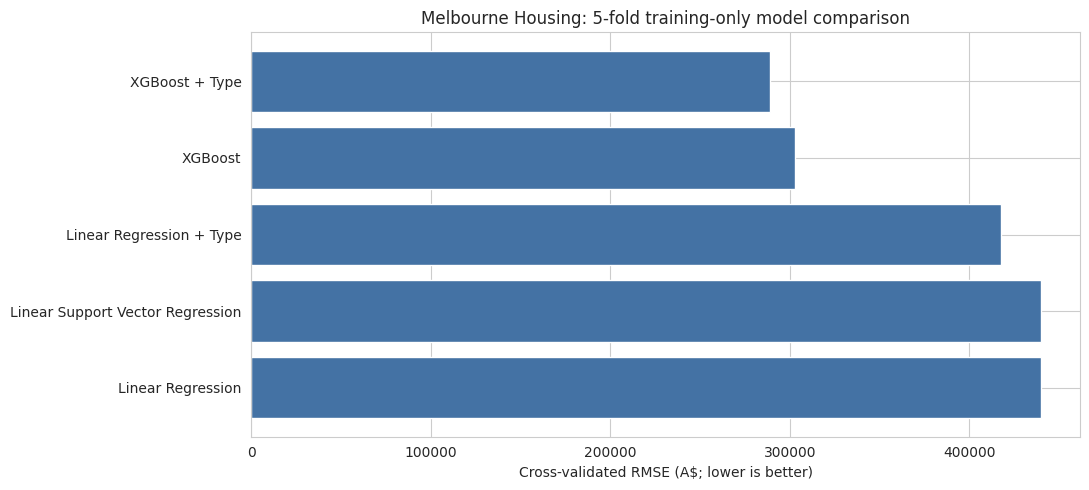

In [143]:
xgb_type_model = Pipeline([
    ('preprocess', make_preprocessor(include_type=True)),
    ('model', xgb.XGBRegressor(**xgb_settings))
])
evaluate_on_training('XGBoost + Type', xgb_type_model)

# Select the best validation candidate BEFORE touching the hold-out test set.
comparison = pd.DataFrame.from_dict(cv_results, orient='index').sort_values('CV RMSE (AUD)')
print('\nTraining-only cross-validation comparison (sorted by RMSE):')
print(comparison.round(3).to_string())
best_name = comparison.index[0]
best_model = fitted_models[best_name]

# Once-only final performance assessment of the validation-selected model.
test_predictions = best_model.predict(X_test)
test_rmse = float(np.sqrt(mean_squared_error(y_test, test_predictions)))
test_mae = float(mean_absolute_error(y_test, test_predictions))
test_r2 = float(r2_score(y_test, test_predictions))

# Transparent baseline evaluated on the exact same test partition.
baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)
print(f'\nSelected model: {best_name}')
print(f'Final held-out test R²: {test_r2:.4f}')
print(f'Final held-out test RMSE: A${test_rmse:,.2f}')
print(f'Final held-out test MAE: A${test_mae:,.2f}')
print(f'Mean-price baseline test RMSE: A${np.sqrt(mean_squared_error(y_test, baseline_predictions)):,.2f}')
print(f'Mean-price baseline test R²: {r2_score(y_test, baseline_predictions):.4f}')

# Keep a self-contained model comparison visual in the existing last code cell.
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(comparison.index[::-1], comparison['CV RMSE (AUD)'][::-1], color='#4472a4')
ax.set_xlabel('Cross-validated RMSE (A$; lower is better)')
ax.set_title('Melbourne Housing: 5-fold training-only model comparison')
fig.tight_layout()
plt.show()

We have now compared Linear Regression, Support Vector Regression, and XGBoost, including variations with the additional `Type` feature, using five-fold cross-validation on the training data. The final code cell prints a consistent comparison of R², RMSE, and MAE, selects the model with the lowest validation RMSE, and evaluates that model **once** on the previously untouched test set. A mean-price baseline provides useful context.

**Interpretation and limitations:** This snapshot covers property sales from 2016–2017. The findings describe historical transactions rather than current Melbourne house prices. Predictions may be affected by incomplete building information, geographic differences, rare expensive properties, and changes in the housing market since the observations were collected. Cross-validation on historical observations does not guarantee future forecasting accuracy.

**Reproduced final result:** Based on the lowest training cross-validation RMSE, XGBoost with property `Type` was selected. On the untouched 2,716-record test set, it achieved **R² = 0.8174**, **RMSE = A$269,347.86**, and **MAE = A$172,488.79**. The simple mean-price baseline had a test RMSE of **A$630,259.30**. These figures apply only to the supplied historical snapshot and are not claims about current Australian property prices.